# Tarea 2: Kafka y Spark Structured Streaming

**Curso:** Big Data — Pontificia Universidad Católica de Valparaíso  
**Continuidad:** US Flight Data 2024 (Tarea 1)  
**Integrantes:** Lur López, Paula Eguileor y Lucas Stille  
**Entrega:** 27 de octubre de 2026
**Link Github:** https://github.com/LurLopez/BigDataTarea2
>

## 1. Objetivos

- Extender el proyecto desarrollado en la Tarea 1 hacia una arquitectura de procesamiento continuo, manteniendo el dominio, el conjunto de datos y parte de las preguntas analíticas ya construidas.
- Utilizar Apache Kafka como fuente de eventos y Spark Structured Streaming como motor de procesamiento distribuido del flujo.
- Diseñar y justificar tópicos, particiones, claves de particionado y una arquitectura Kafka con KRaft, distinguiendo entre una implementación local de laboratorio y una propuesta hipotética escalable.
- Traducir análisis realizados en modo batch en la Tarea 1 a consultas de streaming, identificando qué elementos se mantienen, cuáles cambian y por qué.
- Trabajar con tiempo de evento, ventanas deslizantes, watermark, estado, offsets y checkpointing.
- Medir capacidad de procesamiento, latencia y comportamiento ante aumentos en la tasa de llegada, identificando cuellos de botella de la arquitectura.
- Comprender la recuperación ante fallos y la relación entre persistencia en Kafka, offsets y checkpoints de Spark.


## 2. Descripción general

Esta tarea es una continuación directa de la Tarea 1. El grupo no debe construir un proyecto completamente nuevo: debe reutilizar el mismo dominio y, salvo justificación fundada, el mismo conjunto de datos.

En la Tarea 1 el flujo principal fue de naturaleza batch: preparación del conjunto de datos, persistencia y análisis posterior con PySpark. En esta segunda tarea, el objetivo es reinterpretar parte de ese trabajo como un sistema de eventos que llegan continuamente.

Para ello, el grupo deberá construir un flujo general como el siguiente:

```text
Dataset Tarea 1 → Producer → Kafka / Topic(s) → Spark Structured Streaming → resultados / métricas / salida
```

El dataset histórico utilizado en la Tarea 1 puede ser reproducido como un flujo de eventos. Cada fila o unidad lógica del dataset podrá transformarse en uno o más eventos, conservando sus atributos relevantes y un timestamp de evento.

Se evalúa principalmente el criterio de diseño: qué se convierte en evento, cómo se particiona, qué consulta continua se ejecuta, qué estado mantiene Spark, cómo se mide el rendimiento y cómo se interpreta el resultado. La sintaxis por sí sola no constituye un análisis.


## 3. Continuidad Tarea 1 → Tarea 2

La fuente sigue siendo **US Flight Data 2024**, publicado en Kaggle por Hrishit Patil y basado en datos del Bureau of Transportation Statistics (BTS), U.S. Department of Transportation. En Tarea 1 se trabajó con 7.079.081 vuelos y 348 aeropuertos.

| Elemento de Tarea 1 | Equivalente en Tarea 2 | Qué se mantiene y qué cambia |
|---|---|---|
| `fact_flights` y `dim_airports` en Parquet, 7.079.081 filas de US Flight Data 2024 | Fuente de eventos → topic Kafka | Mismo dominio y mismo dataset. El Parquet o CSV se reproduce como eventos; el estado del origen se puede enriquecer desde `dim_airports`. |
| Una fila de `fact_flights` representa un vuelo | Evento `flight_observed` | Se mantiene un vuelo por registro. El payload añade key, `event_time`, `event_id`, versión y hora de ingestión. |
| Dask limpia tipos, nulos y duplicados; Parquet se particiona por mes | Producer por lotes + particiones Kafka | La limpieza de T1 se reutiliza. La partición mensual de archivos no sustituye las particiones de Kafka. |
| Join de vuelos con `dim_airports` | `origin_state` en el payload | Se mantiene el estado para agrupar. Al ser una dimensión estática pequeña, el Producer la incorpora; no hace falta un join de dos streams. |
| GroupBy y estadísticas batch por estado | Consulta streaming 1 | Mismas métricas (`count`, media, desviación, máximo); pasan a ser acumulados provisionales conforme entran vuelos. |
| `dense_rank` de aerolíneas en ATL, DFW y ORD | Consulta streaming 2 | Se mantienen los hubs, el mínimo de 500 vuelos y el ranking. Se recalcula sobre el snapshot agregado disponible hasta el momento. |
| Análisis sobre la tabla completa de 2024 | Consulta streaming 3 con event-time | Se sustituye el grupo anual por ventanas deslizantes de 6 h / 1 h y watermark de 3 h. |
| Resultado final de PySpark y gráficos | Snapshots Parquet por micro-batch + métricas JSONL | Los resultados evolucionan; Spark conserva offsets/estado en checkpoints para reanudar. |
| Particiones Parquet por `month` | Particiones Kafka por key | Se mantiene el objetivo de distribuir; cambia la unidad y el mecanismo de particionado. |

### Dos preguntas batch reformuladas

1. **T1:** ¿Qué estados tienen mayor retraso promedio de salida y variabilidad? **T2:** ¿Qué estados lideran ese ranking con los vuelos recibidos hasta este micro-batch? Se conservan las métricas y el filtro de más de 10.000 vuelos, pero el ranking es parcial y cambia con las llegadas.
2. **T1:** ¿Qué aerolíneas son más puntuales en ATL, DFW y ORD? **T2:** ¿Cuál es el top 3 por retraso promedio de llegada con los registros acumulados hasta ahora? Se mantiene el mínimo de 500 vuelos; un grupo no entra al ranking hasta alcanzar ese volumen.

El histórico cubre 2024 completo, pero su reproducción controlada no equivale a una fuente de vuelos en vivo. La consulta de ventanas sí ilustra qué cambia cuando las decisiones dependen de tiempo de evento y datos tardíos.


## 4. Actividades

### 4.1 Diseño de la arquitectura

El diseño mantiene el flujo general solicitado:

```text
Dataset Tarea 1 → Producer → Kafka / flights.events → Spark Structured Streaming → sink
```

La misma arquitectura lógica se presenta en dos despliegues: uno reducido para el laboratorio de Colab y otro hipotético para un entorno escalable con alta disponibilidad.

### 4.1.1 Diagrama de arquitectura

<p align="center">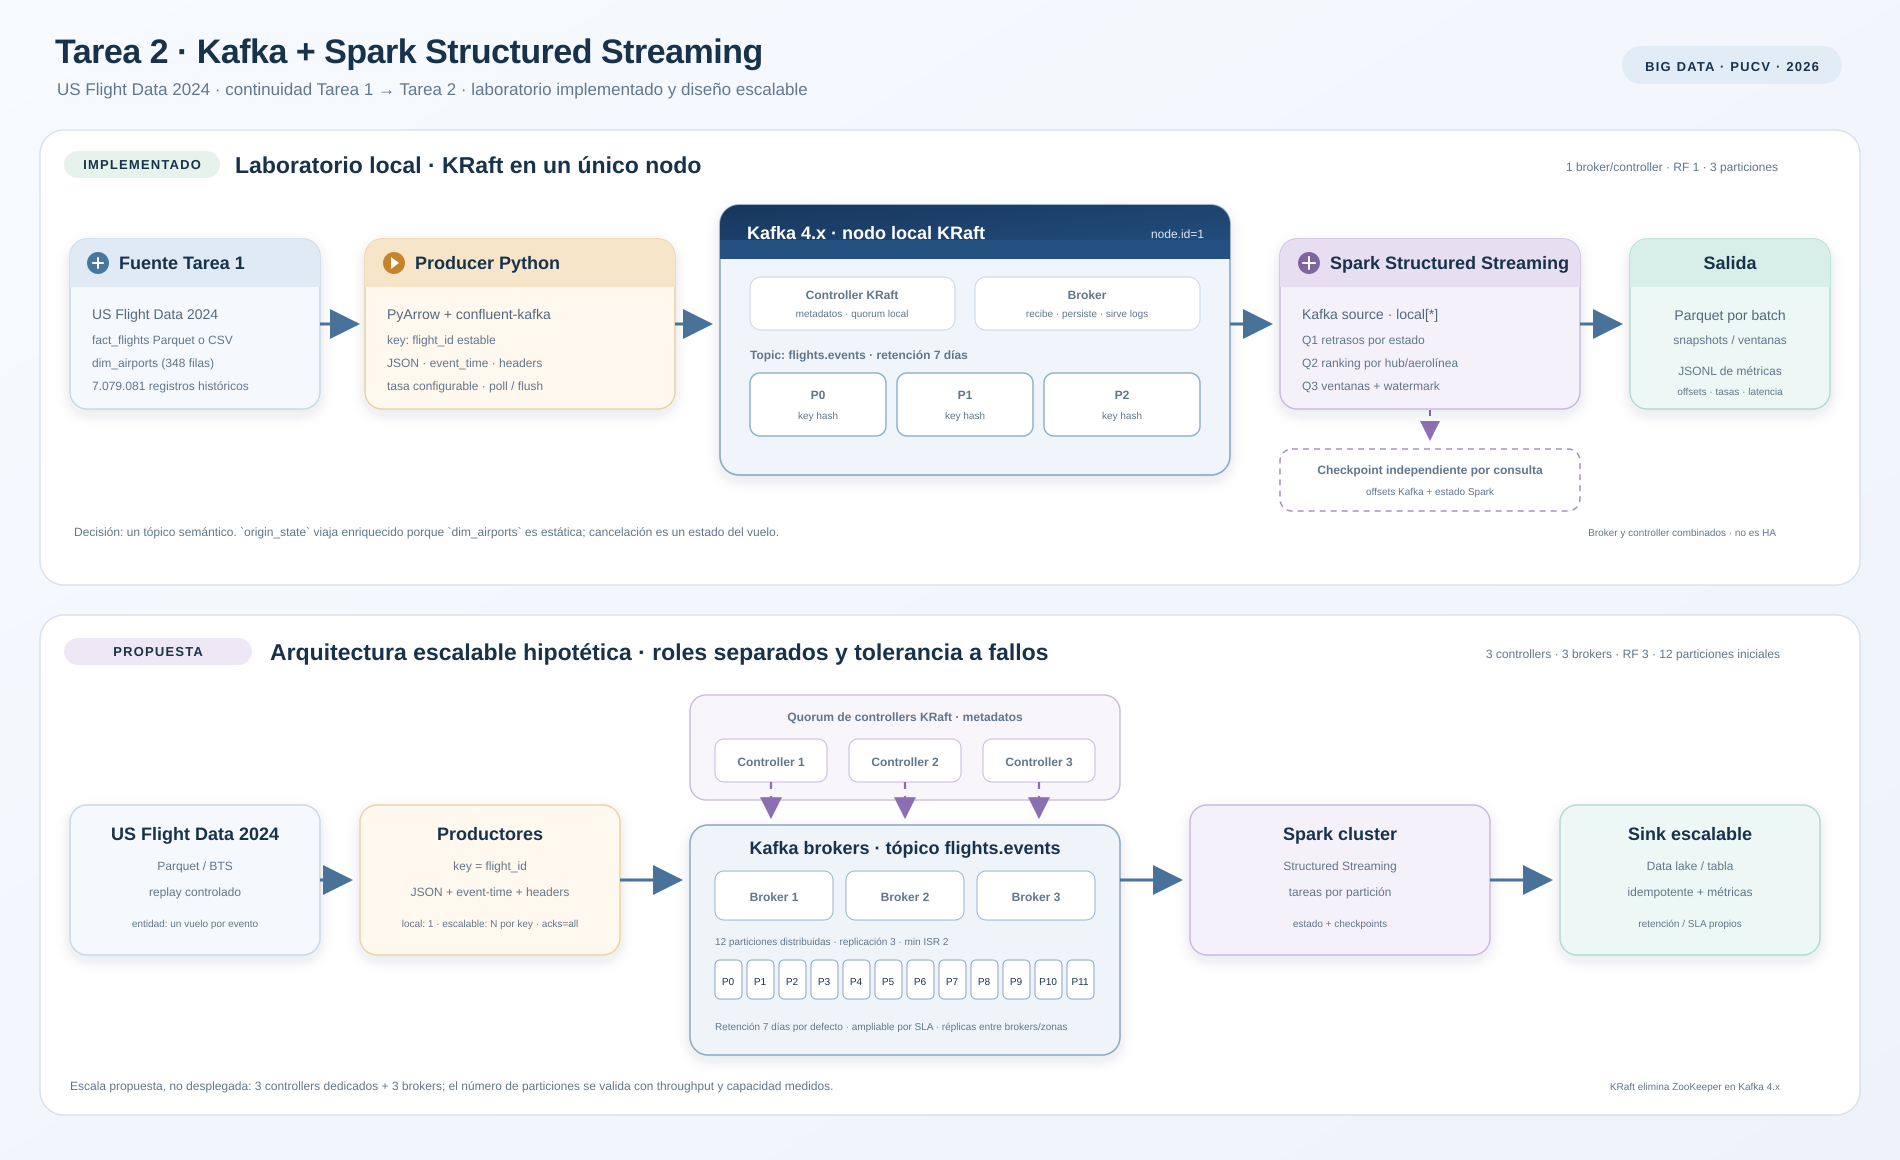</p>

**Figura 1.** Arquitectura de laboratorio y propuesta escalable. La versión editable se entrega como `arquitectura.svg`; la imagen se entrega como `arquitectura.png`.

La parte superior muestra la configuración que se ejecuta en el laboratorio: un único nodo que combina broker y controller KRaft, un topic con tres particiones y replication factor 1. La parte inferior es una propuesta hipotética: tres brokers, tres controllers dedicados, doce particiones y replication factor 3. **La propuesta escalable no se despliega en Colab**; se justifica como diseño.

### 4.1.2 Configuración del laboratorio local

| Componente | Decisión |
|---|---|
| Producer | Un proceso Python que publica eventos de vuelo desde la fuente de Tarea 1. |
| Kafka | Kafka 4.x en modo KRaft, con un único nodo que cumple los roles de broker y controller. |
| Topic | `flights.events`. |
| Particiones | 3. |
| Replication factor | 1. |
| Retención | 7 días. |
| Consumidor | Spark Structured Streaming, con tres consultas independientes y un checkpoint por consulta. |
| Sink | Parquet por micro-batch para resultados, JSONL para métricas y consola para depuración. |

El laboratorio prioriza la ejecución funcional completa en un entorno efímero y con recursos limitados. No pretende ofrecer alta disponibilidad: la caída del nodo implicaría la pérdida del broker, del controller y de los datos en tránsito. Esa limitación es asumida y se corrige en la propuesta escalable.

### 4.1.3 Propuesta escalable

| Componente | Decisión |
|---|---|
| Brokers | 3. |
| Controllers KRaft | 3 dedicados. |
| Topic | `flights.events`. |
| Particiones | 12 iniciales, revisables con el experimento de capacidad. |
| Replication factor | 3. |
| Mínimo de réplicas sincronizadas | `min.insync.replicas=2`. |
| Retención | 7 días; el almacenamiento de largo plazo corresponde al sink. |
| Spark | Clúster de Spark; el número de ejecutores se ajusta con la tasa y el benchmark. |
| Sink | Data lake u object storage con salida duradera; en producción, tabla transaccional o `MERGE` para upsert. |

Con tres brokers y `replication.factor=3`, cada una de las 12 particiones tiene una réplica en cada broker: 36 réplicas en total, 12 por broker. La caída de un broker deja dos réplicas disponibles y permite seguir escribiendo mientras se mantenga el mínimo de dos réplicas sincronizadas. La caída de dos brokers haría que las particiones afectadas no cumplan ese mínimo.

### 4.1.4 Decisiones de diseño y justificación

#### Número de topics: uno

Se propone **un único topic**, `flights.events`.

Todos los mensajes representan el mismo dominio semántico: un vuelo observado. Las tres consultas pueden consumir el mismo flujo y no requieren políticas de retención, seguridad u ownership diferentes. La tasa de eventos no justifica crear topics: el paralelismo se gestiona con particiones y recursos.

| Alternativa descartada | Motivo |
|---|---|
| `flights.cancelled` | La cancelación es un atributo del vuelo, no un flujo independiente. Separarla dificultaría mantener juntos los eventos de una misma entidad. |
| `airports.reference` | `dim_airports` es una dimensión estática pequeña; su información se incorpora al vuelo. Un topic de referencia solo se justificaría si el catálogo cambiara de forma independiente y Spark lo consumiera como dimensión. |
| Un topic por consulta | Las tres consultas pueden leer el mismo stream; duplicar los vuelos no aporta valor. |

#### Número de particiones: 3 en local y 12 en escalable

En el laboratorio se usan **3 particiones**. Es un número suficiente para demostrar lectura paralela con los recursos limitados de Colab, mantiene una distribución razonable de la key `flight_id` y no genera demasiadas tareas pequeñas. Una sola partición limitaría la etapa de lectura a una única tarea y ocultaría el efecto del paralelismo en el experimento de capacidad.

En la propuesta escalable se parte de **12 particiones iniciales** distribuidas entre 3 brokers, con RF 3. No es un número deducido del volumen total de 7 millones de vuelos, sino una estimación inicial basada en la tasa pico esperada y en la capacidad que pueda sostener cada partición. El número definitivo debe validarse con el experimento de capacidad.

La relación orientativa es:

```text
particiones >= tasa pico esperada / eventos por segundo sostenibles por partición
```

#### Key: identificador estable del vuelo

La key es:

```text
fl_date | op_unique_carrier | op_carrier_fl_num | origin | crs_dep_time
```

Es la misma identificación compuesta que se usó en Tarea 1 para analizar duplicados. `origin | dest | fecha` no basta, porque puede haber varios vuelos en la misma ruta y día. Si en el futuro se publicaran varios eventos de un mismo vuelo —por ejemplo, programado y cancelado—, la misma key los mantendría juntos en una partición y conservaría su orden.

La key no deduplica por sí sola. Kafka la usa para decidir la partición; la deduplicación, si se implementa, corresponde al consumidor o al sink.

#### Replication factor: 1 en local y 3 en escalable

En el laboratorio se usa **RF=1** porque solo hay un broker y no existe otro lugar donde almacenar réplicas. Es una decisión de entorno, no una recomendación de producción.

En la propuesta escalable se usa **RF=3** y `min.insync.replicas=2`. Cada partición tendrá tres réplicas, una por broker, y el sistema podrá tolerar la caída de un broker sin perder disponibilidad de escritura. No se puede afirmar que el laboratorio local tolere fallos del broker.

#### Brokers y controllers

- **Laboratorio:** un nodo con `process.roles=broker,controller`. Es simple y consume menos recursos, pero no es alta disponibilidad.
- **Escalable:** 3 brokers y 3 controllers dedicados. Los controllers forman un quórum KRaft impar y gestionan metadatos; no almacenan los datos de las particiones. Los brokers almacenan y sirven los mensajes. Tres brokers es el mínimo para sostener RF=3; un entorno de producción con más carga podría requerir más brokers para conservar margen cuando uno falla.

#### Sink: Parquet y métricas

El sink propuesto es:

- **Parquet por micro-batch** para los resultados de las tres consultas;
- **JSONL** para las métricas de progreso y capacidad;
- **consola** para observación durante la ejecución.

Los resultados de las consultas de estado y hubs se guardan como snapshots completos identificados por `batch_id`, porque son acumulados que cambian con el tiempo. La consulta de ventanas guarda únicamente las ventanas cerradas. El sink Parquet permite conservar evidencia estructurada y volver a analizarla; las métricas JSONL permiten estudiar el comportamiento de Spark. La consola sola no sirve como evidencia porque es efímera.

La escritura se realiza dentro de `foreachBatch` y es idempotente por batch: si Spark reejecuta un batch, vuelve a escribir el mismo directorio `batch_id`. No constituye una transacción exactly-once entre Kafka y Parquet. Para producción se propone un sink transaccional o una tabla con `MERGE`; para el laboratorio, Parquet es suficiente.

#### Retención

Se fija una retención de **7 días** en Kafka para el laboratorio y para la propuesta escalable. Kafka funciona como buffer operativo y de reprocesamiento de corto plazo; el sink conserva los resultados de largo plazo. Si se ampliara la retención, habría que aumentar el almacenamiento de los brokers; no es necesario conservar todo el histórico de 2024 en Kafka.

La retención es independiente de los checkpoints. Si Kafka elimina mensajes que una consulta detenida aún no había procesado, el checkpoint no puede reconstruirlos. Por eso `failOnDataLoss=true` hace visible esa pérdida en lugar de ignorarla.

#### Productores y consumidores

- **Un Producer** publica los eventos de vuelo en `flights.events`.
- **Una aplicación Spark** ejecuta tres consultas independientes: estado, hubs y ventanas.
- Cada consulta mantiene su propio `checkpointLocation` y su propio directorio de resultados.
- Las tres consultas leen el mismo topic; no se reparten los mensajes entre sí.

### 4.1.5 Cierre de 4.1

| Decisión | Resultado |
|---|---|
| Topics | 1: `flights.events` |
| Key | `flight_id` compuesto por fecha, aerolínea, número, origen y salida programada |
| Particiones locales | 3 |
| Particiones escalables | 12 iniciales |
| RF local | 1 |
| RF escalable | 3, con `min.insync.replicas=2` |
| Brokers/controllers local | 1 nodo combinado |
| Brokers/controllers escalable | 3 brokers + 3 controllers |
| Sink | Parquet por micro-batch + JSONL de métricas + consola |
| Retención | 7 días en Kafka; resultados de largo plazo en el sink |

La configuración local está justificada por las limitaciones de Colab y por el carácter reproducible del dataset. La propuesta escalable corrige la falta de alta disponibilidad, pero es hipotética y no se despliega en el laboratorio. No se añaden topics ni brokers decorativos: cada componente responde a una necesidad concreta del flujo.

**Fin de 4.1.**


## 4.2 Producción del flujo desde los datos de la Tarea 1

### 4.2.1 Fuente y unidad de evento

La fuente canónica es el **Parquet limpio de Tarea 1**: `data_clean/fact_flights` junto con `data_clean/dim_airports`. Es el artefacto que produjo el pipeline anterior después de Dask: 7.079.081 vuelos, tipos normalizados, **0 filas duplicadas** y particiones por mes. El Producer lo lee por bloques y enriquece `origin_state` desde `dim_airports`.

| Fuente | Uso previsto | Motivo |
|---|---|---|
| `data/fact_flights_sep_sorted.parquet` + `data/dim_airports.parquet` | Fuente canónica del replay | Derivados del Parquet limpio de Tarea 1: septiembre de 2024, 582.622 vuelos, 12 columnas y orden por `(fl_date, crs_dep_time)`. Se descargan del repositorio público. |
| `data_clean/fact_flights` + `dim_airports` | Origen en Tarea 1 | Es el artefacto completo de T1. No se sube al repo porque no se necesita el año completo. |
| `flight_data_2024.csv` | Contingencia, no usada | Solo serviría si faltara el Parquet; no es la fuente de esta ejecución. |

“Limpio” no significa “sin nulos”: Tarea 1 conservó los nulos de `dep_delay` y `arr_delay` porque son informativos; corresponden, en gran medida, a vuelos cancelados o desviados. El Producer no imputa retrasos ni elimina esos vuelos. Tampoco vuelve a ejecutar Dask: si lee el Parquet, confía en la limpieza de Tarea 1; si usa el CSV como respaldo, aplica una normalización mínima de tipos y textos. En ambos casos, el evento que llega a Kafka es un payload curado, no la fila cruda.

La unidad de evento sigue siendo **un vuelo observado**. No se crea un evento por aeropuerto ni un topic separado para cancelaciones: `cancelled` y `diverted` son atributos del mismo vuelo. La lectura se hace por bloques con PyArrow para no cargar los 1,3 GB completos en memoria.

El Parquet de septiembre y `dim_airports` se publican en el repositorio `BigDataTarea2`; el notebook los descarga al iniciar la sesión y los usa desde `/content`. No se sube el CSV crudo ni los 7 millones de vuelos completos. La fuente sigue siendo T1; solo se materializa el mes que usa el replay. Para la prueba de humo se usan 10.000 eventos y la tasa se controla con `--rate`.

### 4.2.2 Contrato del evento

Cada registro Kafka tendrá una **key**, un **value JSON**, un **timestamp Kafka** y **headers** opcionales. El value es autocontenido: las consultas no dependen de una tabla externa para interpretar el vuelo.

**Key de Kafka**

```text
fl_date|op_unique_carrier|op_carrier_fl_num|origin|crs_dep_time
```

Es la misma identidad compuesta que se usó en Tarea 1 para verificar duplicados. Se serializa como texto UTF-8 y se repite en el payload como `event_id` para que el evento pueda entenderse sin depender de la key del registro.

**Campos del payload**

| Campo | Tipo | Origen / significado |
|---|---|---|
| `schema_version` | entero | Versión del contrato; comienza en `1`. |
| `event_type` | texto | `flight_observed` para los vuelos reproducidos. |
| `event_id` | texto | La key compuesta del vuelo. |
| `event_time` | texto | Hora de salida **programada** del vuelo, en formato `YYYY-MM-DD HH:MM:SS`. |
| `event_time_source` | texto | `scheduled_departure_local` en la reproducción normal; los valores de respaldo solo aparecen si faltara la hora programada. |
| `fl_date` | texto | Fecha del vuelo en formato ISO. |
| `origin` | texto | Código IATA del aeropuerto de origen. |
| `origin_state` | texto | Estado del origen; evita un join de dimensión en las consultas. |
| `dest` | texto | Código IATA del destino. |
| `op_unique_carrier` | texto | Aerolínea operadora. |
| `op_carrier_fl_num` | texto | Número de vuelo, sin `.0`. |
| `dep_delay` | número o nulo | Retraso de salida en minutos; nulo si no existe. |
| `arr_delay` | número o nulo | Retraso de llegada en minutos; nulo si no existe. |
| `cancelled` | número | `1` si el vuelo fue cancelado; `0` en caso contrario. |
| `diverted` | número | `1` si el vuelo fue desviado; `0` en caso contrario. |
| `distance` | número o nulo | Distancia en millas. |
| `event_sequence` | entero | Orden de emisión dentro de la ejecución; sirve para depuración, no como tiempo de evento. |
| `producer_run_id` | texto | Identificador de la ejecución del Producer. |
| `ingested_at` | texto | Hora de reloj del Producer, con offset, para comparar con `event_time`. |
| `test_injected_late` | booleano | `false` en la reproducción normal; se usa para distinguir eventos sintéticos de la prueba de watermark. |

**Timestamp de evento**

Se usa **siempre** `crs_dep_time` (salida programada). No se usa `dep_time` para el timestamp: los vuelos cancelados no tienen salida real y un retraso puede cruzar la medianoche. En este dataset `crs_dep_time` no tiene nulos, así que todos los vuelos tienen una hora de evento. Si faltara, se usaría `dep_time` como respaldo y, en último caso, la fecha a las 00:00. El valor `2400` se normaliza al día siguiente.

El dataset no incluye zona horaria. Por eso `event_time` se trata como **hora local de reloj**, no como un instante UTC comparable entre aeropuertos de distintas zonas. Spark lo interpretará de forma consistente bajo una sesión UTC, pero esa convención es una representación técnica, no una conversión de zonas horarias.

Esta decisión implica que las ventanas de la consulta 3 se interpretan por **salida programada**: un vuelo retrasado no se mueve a la ventana siguiente. La ventana contiene vuelos planificados para esa franja y analiza su puntualidad y cancelación; no representa el tráfico real que despegó en esas horas.

El payload conserva `event_time` como hora programada. El topic usa `message.timestamp.type=LogAppendTime`, de modo que el timestamp del registro Kafka sea la hora de append del broker y la retención de 7 días no borre mensajes históricos de 2024. `ingested_at` registra además la hora de reloj del Producer. Spark debe usar el campo `event_time` del payload para event-time, no el timestamp de Kafka.

**Headers**

| Header | Valor |
|---|---|
| `source` | `tarea1-us-flight-data-2024` |
| `schema_version` | `1` |
| `event_type` | `flight_observed` |

Los headers son metadata opcional. Las consultas pueden ignorarlos; el value sigue siendo suficiente para procesar el evento.

**Ejemplo real del contrato**

El siguiente ejemplo corresponde a la primera fila del Parquet de septiembre usado en la ejecución, transformada por el Producer:

```json
{
  "schema_version": 1,
  "event_type": "flight_observed",
  "event_id": "2024-09-01|NK|1094|LAX|7",
  "event_time": "2024-09-01 00:07:00",
  "event_time_source": "scheduled_departure_local",
  "fl_date": "2024-09-01",
  "origin": "LAX",
  "origin_state": "California",
  "dest": "BWI",
  "op_unique_carrier": "NK",
  "op_carrier_fl_num": "1094",
  "dep_delay": -3.0,
  "arr_delay": -10.0,
  "cancelled": 0.0,
  "diverted": 0.0,
  "distance": 2329.0,
  "event_sequence": 0,
  "producer_run_id": "sample",
  "ingested_at": "2026-10-27T18:15:00+00:00",
  "test_injected_late": false
}
```

**Lo que no se envía**

No se envían nombres de ciudad, códigos de cancelación, tiempos de taxi ni columnas derivadas de Tarea 1 que no se usan en las tres consultas. Mantener el payload acotado reduce el ancho de banda y el costo de serialización. Si una consulta futura necesitara `dest_state`, habría que añadirlo al contrato y versionarlo.

**Estado de 4.2:** fuente, contrato y alcance definidos; el Producer y las celdas de ejecución están implementados. La evidencia se genera al ejecutar el notebook en Colab.


### 4.2.3 Alcance y orden del replay

Para que las ventanas temporales tengan suficiente densidad y el tiempo de ejecución sea manejable, no se reproduce el año completo. Se usa **septiembre de 2024**:

- **582.622 vuelos** del Parquet limpio de Tarea 1.
- Solo las 12 columnas necesarias para el evento y las consultas.
- Orden cronológico por `(fl_date, crs_dep_time)`.
- Un único archivo Parquet: `data/fact_flights_sep_sorted.parquet`.

El orden se materializa una vez, antes del Producer. Así el Producer no tiene que cargar el mes completo en memoria para ordenarlo y el replay es reproducible. El archivo original de T1 no se modifica.

La prueba de humo de 4.2 usa los primeros **10.000 eventos** de ese archivo; el mes completo queda para las consultas y los experimentos posteriores. Los resultados de estas consultas serán mensuales, no anuales; esa diferencia se documenta al interpretar los resultados.


### 4.2.4 Comportamiento del Producer

El Producer implementado en `producer.py` tiene estas decisiones operativas:

| Tema | Decisión |
|---|---|
| Unidad | Un vuelo = un evento `flight_observed`. |
| Key | `fl_date|op_unique_carrier|op_carrier_fl_num|origin|crs_dep_time`. |
| Timestamp | `event_time` = `crs_dep_time` programado en el payload; Kafka usa `LogAppendTime` para que la retención no borre el histórico. |
| Tasa | Límite estricto: `rate` es un techo, no una garantía. No hay ráfagas de recuperación. |
| Entrega | `acks=all`, idempotencia y `linger.ms=10`. |
| Reintentos | 5 intentos totales por mensaje: 1 envío + 4 reintentos internos de Kafka. |
| Fallo | Si un mensaje no se entrega tras los intentos, se aborta la corrida y no se usan métricas parciales. |
| Log | El Productor registra el `event_id`, el intento final y el error. El broker Kafka no conoce el número de intento. |
| Compresión | `none` como línea base. |
| Cierre | `poll(0)` durante el envío y `flush` al final. |

`poll()` atiende callbacks y libera la cola local del Producer; no espera a que Kafka confirme todos los mensajes. `flush()` se llama al final para esperar el drenaje de la cola y saber si quedan mensajes pendientes. Si `pending_after_flush > 0` o `failed > 0`, la corrida no se considera exitosa.

El sistema es **at-least-once**: un reintento puede duplicar un mensaje. La idempotencia del Producer reduce ese riesgo dentro de la sesión; no convierte el flujo completo en exactly-once. El sink de Spark se apoya en batches idempotentes.


### 4.2.5 Entorno de ejecución en Colab

La ejecución es completamente en Colab. No se usa Docker Compose ni un Kafka local del equipo:

- Kafka 4.0.0 se descarga y se ejecuta en `/content`.
- Se usa un único nodo KRaft con roles `broker,controller`.
- El topic es `flights.events`, con 3 particiones, RF 1, retención de 7 días y `message.timestamp.type=LogAppendTime`.
- El repositorio público `BigDataTarea2` contiene el notebook, `producer.py` y el Parquet de septiembre.
- En cada sesión nueva, el notebook clona el repositorio en `/content` y usa esos archivos. `/content` es temporal; GitHub es la copia permanente.
- La evidencia pequeña se guarda en `/content/tarea2_bigdata/outputs/4.2_producer` y, si Drive está montado, se copia también a Drive.

No se descarga el CSV crudo ni el Parquet completo de T1. La fuente completa se consulta en Tarea 1; este repo contiene solo lo necesario para ejecutar 4.2.


### 4.2.6 Ejecución

Las siguientes celdas están preparadas para ejecutarse en orden. La primera prepara el entorno y valida el hash, el conteo y el orden del Parquet. La segunda instala Java/Kafka y crea el topic. La tercera ejecuta el Producer con 10.000 eventos.


In [ ]:
#@title 4.2.6.1 Preparar Colab, descargar el repositorio y validar la fuente
from pathlib import Path
import hashlib, json, os, re, shutil, socket, subprocess, sys, time, uuid
from datetime import datetime, timezone

REPO_URL = "https://github.com/LurLopez/BigDataTarea2.git"
REPO_REF = "main"
REPO_DIR = Path("/content/BigDataTarea2")
WORK_DIR = Path("/content/tarea2_bigdata")
OUTPUT_DIR = WORK_DIR / "outputs" / "4.2_producer"
FACT_PATH = REPO_DIR / "data" / "fact_flights_sep_sorted.parquet"
DIM_PATH = REPO_DIR / "data" / "dim_airports.parquet"
MANIFEST_PATH = REPO_DIR / "data" / "source_manifest.json"
PRODUCER_PATH = REPO_DIR / "producer.py"
TOPIC = "flights.events"
BOOTSTRAP = "localhost:9092"
RATE = 500
MAX_EVENTS = 10_000
MAX_ATTEMPTS = 5

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "confluent-kafka", "pyarrow"],
    check=True,
)

if REPO_DIR.exists() and not (REPO_DIR / ".git").exists():
    shutil.rmtree(REPO_DIR)
if not REPO_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "--branch", REPO_REF, REPO_URL, str(REPO_DIR)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "fetch", "--depth", "1", "origin", REPO_REF],
        check=True,
    )
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "reset", "--hard", "FETCH_HEAD"],
        check=True,
    )

REPO_COMMIT = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True
).strip()

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import pyarrow.parquet as pq

FACT = pq.read_table(FACT_PATH)
DIM = pq.read_table(DIM_PATH)
MANIFEST = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
SOURCE_ROWS = FACT.num_rows
SOURCE_COLUMNS = FACT.schema.names
DIM_ROWS = DIM.num_rows

pairs = list(zip(FACT["fl_date"].to_pylist(), FACT["crs_dep_time"].to_pylist()))
SOURCE_SORTED = all(pairs[i] <= pairs[i + 1] for i in range(len(pairs) - 1))
fact_sha = hashlib.sha256(FACT_PATH.read_bytes()).hexdigest()
SOURCE_HASH_OK = fact_sha == MANIFEST["files"][FACT_PATH.name]["sha256"]

print(f"Repositorio: {REPO_DIR}")
print(f"Commit: {REPO_COMMIT}")
print(f"Fuente: {FACT_PATH}")
print(f"Filas: {SOURCE_ROWS:,}")
print(f"Columnas: {SOURCE_COLUMNS}")
print(f"Aeropuertos en dim: {DIM_ROWS:,}")
print(f"Ordenado por (fl_date, crs_dep_time): {SOURCE_SORTED}")
print(f"Hash SHA-256 coincide con el manifiesto: {SOURCE_HASH_OK}")
print(f"Salida de evidencia: {OUTPUT_DIR}")

assert SOURCE_ROWS == MANIFEST["selection"]["rows"], "El número de filas no coincide con el manifiesto"
assert SOURCE_COLUMNS == MANIFEST["selection"]["columns"], "Las columnas no coinciden con el manifiesto"
assert SOURCE_SORTED, "El Parquet no está ordenado por (fl_date, crs_dep_time)"
assert SOURCE_HASH_OK, "El hash del Parquet no coincide con el manifiesto"
assert DIM_ROWS == MANIFEST["files"][DIM_PATH.name]["rows"], "El número de aeropuertos no coincide"

TOPIC_DESCRIPTION = ""
SUMMARY = {}


Repositorio: /content/BigDataTarea2
Commit: 231250b52172ff10ecf1b3bbe92cbe87b0919c81
Fuente: /content/BigDataTarea2/data/fact_flights_sep_sorted.parquet
Filas: 582,622
Columnas: ['fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'dest', 'crs_dep_time', 'dep_time', 'dep_delay', 'arr_delay', 'cancelled', 'diverted', 'distance']
Aeropuertos en dim: 348
Ordenado por (fl_date, crs_dep_time): True
Hash SHA-256 coincide con el manifiesto: True
Salida de evidencia: /content/tarea2_bigdata/outputs/4.2_producer


In [ ]:
#@title 4.2.6.2 Instalar y arrancar Kafka local en Colab
import re as _re

KAFKA_VERSION = "4.0.0"
KAFKA_SCALA = "2.13"
KAFKA_HOME = Path("/content/kafka")
KAFKA_ARCHIVE = Path("/content/kafka.tgz")
KAFKA_DATA = Path("/content/kafka-data")
KAFKA_LOG = Path("/content/kafka.log")
KAFKA_CONFIG = KAFKA_HOME / "config" / "kraft" / "t2-server.properties"
KAFKA_URL = f"https://archive.apache.org/dist/kafka/{KAFKA_VERSION}/kafka_{KAFKA_SCALA}-{KAFKA_VERSION}.tgz"


def _java_major():
    try:
        out = subprocess.run(
            ["java", "-version"], capture_output=True, text=True
        ).stderr
        match = _re.search(r'version "(\d+)', out)
        return int(match.group(1)) if match else 0
    except FileNotFoundError:
        return 0


if _java_major() < 17:
    print("Instalando Java 17...")
    subprocess.run(
        "apt-get update -qq && DEBIAN_FRONTEND=noninteractive apt-get install -y -qq openjdk-17-jre-headless",
        shell=True,
        check=True,
    )

java_home = next(
    (
        p
        for p in sorted(Path("/usr/lib/jvm").glob("java-17*"))
        if (p / "bin" / "java").exists()
    ),
    None,
)
if java_home is None:
    java_home = next(
        (
            p
            for p in sorted(Path("/usr/lib/jvm").glob("java-21*"))
            if (p / "bin" / "java").exists()
        ),
        None,
    )

KAFKA_ENV = os.environ.copy()
if java_home is not None:
    KAFKA_ENV["JAVA_HOME"] = str(java_home)
    KAFKA_ENV["PATH"] = str(java_home / "bin") + ":" + KAFKA_ENV.get("PATH", "")
KAFKA_ENV["KAFKA_HEAP_OPTS"] = "-Xmx512m -Xms256m"

if not (KAFKA_HOME / "bin" / "kafka-server-start.sh").exists():
    if KAFKA_HOME.exists():
        shutil.rmtree(KAFKA_HOME)
    print(f"Descargando Kafka {KAFKA_VERSION}...")
    subprocess.run(
        ["curl", "-fsSL", KAFKA_URL, "-o", str(KAFKA_ARCHIVE)], check=True
    )
    subprocess.run(
        ["tar", "-xzf", str(KAFKA_ARCHIVE), "-C", "/content"], check=True
    )
    extracted = Path(f"/content/kafka_{KAFKA_SCALA}-{KAFKA_VERSION}")
    if not extracted.exists():
        raise RuntimeError(f"No se encontró la carpeta extraída de Kafka: {extracted}")
    extracted.rename(KAFKA_HOME)

KAFKA_DATA.mkdir(parents=True, exist_ok=True)
KAFKA_CONFIG.parent.mkdir(parents=True, exist_ok=True)
KAFKA_CONFIG.write_text(
    f"""process.roles=broker,controller
node.id=1
controller.quorum.voters=1@localhost:9093
listeners=PLAINTEXT://:9092,CONTROLLER://:9093
advertised.listeners=PLAINTEXT://localhost:9092
controller.listener.names=CONTROLLER
listener.security.protocol.map=CONTROLLER:PLAINTEXT,PLAINTEXT:PLAINTEXT
inter.broker.listener.name=PLAINTEXT
log.dirs={KAFKA_DATA}
num.partitions=3
default.replication.factor=1
offsets.topic.replication.factor=1
transaction.state.log.replication.factor=1
transaction.state.log.min.isr=1
auto.create.topics.enable=false
""",
    encoding="utf-8",
)


def _port_open(port: int, host: str = "127.0.0.1") -> bool:
    try:
        with socket.create_connection((host, port), timeout=1):
            return True
    except OSError:
        return False


def _kafka_cmd(*args):
    return [str(KAFKA_HOME / "bin" / args[0]), *args[1:]]


def _kafka_run(*args, check=True):
    return subprocess.run(
        _kafka_cmd(*args),
        env=KAFKA_ENV,
        capture_output=True,
        text=True,
        check=check,
    )


if not (KAFKA_DATA / "meta.properties").exists():
    cluster_id = subprocess.check_output(
        _kafka_cmd("kafka-storage.sh", "random-uuid"),
        env=KAFKA_ENV,
        text=True,
    ).strip()
    subprocess.run(
        _kafka_cmd(
            "kafka-storage.sh", "format", "-t", cluster_id, "-c", str(KAFKA_CONFIG)
        ),
        env=KAFKA_ENV,
        check=True,
    )

if not _port_open(9092):
    print("Arrancando Kafka...")
    with KAFKA_LOG.open("ab") as log_file:
        subprocess.Popen(
            _kafka_cmd("kafka-server-start.sh", str(KAFKA_CONFIG)),
            env=KAFKA_ENV,
            stdout=log_file,
            stderr=subprocess.STDOUT,
            start_new_session=True,
        )

ready = False
for _ in range(90):
    probe = _kafka_run("kafka-topics.sh", "--bootstrap-server", BOOTSTRAP, "--list", check=False)
    if probe.returncode == 0:
        ready = True
        break
    time.sleep(1)

if not ready:
    if KAFKA_LOG.exists():
        print(KAFKA_LOG.read_text(encoding="utf-8", errors="replace")[-4000:])
    raise RuntimeError("Kafka no quedó listo en 90 segundos")

topics = _kafka_run(
    "kafka-topics.sh", "--bootstrap-server", BOOTSTRAP, "--list"
).stdout.split()
if TOPIC in topics:
    _kafka_run("kafka-topics.sh", "--bootstrap-server", BOOTSTRAP, "--delete", "--topic", TOPIC)
    for _ in range(30):
        topics = _kafka_run(
            "kafka-topics.sh", "--bootstrap-server", BOOTSTRAP, "--list"
        ).stdout.split()
        if TOPIC not in topics:
            break
        time.sleep(1)

_kafka_run(
    "kafka-topics.sh",
    "--bootstrap-server",
    BOOTSTRAP,
    "--create",
    "--if-not-exists",
    "--topic",
    TOPIC,
    "--partitions",
    "3",
    "--replication-factor",
    "1",
    "--config",
    "retention.ms=604800000",
    "--config",
    "cleanup.policy=delete",
    "--config",
    "message.timestamp.type=LogAppendTime",
)

TOPIC_DESCRIPTION = _kafka_run(
    "kafka-topics.sh", "--bootstrap-server", BOOTSTRAP, "--describe", "--topic", TOPIC
).stdout
print(f"Kafka {KAFKA_VERSION} listo en {BOOTSTRAP}")
print(TOPIC_DESCRIPTION)


Descargando Kafka 4.0.0...
Arrancando Kafka...
Kafka 4.0.0 listo en localhost:9092
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Topic: flights.events	TopicId: oKpPPWMxRgC6EjTyilgHyw	PartitionCount: 3	ReplicationFactor: 1	Configs: cleanup.policy=delete,retention.ms=604800000,message.timestamp.type=LogAppendTime
	Topic: flights.events	Partition: 0	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 
	Topic: flights.events	Partition: 1	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 
	Topic: flights.events	Partition: 2	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 



In [ ]:
#@title 4.2.6.3 Ejecutar el Producer
RUN_ID = "tarea2-42-" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
SUMMARY_PATH = OUTPUT_DIR / "producer_summary.json"
PRODUCER_LOG = OUTPUT_DIR / "producer.log"
PRODUCER_LOG.unlink(missing_ok=True)
SUMMARY_PATH.unlink(missing_ok=True)

cmd = [
    sys.executable,
    str(PRODUCER_PATH),
    "--input",
    str(FACT_PATH),
    "--dimension-path",
    str(DIM_PATH),
    "--bootstrap-servers",
    BOOTSTRAP,
    "--topic",
    TOPIC,
    "--rate",
    str(RATE),
    "--max-events",
    str(MAX_EVENTS),
    "--max-attempts",
    str(MAX_ATTEMPTS),
    "--summary-path",
    str(SUMMARY_PATH),
    "--run-id",
    RUN_ID,
]
print("Comando:")
print(" ".join(cmd))
print("\nEjecutando Producer...")
started = time.monotonic()
try:
    proc = subprocess.run(cmd, capture_output=True, text=True, timeout=300)
    returncode = proc.returncode
    stdout = proc.stdout or ""
    stderr = proc.stderr or ""
except subprocess.TimeoutExpired as exc:
    returncode = -1
    stdout = (exc.stdout or "") if isinstance(exc.stdout, str) else ""
    stderr = (exc.stderr or "") if isinstance(exc.stderr, str) else ""
    stderr += "\nTIMEOUT: el Producer superó 300 segundos."

log_text = f"$ {' '.join(cmd)}\n\nSTDOUT:\n{stdout}\n\nSTDERR:\n{stderr}\n"
PRODUCER_LOG.write_text(log_text, encoding="utf-8")
print(stdout)
if stderr:
    print("STDERR:")
    print(stderr)
print(f"Return code: {returncode}")
print(f"Log: {PRODUCER_LOG}")

SUMMARY = json.loads(SUMMARY_PATH.read_text(encoding="utf-8")) if SUMMARY_PATH.exists() else {}
print("PRODUCER_SUMMARY:")
print(json.dumps(SUMMARY, ensure_ascii=False, indent=2))


Comando:
/usr/bin/python3 /content/BigDataTarea2/producer.py --input /content/BigDataTarea2/data/fact_flights_sep_sorted.parquet --dimension-path /content/BigDataTarea2/data/dim_airports.parquet --bootstrap-servers localhost:9092 --topic flights.events --rate 500 --max-events 10000 --max-attempts 5 --summary-path /content/tarea2_bigdata/outputs/4.2_producer/producer_summary.json --run-id tarea2-42-20261027T232539Z-523345

Ejecutando Producer...
Fuente: /content/BigDataTarea2/data/fact_flights_sep_sorted.parquet
Tópico: flights.events | broker(s): localhost:9092
Tasa objetivo: 500 eventos/s | run_id: tarea2-42-20261027T232539Z-523345
Reintentos configurados: 5 intentos totales (1 envío + 4 reintentos)
Límite de esta ejecución: 10,000 eventos
Enviados al productor: 10,000
Resumen escrito en: /content/tarea2_bigdata/outputs/4.2_producer/producer_summary.json
PRODUCER_SUMMARY={"status": "ok", "run_id": "tarea2-42-20261027T232539Z-523345", "topic": "flights.events", "source": "/content/BigD

### 4.2.7 Verificación y evidencia

La verificación no se basa solo en el resumen del Producer. También consulta el topic, cuenta los offsets por partición y consume una muestra de mensajes. El resultado se escribe en `checks.json`; si alguna condición falla, la corrida no se considera cerrada.


In [ ]:
#@title 4.2.7.1 Verificar topic, mensajes y offsets
from confluent_kafka import Consumer, TopicPartition

TOPIC_DESCRIPTION_PATH = OUTPUT_DIR / "topic_description.txt"
TOPIC_DESCRIPTION_PATH.write_text(TOPIC_DESCRIPTION, encoding="utf-8")

sample_conf = {
    "bootstrap.servers": BOOTSTRAP,
    "group.id": "tarea2-sample-" + uuid.uuid4().hex[:8],
    "auto.offset.reset": "earliest",
    "enable.auto.commit": False,
}
consumer = Consumer(sample_conf)
consumer.subscribe([TOPIC])
samples = []
deadline = time.time() + 30
try:
    while len(samples) < 3 and time.time() < deadline:
        msg = consumer.poll(1.0)
        if msg is None:
            continue
        if msg.error():
            print("Error de consumo:", msg.error())
            continue
        raw_value = msg.value()
        value = json.loads(raw_value.decode("utf-8")) if raw_value else None
        headers = msg.headers() or []
        samples.append(
            {
                "key": msg.key().decode("utf-8") if msg.key() else None,
                "value": value,
                "partition": msg.partition(),
                "offset": msg.offset(),
                "timestamp": list(msg.timestamp()) if msg.timestamp() else None,
                "headers": [
                    [k, v.decode("utf-8") if isinstance(v, bytes) else v]
                    for k, v in headers
                ],
            }
        )
finally:
    consumer.close()

SAMPLES_PATH = OUTPUT_DIR / "sample_messages.json"
SAMPLES_PATH.write_text(
    json.dumps(samples, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)

offset_conf = {
    "bootstrap.servers": BOOTSTRAP,
    "group.id": "tarea2-offsets-" + uuid.uuid4().hex[:8],
    "enable.auto.commit": False,
}
offset_consumer = Consumer(offset_conf)
partition_counts = {}
try:
    metadata = offset_consumer.list_topics(TOPIC, timeout=10)
    partitions = sorted(metadata.topics[TOPIC].partitions)
    for partition in partitions:
        low, high = offset_consumer.get_watermark_offsets(
            TopicPartition(TOPIC, partition), timeout=10
        )
        partition_counts[str(partition)] = int(high - low)
finally:
    offset_consumer.close()

PARTITION_PATH = OUTPUT_DIR / "partition_counts.json"
PARTITION_PATH.write_text(
    json.dumps(partition_counts, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

shutil.copy2(MANIFEST_PATH, OUTPUT_DIR / "source_manifest.json")

run_environment = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "repo_commit": REPO_COMMIT,
    "kafka_version": KAFKA_VERSION,
    "python": sys.version.split()[0],
    "topic": TOPIC,
    "partitions": 3,
    "replication_factor": 1,
    "retention_ms": 604800000,
    "kafka_message_timestamp_type": "LogAppendTime",
    "rate_events_per_second": RATE,
    "max_events": MAX_EVENTS,
    "max_attempts": MAX_ATTEMPTS,
}
(OUTPUT_DIR / "run_environment.json").write_text(
    json.dumps(run_environment, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

checks = {
    "source_rows": SOURCE_ROWS == MANIFEST["selection"]["rows"],
    "source_sorted": SOURCE_SORTED,
    "source_hash": SOURCE_HASH_OK,
    "dim_rows": DIM_ROWS == MANIFEST["files"][DIM_PATH.name]["rows"],
    "producer_status": SUMMARY.get("status") == "ok",
    "attempted_10k": SUMMARY.get("attempted") == MAX_EVENTS,
    "delivered_10k": SUMMARY.get("delivered") == MAX_EVENTS,
    "failed_zero": SUMMARY.get("failed") == 0,
    "pending_zero": SUMMARY.get("pending_after_flush") == 0,
    "strict_pacing": SUMMARY.get("pacing_mode") == "strict",
    "five_attempts": SUMMARY.get("max_attempts") == MAX_ATTEMPTS,
    "scheduled_event_time": SUMMARY.get("event_time") == "scheduled_departure_local",
    "topic_partitions": len(partition_counts) == 3,
    "partition_total": sum(partition_counts.values()) == MAX_EVENTS,
    "retention_7d": "retention.ms=604800000" in TOPIC_DESCRIPTION,
    "log_append_time": "message.timestamp.type=LogAppendTime" in TOPIC_DESCRIPTION,
    "samples_3": len(samples) >= 3,
}
checks_path = OUTPUT_DIR / "checks.json"
checks_path.write_text(
    json.dumps(checks, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)

print("Topic:")
print(TOPIC_DESCRIPTION)
print("Conteo por partición:", partition_counts)
print(f"Mensajes de muestra: {len(samples)}")
if samples:
    print(json.dumps(samples[0], ensure_ascii=False, indent=2))
print("Checks:")
for name, ok in checks.items():
    print(f"  {name}: {'OK' if ok else 'FALLA'}")
print("Evidencia:", OUTPUT_DIR)

if all(checks.values()):
    print("\n4.2 OK: 10.000 eventos entregados y verificados.")
else:
    print("\n4.2 INCOMPLETO: revisar los checks y el log del Producer.")

# Persistencia opcional si el usuario montó Drive.
drive_root = Path("/content/drive/MyDrive")
if drive_root.exists():
    drive_output = drive_root / "tarea2_bigdata" / "outputs" / "4.2_producer"
    drive_output.mkdir(parents=True, exist_ok=True)
    for file_path in OUTPUT_DIR.iterdir():
        if file_path.is_file():
            shutil.copy2(file_path, drive_output / file_path.name)
    print("Evidencia copiada a Drive:", drive_output)
else:
    print("Drive no montado: la evidencia queda en /content.")


Topic:
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Topic: flights.events	TopicId: oKpPPWMxRgC6EjTyilgHyw	PartitionCount: 3	ReplicationFactor: 1	Configs: cleanup.policy=delete,retention.ms=604800000,message.timestamp.type=LogAppendTime
	Topic: flights.events	Partition: 0	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 
	Topic: flights.events	Partition: 1	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 
	Topic: flights.events	Partition: 2	Leader: 1	Replicas: 1	Isr: 1	Elr: 	LastKnownElr: 

Conteo por partición: {'0': 3321, '1': 3406, '2': 3273}
Mensajes de muestra: 3
{
  "key": "2024-09-01|DL|953|SEA|35",
  "value": {
    "schema_version": 1,
    "event_type": "flight_observed",
    "event_id": "2024-09-01|

### 4.2.8 Cierre de 4.2

Al ejecutar las celdas anteriores se genera la evidencia real de 4.2. El notebook no afirma que la corrida haya sido exitosa hasta que `checks.json` tenga todos sus valores en `True`.

La evidencia queda en:

```text
/content/tarea2_bigdata/outputs/4.2_producer/
├── source_manifest.json
├── producer_summary.json
├── producer.log
├── topic_description.txt
├── sample_messages.json
├── partition_counts.json
├── run_environment.json
└── checks.json
```

Si Drive está montado, se copia también a `MyDrive/tarea2_bigdata/outputs/4.2_producer/`.

**No se incluyen métricas inventadas.** Los números de filas, entregas, particiones y muestras se obtienen de la ejecución. Spark, las consultas, el watermark, la capacidad y la recuperación pertenecen a las secciones 4.3 a 4.7 y no forman parte de esta ejecución de 4.2.


## 4.3 Ingesta con Spark Structured Streaming

### 4.3.1 Objetivo y alcance

Esta sección conecta Spark directamente a Kafka con el conector de Structured Streaming y deja un DataFrame validado para las consultas de 4.4.

Se exige:

- suscribirse a `flights.events`;
- interpretar `key`, `value`, `timestamp`, `topic`, `partition` y `offset`;
- transformar el payload JSON al esquema del proyecto;
- mantener un `checkpointLocation` identificable;
- documentar la primera ejecución y el reinicio con el mismo checkpoint;
- explicar la diferencia entre offset de Kafka, posición de Spark y estado.

En 4.3 **no** se implementan las tres consultas ni el watermark. Eso corresponde a 4.4 y 4.5.

La prueba de checkpoint será:

1. primera corrida: 10.000 eventos existentes;
2. detener la consulta;
3. producir 5 eventos nuevos (filas 10.000–10.004 del Parquet);
4. reiniciar con el mismo checkpoint;
5. verificar que procesa solo esos 5 y no repite los 10.000.

El checkpoint es local al runtime de Colab:

```text
/content/tarea2_bigdata/checkpoints/4.3_ingest
```

No se sube al repositorio. La evidencia sí se guarda aparte.


### 4.3.2 Decisiones de diseño

| Tema | Decisión |
|---|---|
| Spark | 4.0.1 |
| Conector | `spark-sql-kafka-0-10_2.13:4.0.1` |
| Trigger | `availableNow=True` para 4.3; 4.4 usará `processingTime=5s` |
| Checkpoint | Local, exclusivo de 4.3 |
| Esquema | Explícito con `StructType`; sin inferencia |
| Validación | En Spark, después de leer Kafka |
| Event time | `event_time` del payload; nunca `kafka_timestamp` |
| Salida | `foreachBatch` con métricas, muestras y rechazados |
| Datos inválidos | Se cuentan y se excluyen de `valid_events`; no se descartan en silencio |
| Reinicio | 5 eventos nuevos de las filas 10.000–10.004 |
| Exactly-once | No; el flujo es at-least-once |

`kafka_timestamp` es la hora de `LogAppendTime`, no la hora histórica del vuelo. El event-time se toma de `event_time`.

La validación exige: `event_id`, `key == event_id`, `event_time`, `fl_date`, `origin`, `dest`, `origin_state`, aerolínea, número de vuelo, `schema_version=1`, `event_type=flight_observed` y flags `cancelled`/`diverted` en 0/1. Los retrasos nulos siguen siendo válidos.


### 4.3.3 Preparar Spark y evidencia

La sesión de Spark se queda activa para 4.4. No se debe ejecutar `spark.stop()` al final de 4.3.

El código asume que el topic ya tiene los 10.000 eventos de 4.2. Si se vuelve a ejecutar 4.3 completo, hay que reiniciar el topic y reproducir 4.2 para que la prueba sea limpia.


In [ ]:
#@title 4.3.3.1 Instalar PySpark, crear la sesión y preparar evidencia
from pathlib import Path
import json, os, shutil, subprocess, sys, time, uuid
from datetime import datetime, timezone
from itertools import islice

REPO_DIR = Path(globals().get("REPO_DIR", "/content/BigDataTarea2"))
TOPIC = globals().get("TOPIC", "flights.events")
BOOTSTRAP = globals().get("BOOTSTRAP", "localhost:9092")
FACT_PATH = Path(globals().get("FACT_PATH", REPO_DIR / "data" / "fact_flights_sep_sorted.parquet"))
DIM_PATH = Path(globals().get("DIM_PATH", REPO_DIR / "data" / "dim_airports.parquet"))
PRODUCER_PATH = Path(globals().get("PRODUCER_PATH", REPO_DIR / "producer.py"))

OUTPUT_43 = Path("/content/tarea2_bigdata/outputs/4.3_ingest")
CHECKPOINT_43 = Path("/content/tarea2_bigdata/checkpoints/4.3_ingest")
INVALID_DIR = OUTPUT_43 / "invalid_events"
SCHEMA_PATH = OUTPUT_43 / "schema.json"

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "pyspark==4.0.1"],
    check=True,
)

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Tarea2-4.3-Ingesta")
    .master("local[2]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1")
    .config("spark.jars.ivy", "/content/.ivy2")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "3g")
    .config("spark.ui.enabled", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")

print(f"Spark: {spark.version}")
print(f"Java: {spark._jvm.java.lang.System.getProperty('java.version')}")
print(f"Python: {sys.version.split()[0]}")
print(f"Topic: {TOPIC} | broker: {BOOTSTRAP}")
print(f"Checkpoint: {CHECKPOINT_43}")
print(f"Evidencia: {OUTPUT_43}")


Spark: 4.0.1
Java: 21.0.12.1
Python: 3.13.18
Topic: flights.events | broker: localhost:9092
Checkpoint: /content/tarea2_bigdata/checkpoints/4.3_ingest
Evidencia: /content/tarea2_bigdata/outputs/4.3_ingest


In [ ]:
#@title 4.3.3.2 Leer Kafka, interpretar el payload y validar
from pyspark.sql import functions as F
from pyspark.sql.types import (
    BooleanType, DoubleType, IntegerType, LongType, StringType,
    StructField, StructType,
)
from confluent_kafka import Consumer, TopicPartition


def kafka_offsets():
    consumer = Consumer({
        "bootstrap.servers": BOOTSTRAP,
        "group.id": "tarea2-43-preflight-" + uuid.uuid4().hex[:8],
    })
    try:
        metadata = consumer.list_topics(TOPIC, timeout=10)
        offsets = {}
        for partition in sorted(metadata.topics[TOPIC].partitions):
            _low, high = consumer.get_watermark_offsets(
                TopicPartition(TOPIC, partition), timeout=10
            )
            offsets[str(partition)] = int(high)
        return offsets
    finally:
        consumer.close()


PRE_TOPIC = kafka_offsets()
if sum(PRE_TOPIC.values()) != 10_000:
    raise RuntimeError(
        f"4.3 espera 10.000 eventos antes de empezar y hay {sum(PRE_TOPIC.values()):,}. "
        "Reinicia el topic y reproduce 4.2 antes de repetir esta prueba."
    )

if CHECKPOINT_43.exists():
    shutil.rmtree(CHECKPOINT_43)
if OUTPUT_43.exists():
    shutil.rmtree(OUTPUT_43)
OUTPUT_43.mkdir(parents=True, exist_ok=True)
INVALID_DIR.mkdir(parents=True, exist_ok=True)

PAYLOAD_SCHEMA = StructType([
    StructField("schema_version", IntegerType(), True),
    StructField("event_type", StringType(), True),
    StructField("event_id", StringType(), True),
    StructField("event_time", StringType(), True),
    StructField("event_time_source", StringType(), True),
    StructField("fl_date", StringType(), True),
    StructField("origin", StringType(), True),
    StructField("origin_state", StringType(), True),
    StructField("dest", StringType(), True),
    StructField("op_unique_carrier", StringType(), True),
    StructField("op_carrier_fl_num", StringType(), True),
    StructField("dep_delay", DoubleType(), True),
    StructField("arr_delay", DoubleType(), True),
    StructField("cancelled", DoubleType(), True),
    StructField("diverted", DoubleType(), True),
    StructField("distance", DoubleType(), True),
    StructField("event_sequence", LongType(), True),
    StructField("producer_run_id", StringType(), True),
    StructField("ingested_at", StringType(), True),
    StructField("test_injected_late", BooleanType(), True),
])

raw = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", BOOTSTRAP)
    .option("subscribe", TOPIC)
    .option("startingOffsets", "earliest")
    .option("failOnDataLoss", "true")
    .option("includeHeaders", "true")
    .load()
)

headers_json = F.to_json(
    F.transform(
        F.col("headers"),
        lambda h: F.struct(
            h["key"].alias("key"),
            F.base64(h["value"]).alias("value"),
        ),
    )
)

base = raw.select(
    F.col("key").cast("string").alias("kafka_key"),
    F.col("value").cast("string").alias("kafka_value"),
    F.col("topic").alias("kafka_topic"),
    F.col("partition").alias("kafka_partition"),
    F.col("offset").alias("kafka_offset"),
    F.col("timestamp").alias("kafka_timestamp"),
    F.col("timestampType").alias("kafka_timestamp_type"),
    headers_json.alias("kafka_headers"),
)

events = (
    base.withColumn("payload", F.from_json(F.col("kafka_value"), PAYLOAD_SCHEMA))
    .select(
        "kafka_key", "kafka_value", "kafka_topic", "kafka_partition",
        "kafka_offset", "kafka_timestamp", "kafka_timestamp_type",
        "kafka_headers", "payload.*",
    )
    .withColumn("event_id", F.trim(F.col("event_id")))
    .withColumn("event_time", F.to_timestamp(F.col("event_time"), "yyyy-MM-dd HH:mm:ss"))
    .withColumn("fl_date", F.to_date(F.col("fl_date")))
    .withColumn("origin", F.upper(F.trim(F.col("origin"))))
    .withColumn("dest", F.upper(F.trim(F.col("dest"))))
    .withColumn("origin_state", F.trim(F.col("origin_state")))
    .withColumn("op_unique_carrier", F.upper(F.trim(F.col("op_unique_carrier"))))
    .withColumn("op_carrier_fl_num", F.trim(F.col("op_carrier_fl_num")))
    .withColumn("event_sequence", F.col("event_sequence").cast("long"))
    .withColumn("test_injected_late", F.coalesce(F.col("test_injected_late"), F.lit(False)))
)

conditions = [
    (F.col("event_id").isNull() | (F.length("event_id") == 0), "event_id ausente"),
    (F.col("kafka_key").isNull() | (F.length("kafka_key") == 0), "kafka_key ausente"),
    (F.col("kafka_key") != F.col("event_id"), "key no coincide con event_id"),
    (F.col("event_time").isNull(), "event_time inválido"),
    (F.col("fl_date").isNull(), "fl_date inválida"),
    (F.col("origin").isNull() | (F.length("origin") == 0), "origin ausente"),
    (F.col("dest").isNull() | (F.length("dest") == 0), "dest ausente"),
    (F.col("origin_state").isNull() | (F.length("origin_state") == 0) | (F.upper(F.col("origin_state")) == "UNKNOWN"), "origin_state ausente"),
    (F.col("op_unique_carrier").isNull() | (F.length("op_unique_carrier") == 0), "op_unique_carrier ausente"),
    (F.col("op_carrier_fl_num").isNull() | (F.length("op_carrier_fl_num") == 0), "op_carrier_fl_num ausente"),
    (F.col("schema_version").isNull() | (F.col("schema_version") != 1), "schema_version no soportada"),
    (F.col("event_type").isNull() | (F.col("event_type") != "flight_observed"), "event_type no soportado"),
    (F.col("cancelled").isNull() | ~F.col("cancelled").isin(0, 1), "cancelled inválido"),
    (F.col("diverted").isNull() | ~F.col("diverted").isin(0, 1), "diverted inválido"),
    (F.col("origin") == F.col("dest"), "origin y dest iguales"),
]

errors = F.filter(
    F.array(*[F.when(cond, F.lit(msg)) for cond, msg in conditions]),
    lambda x: x.isNotNull(),
)
events = events.withColumn("validation_errors", errors).withColumn(
    "is_valid", F.size("validation_errors") == 0
)
valid_events = events.filter(F.col("is_valid"))
invalid_events = events.filter(F.col("is_valid") == False)

SCHEMA_PATH.write_text(
    json.dumps(
        {
            "payload": PAYLOAD_SCHEMA.jsonValue(),
            "stream": events.schema.jsonValue(),
        },
        ensure_ascii=False,
        indent=2,
    ) + "\n",
    encoding="utf-8",
)

print(f"Offsets iniciales de Kafka: {PRE_TOPIC} (total {sum(PRE_TOPIC.values()):,})")
print("Esquema del stream:")
events.printSchema()
print("Columnas derivadas: validation_errors (array<string>), is_valid (boolean)")
print(f"Esquema guardado en: {SCHEMA_PATH}")


Offsets iniciales de Kafka: {'0': 3321, '1': 3406, '2': 3273} (total 10,000)
Esquema del stream:
root
 |-- kafka_key: string (nullable = true)
 |-- kafka_value: string (nullable = true)
 |-- kafka_topic: string (nullable = true)
 |-- kafka_partition: integer (nullable = true)
 |-- kafka_offset: long (nullable = true)
 |-- kafka_timestamp: timestamp (nullable = true)
 |-- kafka_timestamp_type: integer (nullable = true)
 |-- kafka_headers: string (nullable = true)
 |-- schema_version: integer (nullable = true)
 |-- event_type: string (nullable = true)
 |-- event_id: string (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- event_time_source: string (nullable = true)
 |-- fl_date: date (nullable = true)
 |-- origin: string (nullable = true)
 |-- origin_state: string (nullable = true)
 |-- dest: string (nullable = true)
 |-- op_unique_carrier: string (nullable = true)
 |-- op_carrier_fl_num: string (nullable = true)
 |-- dep_delay: double (nullable = true)
 |-- arr_delay: 

### 4.3.4 Primera corrida y evidencia

El primer `writeStream` usa `availableNow=True`: procesa los 10.000 eventos disponibles, escribe métricas y termina. El checkpoint queda en la ruta indicada.

`foreachBatch` no guarda los 10.000 eventos completos. Guarda métricas, una muestra de válidos y los rechazados.


In [ ]:
#@title 4.3.4.1 Primera corrida con checkpoint nuevo
def make_batch_processor(label: str):
    def process(batch_df, batch_id: int):
        batch_df.persist()
        total = batch_df.count()
        valid = batch_df.filter(F.col("is_valid")).count()
        invalid = batch_df.filter(F.col("is_valid") == False).count()
        partition_rows = (
            batch_df.groupBy("kafka_partition")
            .agg(F.min("kafka_offset").alias("min_offset"), F.max("kafka_offset").alias("max_offset"))
            .orderBy("kafka_partition")
            .collect()
        )
        valid_samples = [
            json.loads(x)
            for x in batch_df.filter(F.col("is_valid")).limit(5).toJSON().collect()
        ]
        invalid_samples = [
            json.loads(x)
            for x in batch_df.filter(F.col("is_valid") == False).limit(5).toJSON().collect()
        ]
        (OUTPUT_43 / f"sample_valid_{label}_{batch_id}.json").write_text(
            json.dumps(valid_samples, ensure_ascii=False, indent=2) + "\n",
            encoding="utf-8",
        )
        (OUTPUT_43 / f"sample_invalid_{label}_{batch_id}.json").write_text(
            json.dumps(invalid_samples, ensure_ascii=False, indent=2) + "\n",
            encoding="utf-8",
        )
        if invalid:
            (
                batch_df.filter(F.col("is_valid") == False)
                .select(
                    "kafka_key", "kafka_topic", "kafka_partition", "kafka_offset",
                    "kafka_timestamp", "event_id", "validation_errors",
                )
                .write.mode("append")
                .json(str(INVALID_DIR))
            )
        metric = {
            "label": label,
            "batch_id": batch_id,
            "total": total,
            "valid": valid,
            "invalid": invalid,
            "partitions": {
                str(r["kafka_partition"]): {
                    "min_offset": r["min_offset"],
                    "max_offset": r["max_offset"],
                }
                for r in partition_rows
            },
        }
        with (OUTPUT_43 / "batch_metrics.jsonl").open("a", encoding="utf-8") as fh:
            fh.write(json.dumps(metric, ensure_ascii=False) + "\n")
        print(f"BATCH {label} {batch_id}: total={total} valid={valid} invalid={invalid}")
        batch_df.unpersist()

    return process


def run_query(label: str, timeout: int = 180):
    query = (
        events.writeStream
        .foreachBatch(make_batch_processor(label))
        .outputMode("append")
        .option("checkpointLocation", str(CHECKPOINT_43))
        .trigger(availableNow=True)
        .start()
    )
    terminated = query.awaitTermination(timeout)
    progress = query.recentProgress or []
    exception = query.exception()
    query.stop()
    return terminated, progress, exception


def progress_summary(progress, terminated, exception, label):
    batches = []
    for p in progress:
        source = (p.get("sources") or [{}])[0]
        batches.append({
            "batch_id": p.get("batchId"),
            "num_input_rows": p.get("numInputRows"),
            "input_rows_per_second": p.get("inputRowsPerSecond"),
            "processed_rows_per_second": p.get("processedRowsPerSecond"),
            "start_offset": source.get("startOffset"),
            "end_offset": source.get("endOffset"),
        })
    return {
        "label": label,
        "terminated": bool(terminated),
        "exception": str(exception) if exception else None,
        "batches": batches,
        "total_rows": sum(int(p.get("numInputRows") or 0) for p in progress),
        "first_start_offset": batches[0]["start_offset"] if batches else None,
        "last_end_offset": batches[-1]["end_offset"] if batches else None,
    }


def metrics_for(label: str):
    lines = [
        json.loads(line)
        for line in (OUTPUT_43 / "batch_metrics.jsonl").read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]
    selected = [m for m in lines if m["label"] == label]
    return {
        "total_rows": sum(int(m["total"]) for m in selected),
        "valid_rows": sum(int(m["valid"]) for m in selected),
        "invalid_rows": sum(int(m["invalid"]) for m in selected),
        "batches": len(selected),
    }


first_terminated, first_progress, first_exception = run_query("first_run")
first_summary = progress_summary(first_progress, first_terminated, first_exception, "first_run")
first_summary.update(metrics_for("first_run"))
(OUTPUT_43 / "first_run.json").write_text(
    json.dumps(first_summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print("Primera corrida:", first_summary["total_rows"], "filas")
print("Exception:", first_summary["exception"])


BATCH first_run 0: total=10000 valid=10000 invalid=0
Primera corrida: 10000 filas
Exception: None


### 4.3.5 Cinco eventos nuevos y reinicio

Después de la primera corrida se envían 5 eventos nuevos usando las filas **10.000–10.004** del Parquet de septiembre. El Producer de 4.2 no se reejecuta completo; se reutilizan sus funciones y el mismo contrato.

Luego se reinicia exactamente la misma consulta con el mismo checkpoint.


In [ ]:
#@title 4.3.5.1 Enviar 5 eventos nuevos
if first_summary.get("total_rows") != 10_000:
    raise RuntimeError(
        f"La primera corrida procesó {first_summary.get('total_rows')} filas; "
        "la prueba requiere 10.000 antes de enviar los 5 eventos nuevos."
    )

sys.path.insert(0, str(REPO_DIR))
import producer
from confluent_kafka import Producer

states = producer.load_airport_states(DIM_PATH)
rows = islice(producer.iter_source_rows(FACT_PATH, 1000), 10_000, 10_005)
test_producer = Producer({
    "bootstrap.servers": BOOTSTRAP,
    "client.id": "tarea2-43-restart-test",
    "acks": "all",
    "enable.idempotence": True,
    "linger.ms": 10,
})

test_stats = {"delivered": 0, "failed": 0}


def on_delivery(error, message):
    if error is not None:
        test_stats["failed"] += 1
        print("DELIVERY_FAILURE", error, file=sys.stderr)
    else:
        test_stats["delivered"] += 1


TEST_RUN_ID = "tarea2-43-restart-" + uuid.uuid4().hex[:8]
test_events = []
for i, row in enumerate(rows):
    key, payload, timestamp_ms = producer.make_payload(
        row, states, 10_000 + i, TEST_RUN_ID
    )
    producer.publish(test_producer, TOPIC, key, payload, timestamp_ms, on_delivery)
    test_events.append({"key": key, "event_sequence": 10_000 + i})

pending = test_producer.flush(30)
if test_stats["failed"] or pending or test_stats["delivered"] != 5:
    raise RuntimeError(
        f"No se enviaron los 5 eventos: {test_stats} pending={pending}"
    )

(OUTPUT_43 / "restart_test_events.json").write_text(
    json.dumps({"run_id": TEST_RUN_ID, "events": test_events}, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print(f"5 eventos nuevos enviados con run_id={TEST_RUN_ID}")
print(test_events)


5 eventos nuevos enviados con run_id=tarea2-43-restart-10759fcf
[{'key': '2024-09-01|AA|2544|TYS|1428', 'event_sequence': 10000}, {'key': '2024-09-01|AA|981|GRR|1428', 'event_sequence': 10001}, {'key': '2024-09-01|DL|3115|ATL|1428', 'event_sequence': 10002}, {'key': '2024-09-01|DL|716|LGA|1428', 'event_sequence': 10003}, {'key': '2024-09-01|MQ|3727|CMH|1428', 'event_sequence': 10004}]


In [ ]:
#@title 4.3.5.2 Reiniciar con el mismo checkpoint
restart_terminated, restart_progress, restart_exception = run_query("restart_run")
restart_summary = progress_summary(
    restart_progress, restart_terminated, restart_exception, "restart_run"
)
restart_summary.update(metrics_for("restart_run"))
(OUTPUT_43 / "restart_run.json").write_text(
    json.dumps(restart_summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print("Reinicio:", restart_summary["total_rows"], "filas")
print("Exception:", restart_summary["exception"])


BATCH restart_run 1: total=5 valid=5 invalid=0
Reinicio: 5 filas
Exception: None


### 4.3.6 Verificación y evidencia

La verificación compara los offsets de Kafka con la posición de Spark y valida que el reinicio continúe exactamente donde quedó la primera corrida.


In [ ]:
#@title 4.3.6.1 Verificar offsets, totales y guardar evidencia
kafka_end = kafka_offsets()


def source_offsets(summary, key):
    raw = summary.get(key)
    if not raw:
        return {}
    return {
        str(k): int(v)
        for k, v in json.loads(raw).get(TOPIC, {}).items()
    }


first_end = source_offsets(first_summary, "last_end_offset")
restart_start = source_offsets(restart_summary, "first_start_offset")
restart_end = source_offsets(restart_summary, "last_end_offset")
first_rows = int(first_summary["total_rows"])
restart_rows = int(restart_summary["total_rows"])
valid_total = int(first_summary["valid_rows"]) + int(restart_summary["valid_rows"])
invalid_total = int(first_summary["invalid_rows"]) + int(restart_summary["invalid_rows"])

checks = {
    "pre_topic_10k": sum(PRE_TOPIC.values()) == 10_000,
    "schema_event_time_timestamp": events.schema["event_time"].dataType.typeName() == "timestamp",
    "checkpoint_exists": CHECKPOINT_43.exists(),
    "first_run_terminated": bool(first_summary.get("terminated")),
    "restart_run_terminated": bool(restart_summary.get("terminated")),
    "first_run_no_exception": first_summary.get("exception") is None,
    "restart_run_no_exception": restart_summary.get("exception") is None,
    "first_run_10k": first_rows == 10_000,
    "restart_run_5": restart_rows == 5,
    "no_reprocess": first_end == restart_start,
    "restart_end_matches_kafka": restart_end == kafka_end,
    "total_processed_10005": first_rows + restart_rows == 10_005,
    "valid_10005": valid_total == 10_005,
    "invalid_zero": invalid_total == 0,
    "kafka_total_10005": sum(kafka_end.values()) == 10_005,
}

offsets_comparison = {
    "pre_topic": PRE_TOPIC,
    "first_end": first_end,
    "restart_start": restart_start,
    "restart_end": restart_end,
    "kafka_end": kafka_end,
    "first_rows": first_rows,
    "restart_rows": restart_rows,
    "total_rows": first_rows + restart_rows,
    "resumed_without_reprocess": first_end == restart_start,
}
(OUTPUT_43 / "offsets_comparison.json").write_text(
    json.dumps(offsets_comparison, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

try:
    repo_commit = subprocess.check_output(
        ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True
    ).strip()
except Exception:
    repo_commit = None

spark_environment = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "repo_commit": repo_commit,
    "spark_version": spark.version,
    "java_version": spark._jvm.java.lang.System.getProperty("java.version"),
    "python": sys.version.split()[0],
    "topic": TOPIC,
    "bootstrap_servers": BOOTSTRAP,
    "checkpoint": str(CHECKPOINT_43),
    "trigger": "availableNow",
    "starting_offsets": "earliest",
    "schema_version": 1,
    "first_rows": first_rows,
    "restart_rows": restart_rows,
    "valid_rows": valid_total,
    "invalid_rows": invalid_total,
}
(OUTPUT_43 / "spark_environment.json").write_text(
    json.dumps(spark_environment, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

manifest = REPO_DIR / "data" / "source_manifest.json"
if manifest.exists():
    shutil.copy2(manifest, OUTPUT_43 / "source_manifest.json")


def combine_samples(pattern, target):
    samples = []
    for file_path in sorted(OUTPUT_43.glob(pattern)):
        try:
            items = json.loads(file_path.read_text(encoding="utf-8"))
        except json.JSONDecodeError:
            continue
        if isinstance(items, list):
            samples.extend(items)
        if len(samples) >= 5:
            break
    target.write_text(
        json.dumps(samples[:5], ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )


combine_samples("sample_valid_*.json", OUTPUT_43 / "sample_valid_events.json")
combine_samples("sample_invalid_*.json", OUTPUT_43 / "sample_invalid_events.json")

(OUTPUT_43 / "checks.json").write_text(
    json.dumps(checks, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("Offsets iniciales:", PRE_TOPIC)
print("Fin primera corrida:", first_end)
print("Inicio reinicio:", restart_start)
print("Fin reinicio:", restart_end)
print("Kafka final:", kafka_end)
print("Checks:")
for name, ok in checks.items():
    print(f"  {name}: {'OK' if ok else 'FALLA'}")
print("Evidencia:", OUTPUT_43)

if all(checks.values()):
    print("\n4.3 OK: 10.000 eventos iniciales + 5 nuevos, sin reprocesar.")
else:
    print("\n4.3 INCOMPLETO: revisar los checks y los archivos de evidencia.")

# Copia opcional a Drive si está montado.
drive_root = Path("/content/drive/MyDrive")
if drive_root.exists():
    drive_output = drive_root / "tarea2_bigdata" / "outputs" / "4.3_ingest"
    drive_output.mkdir(parents=True, exist_ok=True)
    for file_path in OUTPUT_43.iterdir():
        if file_path.is_file():
            shutil.copy2(file_path, drive_output / file_path.name)
    print("Evidencia copiada a Drive:", drive_output)
else:
    print("Drive no montado: la evidencia queda en /content.")

print("Spark queda activo para 4.4; no ejecutar spark.stop() aquí.")


Offsets iniciales: {'0': 3321, '1': 3406, '2': 3273}
Fin primera corrida: {'0': 3321, '1': 3406, '2': 3273}
Inicio reinicio: {'0': 3321, '1': 3406, '2': 3273}
Fin reinicio: {'0': 3323, '1': 3407, '2': 3275}
Kafka final: {'0': 3323, '1': 3407, '2': 3275}
Checks:
  pre_topic_10k: OK
  schema_event_time_timestamp: OK
  checkpoint_exists: OK
  first_run_terminated: OK
  restart_run_terminated: OK
  first_run_no_exception: OK
  restart_run_no_exception: OK
  first_run_10k: OK
  restart_run_5: OK
  no_reprocess: OK
  restart_end_matches_kafka: OK
  total_processed_10005: OK
  valid_10005: OK
  invalid_zero: OK
  kafka_total_10005: OK
Evidencia: /content/tarea2_bigdata/outputs/4.3_ingest

4.3 OK: 10.000 eventos iniciales + 5 nuevos, sin reprocesar.
Drive no montado: la evidencia queda en /content.
Spark queda activo para 4.4; no ejecutar spark.stop() aquí.


### 4.3.7 Cierre de 4.3

La evidencia de 4.3 queda en:

```text
/content/tarea2_bigdata/outputs/4.3_ingest/
├── first_run.json
├── restart_run.json
├── offsets_comparison.json
├── schema.json
├── batch_metrics.jsonl
├── sample_valid_events.json
├── sample_invalid_events.json
├── restart_test_events.json
├── spark_environment.json
├── source_manifest.json
└── checks.json
```

El DataFrame `valid_events` queda disponible en memoria para 4.4. La sesión de Spark no se cierra.

Si `checks.json` tiene todos los valores en `True`, 4.3 está cerrado. Spark habrá demostrado que:

- leyó e interpretó los 10.000 eventos;
- validó el esquema y separó válidos/inválidos;
- guardó el checkpoint;
- al reiniciar, continuó desde la posición correcta;
- procesó solo los 5 eventos nuevos.


### 4.3.8 Resultados reales de la ejecución

La corrida se realizó en la misma sesión de Colab después de 4.2:

| Métrica | Valor |
|---|---:|
| Primera corrida | 10.000 eventos |
| Eventos válidos | 10.000 |
| Eventos inválidos | 0 |
| Eventos nuevos enviados | 5 |
| Reinicio con el mismo checkpoint | 5 eventos |
| Total procesado | 10.005 |
| Offsets iniciales | `3321 / 3406 / 3273` |
| Offsets tras el reinicio | `3323 / 3407 / 3275` |
| Reprocesamiento de los 10.000 | No |
| Checks | 15/15 en `true` |

El reinicio comenzó exactamente en los offsets donde terminó la primera corrida:

```text
Fin primera corrida: {"0": 3321, "1": 3406, "2": 3273}
Inicio reinicio:      {"0": 3321, "1": 3406, "2": 3273}
```

Resultado final:

```text
4.3 OK: 10.000 eventos iniciales + 5 nuevos, sin reprocesar.
```

La evidencia se guardó en `/content/tarea2_bigdata/outputs/4.3_ingest/` y se incorpora al repositorio en `evidence/4.3_ingest/`.


## 4.4 Análisis de streaming

### 4.4.1 De un dataset finito a tres consultas continuas

En Tarea 1 los análisis se calcularon una vez sobre un dataset finito. En Tarea 2 el flujo puede crecer sin un final natural: un resultado deja de ser definitivo y pasa a ser **el estado observado hasta ahora**. Por eso las consultas 1 y 2 mantienen estado y emiten snapshots provisionales; la consulta 3 usa tiempo de evento y solo publica ventanas cuando el watermark las cierra.

Las tres consultas se ejecutan sobre `valid_events`, el DataFrame ya validado en 4.3. Para no mezclar la prueba de watermark con los vuelos históricos, las consultas principales usan:

```python
real_events = valid_events.filter(F.col("test_injected_late") == False)
```

| Consulta | Pregunta original de Tarea 1 | Adaptación a streaming | Operación y estado | Salida |
|---|---|---|---|---|
| 1 — `state` | ¿Qué estados tuvieron mayor retraso promedio de salida y mayor variabilidad? | ¿Qué estados lideran **con los vuelos recibidos hasta ahora**? | `count`, `avg(dep_delay)`, `stddev(dep_delay)` y `max(dep_delay)` por `origin_state`; modo `complete`; top 10 con al menos 100 vuelos. | Parquet con el top 10 y JSON de la última foto. |
| 2 — `hubs` | ¿Qué aerolíneas son más puntuales en ATL, DFW y ORD? | ¿Cuál es el ranking **provisional** en los tres hubs? | `count` y `avg(arr_delay)` por hub/aerolínea; modo `complete`; mínimo 20 vuelos; `dense_rank` dentro de cada hub; top 3. | Parquet con el top 3 por hub y JSON de la última foto. |
| 3 — `window` | ¿Cómo cambia la actividad y la puntualidad en el tiempo? | ¿Qué ocurre en ventanas de salida programada y cómo afectan los eventos tardíos? | Ventana deslizante de **6 horas** con desplazamiento de **1 hora**, agrupada por aeropuerto; `count`, `avg(dep_delay)` y porcentaje de cancelados; watermark de **3 horas**; modo `append`. | Parquet con ventanas cerradas y un resumen de cada micro-batch. |

### 4.4.2 Umbrales, ventanas y decisiones

**Los umbrales se adaptan al replay, no al año completo.** La ejecución de 4.3 dejó 10.005 eventos reales. El umbral original de Tarea 1 para estados —más de 10.000 vuelos por estado— no puede alcanzarse con ese volumen; se usa un mínimo de **100 vuelos por estado**, que deja 26 estados elegibles y permite obtener un top 10 observable. En los hubs, el mínimo original de 500 vuelos por aerolínea tampoco es alcanzable: con 10.005 eventos, cada hub tiene alrededor de 390 salidas. Se usa un mínimo de **20 vuelos por combinación hub/aerolínea**, suficiente para que ATL, DFW y ORD tengan tres candidatos cada uno. Estos umbrales son una decisión de la prueba acotada y no se presentan como equivalentes a los del año completo.

**Consulta 1 y Consulta 2 usan `outputMode("complete")`.** Spark recalcula el agregado sobre todo el estado visto y entrega una foto completa en cada trigger. Es adecuado para un ranking provisional, pero el estado y el costo crecen con el número de claves; por eso se limitan a estados (cardinalidad baja) y a tres hubs con sus aerolíneas. La consulta 2 calcula el `dense_rank` dentro de `foreachBatch`, sobre el snapshot estático, porque una función de ventana no se aplica directamente al DataFrame de streaming.

**Consulta 3 usa `outputMode("append")` y watermark.** La ventana es de 6 horas con desplazamiento de 1 hora: 6 horas cubren un bloque de salidas y 1 hora suaviza el cambio entre ventanas; las ventanas se solapan, por lo que la suma de `flights` de la salida puede ser mayor que el número de eventos de entrada. El watermark de 3 horas tolera eventos fuera de orden dentro de ese margen y permite liberar estado; no es un temporizador de reloj de pared, sino que avanza con el máximo `event_time` observado. Las últimas ventanas que aún no han sido cerradas no aparecen en modo `append`.

**Tiempo de evento y checkpoints.** Las tres consultas usan `event_time`, calculado desde `crs_dep_time`; nunca usan `kafka_timestamp`, que es `LogAppendTime`. Cada consulta tiene un checkpoint independiente:

```text
/content/tarea2_bigdata/checkpoints/4.4_queries/state
/content/tarea2_bigdata/checkpoints/4.4_queries/hubs
/content/tarea2_bigdata/checkpoints/4.4_queries/window
```

El trigger es `processingTime=5 seconds`. La entrega sigue siendo **at-least-once**: las escrituras se hacen dentro de `foreachBatch` y no constituyen una transacción exactly-once entre Kafka y Parquet.

**Prueba de eventos tardíos.** Después de las tres consultas se ejecuta una consulta aislada, con checkpoint nuevo y `startingOffsets=latest`, sobre el mismo topic. Se publican eventos sintéticos de 2030 marcados con `test_injected_late=true`: un reloj en 04:00, un evento en 02:00 dentro del margen, un reloj en 09:00 para cerrar ventanas y un evento en 03:30 por detrás del watermark. El primero y el segundo deben aparecer; el último debe ser descartado por la consulta de ventana. Los eventos de prueba no contaminan las consultas principales porque se filtraron por esa bandera y las consultas principales ya se habían detenido.


### 4.4.3 Ejecución de las tres consultas

Las celdas siguientes reutilizan la `SparkSession` y `valid_events` de 4.3. No se vuelve a leer Kafka con otro esquema ni se ejecuta `spark.stop()`.


In [ ]:
#@title 4.4.3.1 Preparar rutas, umbrales y checkpoints
import json
import shutil
import subprocess
import sys
import time
import uuid
from datetime import datetime, timezone
from pathlib import Path

from pyspark.sql import Window
from pyspark.sql import functions as F

assert "spark" in globals() and not spark.sparkContext._jsc.sc().isStopped(), (
    "La SparkSession de 4.3 no está activa. Ejecuta 4.3 antes de 4.4."
)
assert "valid_events" in globals() and valid_events.isStreaming, (
    "No existe valid_events como DataFrame de streaming. Ejecuta 4.3 antes de 4.4."
)

REPO_DIR = Path(globals().get("REPO_DIR", "/content/BigDataTarea2"))
TOPIC = globals().get("TOPIC", "flights.events")
BOOTSTRAP = globals().get("BOOTSTRAP", "localhost:9092")

OUTPUT_44 = Path("/content/tarea2_bigdata/outputs/4.4_queries")
CHECKPOINT_44 = Path("/content/tarea2_bigdata/checkpoints/4.4_queries")
STATE_TOP10_DIR = OUTPUT_44 / "state_top10"
HUB_TOP3_DIR = OUTPUT_44 / "hub_top3"
WINDOW_DIR = OUTPUT_44 / "window_metrics"
WATERMARK_OUTPUT = OUTPUT_44 / "watermark_test"
WATERMARK_CHECKPOINT = CHECKPOINT_44 / "watermark_test"
WATERMARK_PARQUET = WATERMARK_OUTPUT / "windows"

# Si se repite la celda en la misma sesión, primero se detienen las consultas
# anteriores para no borrar un checkpoint en uso.
for query_name in ("q_state", "q_hubs", "q_window", "q_watermark"):
    query = globals().get(query_name)
    if query is not None:
        try:
            query.stop()
        except Exception:
            pass

if CHECKPOINT_44.exists():
    shutil.rmtree(CHECKPOINT_44)
if OUTPUT_44.exists():
    shutil.rmtree(OUTPUT_44)
for path in (OUTPUT_44, STATE_TOP10_DIR, HUB_TOP3_DIR, WINDOW_DIR, WATERMARK_OUTPUT, WATERMARK_PARQUET):
    path.mkdir(parents=True, exist_ok=True)

MIN_STATE_FLIGHTS = 100
MIN_HUB_FLIGHTS = 20
TOP_STATES = 10
TOP_HUBS = 3
HUBS = ("ATL", "DFW", "ORD")
WINDOW_DURATION = "6 hours"
WINDOW_SLIDE = "1 hour"
WATERMARK_DELAY = "3 hours"
TRIGGER_INTERVAL = "5 seconds"

real_events = valid_events.filter(F.col("test_injected_late") == False)

QUERY_RECORDS = {"state": [], "hubs": [], "window": [], "watermark": []}
QUERY_PROGRESS = {}
QUERY_EXCEPTIONS = {}

QUERY_CONFIG = {
    "state": {
        "question": "Top 10 de estados por retraso promedio de salida, con al menos 100 vuelos",
        "output_mode": "complete",
        "checkpoint": str(CHECKPOINT_44 / "state"),
        "output": str(STATE_TOP10_DIR),
        "threshold": MIN_STATE_FLIGHTS,
    },
    "hubs": {
        "question": "Top 3 de aerolíneas por puntualidad en ATL, DFW y ORD, con al menos 20 vuelos",
        "output_mode": "complete",
        "checkpoint": str(CHECKPOINT_44 / "hubs"),
        "output": str(HUB_TOP3_DIR),
        "threshold": MIN_HUB_FLIGHTS,
    },
    "window": {
        "question": "Ventanas de 6 horas cada 1 hora para actividad y cancelación por aeropuerto",
        "output_mode": "append",
        "checkpoint": str(CHECKPOINT_44 / "window"),
        "output": str(WINDOW_DIR),
        "watermark": WATERMARK_DELAY,
    },
    "watermark_test": {
        "checkpoint": str(WATERMARK_CHECKPOINT),
        "starting_offsets": "latest",
        "watermark": WATERMARK_DELAY,
    },
}


def wait_for_records(query, key, timeout=240):
    started = time.time()
    while time.time() - started < timeout:
        exception = query.exception()
        if exception is not None:
            raise RuntimeError(f"La consulta {key} falló: {exception}")
        if QUERY_RECORDS[key]:
            return QUERY_RECORDS[key]
        time.sleep(2)
    raise TimeoutError(
        f"La consulta {key} no produjo resultados en {timeout}s. "
        f"Estado: {query.status}; progreso: {query.recentProgress}"
    )


print(f"Spark: {spark.version}")
print(f"Topic: {TOPIC} | broker: {BOOTSTRAP}")
print(f"Eventos de entrada: 10.005 reales esperados; los eventos de prueba se filtran.")
print(f"Umbral de estados: {MIN_STATE_FLIGHTS} vuelos; top {TOP_STATES}")
print(f"Umbral de hubs: {MIN_HUB_FLIGHTS} vuelos; top {TOP_HUBS} por hub")
print(f"Ventana: {WINDOW_DURATION}, slide {WINDOW_SLIDE}, watermark {WATERMARK_DELAY}")
print(f"Trigger: {TRIGGER_INTERVAL}")
print(f"Salida: {OUTPUT_44}")
print(f"Checkpoints: {CHECKPOINT_44}")


Spark: 4.0.1
Topic: flights.events | broker: localhost:9092
Eventos de entrada: 10.005 reales esperados; los eventos de prueba se filtran.
Umbral de estados: 100 vuelos; top 10
Umbral de hubs: 20 vuelos; top 3 por hub
Ventana: 6 hours, slide 1 hour, watermark 3 hours
Trigger: 5 seconds
Salida: /content/tarea2_bigdata/outputs/4.4_queries
Checkpoints: /content/tarea2_bigdata/checkpoints/4.4_queries


In [ ]:
#@title 4.4.3.2 Consulta 1: estados con mayor retraso
state_stats = (
    real_events.groupBy("origin_state")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("dep_delay"), 3).alias("avg_dep_delay"),
        F.round(F.stddev("dep_delay"), 3).alias("stddev_dep_delay"),
        F.round(F.max("dep_delay"), 3).alias("max_dep_delay"),
    )
)


def process_state(batch_df, batch_id):
    all_rows = [json.loads(row) for row in batch_df.toJSON().collect()]
    total_flights = sum(int(row["flights"]) for row in all_rows)
    rows = (
        batch_df
        .filter((F.col("flights") >= MIN_STATE_FLIGHTS) & F.col("avg_dep_delay").isNotNull())
        .withColumn(
            "rank",
            F.row_number().over(
                Window.orderBy(F.desc("avg_dep_delay"), F.asc("origin_state"))
            ),
        )
        .filter(F.col("rank") <= TOP_STATES)
        .withColumn("batch_id", F.lit(batch_id))
        .orderBy("rank")
    )
    data = [json.loads(row) for row in rows.toJSON().collect()]
    if not data:
        print(f"QUERY1 batch={batch_id}: sin estados que superen el umbral")
        return
    rows.write.mode("overwrite").parquet(str(STATE_TOP10_DIR))
    (OUTPUT_44 / "state_top10.json").write_text(
        json.dumps(data, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    with (OUTPUT_44 / "state_top10_history.jsonl").open("a", encoding="utf-8") as fh:
        fh.write(json.dumps({"batch_id": batch_id, "total_flights": total_flights, "rows": data}, ensure_ascii=False) + "\n")
    QUERY_RECORDS["state"].append(
        {"batch_id": batch_id, "total_flights": total_flights, "rows": len(data), "top": data}
    )
    print(f"QUERY1 batch={batch_id}: {total_flights} vuelos en {len(all_rows)} estados; top={len(data)}")
    rows.show(TOP_STATES, truncate=False)


q_state = (
    state_stats.writeStream
    .foreachBatch(process_state)
    .outputMode("complete")
    .queryName("4.4_state")
    .option("checkpointLocation", str(CHECKPOINT_44 / "state"))
    .trigger(processingTime=TRIGGER_INTERVAL)
    .start()
)
wait_for_records(q_state, "state")
print("Consulta 1 activa; el resultado se actualiza con cada trigger.")


QUERY1 batch=0: 10005 vuelos en 52 estados; top=10
+--------------+-------+-------------+----------------+-------------+----+--------+
|origin_state  |flights|avg_dep_delay|stddev_dep_delay|max_dep_delay|rank|batch_id|
+--------------+-------+-------------+----------------+-------------+----+--------+
|South Carolina|104    |22.846       |181.66          |1802.0       |1   |0       |
|Virginia      |340    |8.029        |51.057          |563.0        |2   |0       |
|Oregon        |132    |7.091        |68.805          |743.0        |3   |0       |
|Tennessee     |221    |6.064        |61.528          |755.0        |4   |0       |
|Maryland      |124    |5.669        |15.085          |97.0         |5   |0       |
|Florida       |753    |5.416        |38.945          |637.0        |6   |0       |
|Texas         |962    |5.2          |53.248          |1263.0       |7   |0       |
|New York      |508    |5.059        |42.782          |510.0        |8   |0       |
|Washington    |323    |4

In [ ]:
#@title 4.4.3.3 Consulta 2: puntualidad en ATL, DFW y ORD
hub_stats = (
    real_events.filter(F.col("origin").isin(*HUBS))
    .groupBy("origin", "op_unique_carrier")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("arr_delay"), 3).alias("avg_arr_delay"),
        F.round(F.stddev("arr_delay"), 3).alias("stddev_arr_delay"),
    )
)


def process_hubs(batch_df, batch_id):
    rows = (
        batch_df
        .filter((F.col("flights") >= MIN_HUB_FLIGHTS) & F.col("avg_arr_delay").isNotNull())
        .withColumn(
            "position",
            F.dense_rank().over(
                Window.partitionBy("origin").orderBy(
                    F.asc("avg_arr_delay"), F.asc("op_unique_carrier")
                )
            ),
        )
        .filter(F.col("position") <= TOP_HUBS)
        .withColumn("batch_id", F.lit(batch_id))
        .orderBy("origin", "position")
    )
    data = [json.loads(row) for row in rows.toJSON().collect()]
    if not data:
        print(f"QUERY2 batch={batch_id}: sin combinaciones que superen el umbral")
        return
    rows.write.mode("overwrite").parquet(str(HUB_TOP3_DIR))
    (OUTPUT_44 / "hub_top3.json").write_text(
        json.dumps(data, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    with (OUTPUT_44 / "hub_top3_history.jsonl").open("a", encoding="utf-8") as fh:
        fh.write(json.dumps({"batch_id": batch_id, "rows": data}, ensure_ascii=False) + "\n")
    QUERY_RECORDS["hubs"].append({"batch_id": batch_id, "rows": len(data), "top": data})
    print(f"QUERY2 batch={batch_id}: {len({row['origin'] for row in data})} hubs; filas={len(data)}")
    rows.show(12, truncate=False)


q_hubs = (
    hub_stats.writeStream
    .foreachBatch(process_hubs)
    .outputMode("complete")
    .queryName("4.4_hubs")
    .option("checkpointLocation", str(CHECKPOINT_44 / "hubs"))
    .trigger(processingTime=TRIGGER_INTERVAL)
    .start()
)
wait_for_records(q_hubs, "hubs")
print("Consulta 2 activa; el ranking es provisional y se recalcula con cada trigger.")


QUERY2 batch=0: 3 hubs; filas=9
Consulta 2 activa; el ranking es provisional y se recalcula con cada trigger.


In [ ]:
#@title 4.4.3.4 Consulta 3: ventanas de 6 horas con watermark de 3 horas
window_stats = (
    real_events
    .withWatermark("event_time", WATERMARK_DELAY)
    .groupBy(
        F.window("event_time", WINDOW_DURATION, WINDOW_SLIDE).alias("window"),
        "origin",
    )
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("dep_delay"), 3).alias("avg_dep_delay"),
        F.round(F.avg("cancelled") * 100, 3).alias("cancel_rate_pct"),
    )
    .select(
        F.col("window.start").alias("window_start"),
        F.col("window.end").alias("window_end"),
        "origin",
        "flights",
        "avg_dep_delay",
        "cancel_rate_pct",
    )
)


def process_window(batch_df, batch_id):
    rows = (
        batch_df
        .withColumn("batch_id", F.lit(batch_id))
        .orderBy("window_start", "origin")
    )
    data = [json.loads(row) for row in rows.toJSON().collect()]
    if not data:
        print(f"QUERY3 batch={batch_id}: sin ventanas cerradas")
        return
    rows.write.mode("append").parquet(str(WINDOW_DIR))
    (OUTPUT_44 / f"window_sample_{batch_id}.json").write_text(
        json.dumps(data[:100], ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    with (OUTPUT_44 / "window_metrics.jsonl").open("a", encoding="utf-8") as fh:
        for row in data:
            fh.write(json.dumps(row, ensure_ascii=False) + "\n")
    summary = {
        "batch_id": batch_id,
        "rows": len(data),
        "sum_flights_overlapping_windows": sum(int(row["flights"]) for row in data),
        "min_window_start": min(row["window_start"] for row in data),
        "max_window_end": max(row["window_end"] for row in data),
        "airports": len({row["origin"] for row in data}),
    }
    QUERY_RECORDS["window"].append(summary)
    print(
        f"QUERY3 batch={batch_id}: ventanas={len(data)} "
        f"aeropuertos={summary['airports']} "
        f"max_window_end={summary['max_window_end']}"
    )


q_window = (
    window_stats.writeStream
    .foreachBatch(process_window)
    .outputMode("append")
    .queryName("4.4_window")
    .option("checkpointLocation", str(CHECKPOINT_44 / "window"))
    .trigger(processingTime=TRIGGER_INTERVAL)
    .start()
)
wait_for_records(q_window, "window")
print("Consulta 3 activa; solo se muestran ventanas cerradas por el watermark.")


+------+-----------------+-------+-------------+----------------+--------+--------+
|origin|op_unique_carrier|flights|avg_arr_delay|stddev_arr_delay|position|batch_id|
+------+-----------------+-------+-------------+----------------+--------+--------+
|ATL   |9E               |23     |-7.696       |25.383          |1       |0       |
|ATL   |WN               |43     |-6.837       |10.135          |2       |0       |
|ATL   |DL               |248    |-5.548       |18.389          |3       |0       |
|DFW   |OO               |30     |-22.367      |11.094          |1       |0       |
|DFW   |MQ               |87     |-4.437       |27.068          |2       |0       |
|DFW   |AA               |189    |1.339        |42.628          |3       |0       |
|ORD   |AA               |68     |-5.303       |19.024          |1       |0       |
|ORD   |MQ               |33     |-5.03        |20.08           |2       |0       |
|ORD   |UA               |152    |-4.768       |27.069          |3       |0 

In [ ]:
#@title 4.4.3.5 Cerrar las consultas y guardar el resumen
for key, query in (("state", q_state), ("hubs", q_hubs), ("window", q_window)):
    QUERY_PROGRESS[key] = {
        "batches": len(query.recentProgress or []),
        "input_rows": sum(int(p.get("numInputRows") or 0) for p in (query.recentProgress or [])),
        "last_batch_id": (query.recentProgress or [{}])[-1].get("batchId"),
        "status": query.status,
    }
    QUERY_EXCEPTIONS[key] = str(query.exception()) if query.exception() else None
    query.stop()

time.sleep(2)
summary = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "spark_version": spark.version,
    "topic": TOPIC,
    "query_config": QUERY_CONFIG,
    "records": QUERY_RECORDS,
    "progress": QUERY_PROGRESS,
    "exceptions": QUERY_EXCEPTIONS,
}
(OUTPUT_44 / "queries_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("Consultas detenidas.")
print("Resumen de estado:", QUERY_PROGRESS.get("state"))
print("Resumen de hubs:", QUERY_PROGRESS.get("hubs"))
print("Resumen de ventanas:", QUERY_PROGRESS.get("window"))
print("Spark sigue activo para la prueba de watermark y para 4.5.")


Consultas detenidas.
Resumen de estado: {'batches': 2, 'input_rows': 10005, 'last_batch_id': 1, 'status': {'message': 'Waiting for next trigger', 'isDataAvailable': False, 'isTriggerActive': False}}
Resumen de hubs: {'batches': 1, 'input_rows': 10005, 'last_batch_id': 0, 'status': {'message': 'Waiting for next trigger', 'isDataAvailable': False, 'isTriggerActive': False}}
Resumen de ventanas: {'batches': 2, 'input_rows': 10005, 'last_batch_id': 1, 'status': {'message': 'Waiting for next trigger', 'isDataAvailable': False, 'isTriggerActive': False}}
Spark sigue activo para la prueba de watermark y para 4.5.


### 4.4.4 Prueba controlada de eventos tardíos

La prueba usa el **mismo topic**, un checkpoint nuevo y `startingOffsets=latest` para aislarla de los 10.005 eventos históricos. Las consultas principales ya están detenidas; los eventos de prueba llevan `test_injected_late=true` y no se mezclan con los resultados de 4.4.

| Evento | `event_time` | Papel |
|---|---|---|
| `CLOCK` 1 | 2030-01-01 04:00 | Fija el máximo inicial; watermark = 01:00. |
| `LATE_OK` | 2030-01-01 02:00 | Llega 2 h por detrás del máximo, dentro del watermark de 3 h. |
| `CLOCK` 2 | 2030-01-01 09:00 | Avanza el watermark a 06:00 y cierra las ventanas que terminan en 06:00. |
| `LATE_DROP` | 2030-01-01 03:30 | Llega por detrás del watermark de 06:00; se descarta de la agregación. |

La consulta de prueba agrupa por `window` y por una etiqueta derivada de `producer_run_id`. Así se puede observar `LATE_OK` en la salida y comprobar que no aparece `LATE_DROP`. La etiqueta `CLOCK` solo sirve para avanzar el reloj de evento.


In [ ]:
#@title 4.4.4.1 Crear la consulta de prueba con checkpoint nuevo
sys.path.insert(0, str(REPO_DIR))
import producer
from confluent_kafka import Producer

# Si se repite la prueba, se detiene la consulta anterior y se limpia su estado.
previous_watermark_query = globals().get("q_watermark")
if previous_watermark_query is not None:
    try:
        previous_watermark_query.stop()
    except Exception:
        pass
if WATERMARK_CHECKPOINT.exists():
    shutil.rmtree(WATERMARK_CHECKPOINT)
if WATERMARK_OUTPUT.exists():
    shutil.rmtree(WATERMARK_OUTPUT)
WATERMARK_OUTPUT.mkdir(parents=True, exist_ok=True)
WATERMARK_PARQUET.mkdir(parents=True, exist_ok=True)
QUERY_RECORDS["watermark"] = []

test_raw = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", BOOTSTRAP)
    .option("subscribe", TOPIC)
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "true")
    .load()
)
test_base = test_raw.select(
    F.col("key").cast("string").alias("kafka_key"),
    F.col("offset").alias("kafka_offset"),
    F.from_json(F.col("value").cast("string"), PAYLOAD_SCHEMA).alias("payload"),
).select("kafka_key", "kafka_offset", "payload.*")

test_parsed = (
    test_base
    .withColumn("event_time", F.to_timestamp(F.col("event_time"), "yyyy-MM-dd HH:mm:ss"))
    .withColumn(
        "test_injected_late",
        F.coalesce(F.col("test_injected_late"), F.lit(False)),
    )
)

test_valid = test_parsed.filter(
    (F.col("test_injected_late") == True)
    & (F.col("kafka_key") == F.col("event_id"))
    & F.col("event_time").isNotNull()
    & (F.col("schema_version") == 1)
    & (F.col("event_type") == "flight_observed")
)

test_labeled = test_valid.withColumn(
    "late_label",
    F.when(F.col("producer_run_id") == "watermark-late-ok", F.lit("LATE_OK"))
    .when(F.col("producer_run_id") == "watermark-late-drop", F.lit("LATE_DROP"))
    .otherwise(F.lit("CLOCK")),
)

test_windows = (
    test_labeled
    .withWatermark("event_time", WATERMARK_DELAY)
    .groupBy(
        F.window("event_time", WINDOW_DURATION, WINDOW_SLIDE).alias("window"),
        "late_label",
    )
    .agg(F.count("*").alias("events"))
    .select(
        F.col("window.start").alias("window_start"),
        F.col("window.end").alias("window_end"),
        "late_label",
        "events",
    )
)


def process_watermark(batch_df, batch_id):
    rows = batch_df.withColumn("batch_id", F.lit(batch_id)).orderBy("window_start", "late_label")
    data = [json.loads(row) for row in rows.toJSON().collect()]
    if not data:
        return
    rows.write.mode("append").parquet(str(WATERMARK_PARQUET))
    with (WATERMARK_OUTPUT / "windows.jsonl").open("a", encoding="utf-8") as fh:
        for row in data:
            fh.write(json.dumps(row, ensure_ascii=False) + "\n")
    QUERY_RECORDS["watermark"].extend(data)
    print(f"WATERMARK batch={batch_id}: filas={len(data)} etiquetas={sorted({row['late_label'] for row in data})}")
    rows.show(20, truncate=False)


q_watermark = (
    test_windows.writeStream
    .foreachBatch(process_watermark)
    .outputMode("append")
    .queryName("4.4_watermark_test")
    .option("checkpointLocation", str(WATERMARK_CHECKPOINT))
    .trigger(processingTime=TRIGGER_INTERVAL)
    .start()
)
time.sleep(5)
print("Consulta de watermark activa:", q_watermark.status)


Consulta de watermark activa: {'message': 'Waiting for next trigger', 'isDataAvailable': False, 'isTriggerActive': False}


In [ ]:
#@title 4.4.4.2 Publicar los eventos tardíos controlados
states = producer.load_airport_states(REPO_DIR / "data" / "dim_airports.parquet")
test_producer = Producer({
    "bootstrap.servers": BOOTSTRAP,
    "client.id": "tarea2-44-watermark-test",
    "acks": "all",
    "enable.idempotence": True,
    "linger.ms": 10,
})
test_stats = {"delivered": 0, "failed": 0}


def on_test_delivery(error, message):
    if error is not None:
        test_stats["failed"] += 1
        print("DELIVERY_FAILURE", error, file=sys.stderr)
    else:
        test_stats["delivered"] += 1


def make_test_event(flight_num, hhmm, run_id, sequence):
    row = {
        "fl_date": "2030-01-01",
        "origin": "ATL",
        "dest": "DFW",
        "op_unique_carrier": "ZZ",
        "op_carrier_fl_num": flight_num,
        "crs_dep_time": hhmm,
        "dep_delay": 0.0,
        "arr_delay": 0.0,
        "cancelled": 0.0,
        "diverted": 0.0,
        "distance": 500.0,
    }
    key, payload, timestamp_ms = producer.make_payload(row, states, sequence, run_id)
    payload["test_injected_late"] = True
    return key, payload, timestamp_ms


def send_test_event(event):
    key, payload, timestamp_ms = event
    producer.publish(test_producer, TOPIC, key, payload, timestamp_ms, on_test_delivery)
    test_producer.flush(30)
    return {
        "key": key,
        "event_time": payload["event_time"],
        "run_id": payload["producer_run_id"],
        "test_injected_late": True,
    }


test_events = []
test_events.append(send_test_event(make_test_event(9000, 400, "watermark-clock", 99_000)))
time.sleep(8)  # 04:00: máximo inicial, watermark 01:00

test_events.append(send_test_event(make_test_event(9001, 200, "watermark-late-ok", 99_001)))
time.sleep(8)  # 02:00: dentro del watermark, todavía no cierra la ventana

test_events.append(send_test_event(make_test_event(9002, 900, "watermark-clock", 99_002)))
wait_for_records(q_watermark, "watermark", timeout=90)
time.sleep(4)  # 09:00: watermark 06:00; se emiten las ventanas cerradas

test_events.append(send_test_event(make_test_event(9003, 330, "watermark-late-drop", 99_003)))
time.sleep(10)  # 03:30: por detrás del watermark, debe ser descartado

watermark_query_exception = q_watermark.exception()
WATERMARK_PROGRESS = {
    "batches": len(q_watermark.recentProgress or []),
    "input_rows": sum(int(p.get("numInputRows") or 0) for p in (q_watermark.recentProgress or [])),
    "status": q_watermark.status,
    "exception": str(watermark_query_exception) if watermark_query_exception else None,
}
q_watermark.stop()

labels = sorted({row["late_label"] for row in QUERY_RECORDS["watermark"]})
watermark_summary = {
    "topic": TOPIC,
    "checkpoint": str(WATERMARK_CHECKPOINT),
    "starting_offsets": "latest",
    "watermark": WATERMARK_DELAY,
    "window": WINDOW_DURATION,
    "slide": WINDOW_SLIDE,
    "events": test_events,
    "delivered": test_stats["delivered"],
    "failed": test_stats["failed"],
    "output_rows": len(QUERY_RECORDS["watermark"]),
    "labels": labels,
    "late_ok_present": "LATE_OK" in labels,
    "late_drop_present": "LATE_DROP" in labels,
    "progress": WATERMARK_PROGRESS,
}
(WATERMARK_OUTPUT / "test_events.json").write_text(
    json.dumps(test_events, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
(WATERMARK_OUTPUT / "test_summary.json").write_text(
    json.dumps(watermark_summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("Eventos enviados:", test_events)
print("Entregados:", test_stats["delivered"], "Fallidos:", test_stats["failed"])
print("Etiquetas observadas en la salida:", labels)
print("LATE_OK presente:", watermark_summary["late_ok_present"])
print("LATE_DROP presente:", watermark_summary["late_drop_present"])
print("Consulta de watermark detenida; Spark sigue activo.")


WATERMARK batch=5: filas=6 etiquetas=['CLOCK', 'LATE_OK']
+-------------------+-------------------+----------+------+--------+
|window_start       |window_end         |late_label|events|batch_id|
+-------------------+-------------------+----------+------+--------+
|2029-12-31 21:00:00|2030-01-01 03:00:00|LATE_OK   |1     |5       |
|2029-12-31 22:00:00|2030-01-01 04:00:00|LATE_OK   |1     |5       |
|2029-12-31 23:00:00|2030-01-01 05:00:00|CLOCK     |1     |5       |
|2029-12-31 23:00:00|2030-01-01 05:00:00|LATE_OK   |1     |5       |
|2030-01-01 00:00:00|2030-01-01 06:00:00|CLOCK     |1     |5       |
|2030-01-01 00:00:00|2030-01-01 06:00:00|LATE_OK   |1     |5       |
+-------------------+-------------------+----------+------+--------+

Eventos enviados: [{'key': '2030-01-01|ZZ|9000|ATL|400', 'event_time': '2030-01-01 04:00:00', 'run_id': 'watermark-clock', 'test_injected_late': True}, {'key': '2030-01-01|ZZ|9001|ATL|200', 'event_time': '2030-01-01 02:00:00', 'run_id': 'watermark-lat

In [ ]:
#@title 4.4.5 Verificar resultados y guardar evidencia
state_df = spark.read.parquet(str(STATE_TOP10_DIR))
hub_df = spark.read.parquet(str(HUB_TOP3_DIR))
window_df = spark.read.parquet(str(WINDOW_DIR))
state_rows = [json.loads(row) for row in state_df.orderBy("rank").toJSON().collect()]
hub_rows = [json.loads(row) for row in hub_df.orderBy("origin", "position").toJSON().collect()]
window_rows = [json.loads(row) for row in window_df.toJSON().collect()]

state_total = int(QUERY_RECORDS["state"][-1]["total_flights"]) if QUERY_RECORDS["state"] else 0
hub_origins = {row["origin"] for row in hub_rows}
window_flights = sum(int(row["flights"]) for row in window_rows)
window_starts = [row["window_start"] for row in window_rows]
window_ends = [row["window_end"] for row in window_rows]
latest_topic_offsets = kafka_offsets() if "kafka_offsets" in globals() else {}

try:
    repo_commit = subprocess.check_output(
        ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True
    ).strip()
except Exception:
    repo_commit = None

checks = {
    "spark_session_active": not spark.sparkContext._jsc.sc().isStopped(),
    "valid_events_streaming": valid_events.isStreaming,
    "three_query_checkpoints": all(
        (CHECKPOINT_44 / name).exists() for name in ("state", "hubs", "window")
    ),
    "query1_top10": len(state_rows) == TOP_STATES,
    "query1_threshold_100": all(int(row["flights"]) >= MIN_STATE_FLIGHTS for row in state_rows),
    "query1_total_10005": state_total == 10_005,
    "query2_hubs_present": hub_origins == set(HUBS),
    "query2_top3": all(int(row["position"]) <= TOP_HUBS for row in hub_rows),
    "query2_threshold_20": all(int(row["flights"]) >= MIN_HUB_FLIGHTS for row in hub_rows),
    "query3_windows": len(window_rows) > 0,
    "query3_event_time": "event_time" in real_events.columns,
    "query3_window_range": bool(window_starts) and bool(window_ends),
    "watermark_checkpoint": WATERMARK_CHECKPOINT.exists(),
    "watermark_late_ok_present": bool(watermark_summary["late_ok_present"]),
    "watermark_late_drop_absent": not bool(watermark_summary["late_drop_present"]),
    "watermark_delivered_4": test_stats.get("delivered") == 4 and test_stats.get("failed") == 0,
    "watermark_input_4": WATERMARK_PROGRESS.get("input_rows") == 4,
    "no_query_exception": all(
        value is None for value in QUERY_EXCEPTIONS.values()
    ) and WATERMARK_PROGRESS.get("exception") is None,
    "topic_has_events": sum(latest_topic_offsets.values()) >= 10_005 if latest_topic_offsets else True,
}

evidence = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "repo_commit": repo_commit,
    "spark_version": spark.version,
    "java_version": spark._jvm.java.lang.System.getProperty("java.version"),
    "python": sys.version.split()[0],
    "topic": TOPIC,
    "bootstrap_servers": BOOTSTRAP,
    "topic_offsets_after_test": latest_topic_offsets,
    "trigger": TRIGGER_INTERVAL,
    "thresholds": {
        "state_min_flights": MIN_STATE_FLIGHTS,
        "hub_min_flights": MIN_HUB_FLIGHTS,
        "top_states": TOP_STATES,
        "top_hubs": TOP_HUBS,
    },
    "window": {
        "duration": WINDOW_DURATION,
        "slide": WINDOW_SLIDE,
        "watermark": WATERMARK_DELAY,
        "event_time": "event_time (crs_dep_time)",
    },
    "query_config": QUERY_CONFIG,
    "queries": {
        "state": {
            "rows": len(state_rows),
            "total_flights": state_total,
            "progress": QUERY_PROGRESS.get("state"),
            "output": str(STATE_TOP10_DIR),
        },
        "hubs": {
            "rows": len(hub_rows),
            "hubs": sorted(hub_origins),
            "progress": QUERY_PROGRESS.get("hubs"),
            "output": str(HUB_TOP3_DIR),
        },
        "window": {
            "rows": len(window_rows),
            "sum_flights_overlapping_windows": window_flights,
            "min_window_start": min(window_starts) if window_starts else None,
            "max_window_end": max(window_ends) if window_ends else None,
            "progress": QUERY_PROGRESS.get("window"),
            "output": str(WINDOW_DIR),
        },
    },
    "watermark_test": watermark_summary,
    "checks": checks,
}
(OUTPUT_44 / "evidence_summary.json").write_text(
    json.dumps(evidence, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
(OUTPUT_44 / "checks.json").write_text(
    json.dumps(checks, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("Top 10 de estados:", len(state_rows), "filas; total de estados:", state_total)
print("Hubs:", sorted(hub_origins), "| filas:", len(hub_rows))
print("Ventanas:", len(window_rows), "| suma de flights (ventanas solapadas):", window_flights)
print("Rango de ventanas:", min(window_starts) if window_starts else None, "->", max(window_ends) if window_ends else None)
print("Offsets del topic tras la prueba:", latest_topic_offsets)
print("Checks:")
for name, ok in checks.items():
    print(f"  {name}: {'OK' if ok else 'FALLA'}")
print("Evidencia:", OUTPUT_44)

if all(checks.values()):
    print("\n4.4 OK: tres consultas con salida observable y prueba de watermark controlada.")
else:
    print("\n4.4 INCOMPLETO: revisar los checks y los archivos de evidencia.")

# Copia opcional a Drive si está montado.
drive_root = Path("/content/drive/MyDrive")
if drive_root.exists():
    drive_output = drive_root / "tarea2_bigdata" / "outputs" / "4.4_queries"
    drive_output.mkdir(parents=True, exist_ok=True)
    for file_path in OUTPUT_44.iterdir():
        if file_path.is_file():
            shutil.copy2(file_path, drive_output / file_path.name)
    print("Evidencia 4.4 copiada a Drive:", drive_output)
else:
    print("Drive no montado: la evidencia queda en /content.")

print("Spark queda activo para 4.5; no ejecutar spark.stop() aquí.")


Top 10 de estados: 10 filas; total de estados: 10005
Hubs: ['ATL', 'DFW', 'ORD'] | filas: 9
Ventanas: 1553 | suma de flights (ventanas solapadas): 18791
Rango de ventanas: 2024-08-31T19:00:00.000Z -> 2024-09-01T11:00:00.000Z
Offsets del topic tras la prueba: {'0': 3324, '1': 3409, '2': 3276}
Checks:
  spark_session_active: OK
  valid_events_streaming: OK
  three_query_checkpoints: OK
  query1_top10: OK
  query1_threshold_100: OK
  query1_total_10005: OK
  query2_hubs_present: OK
  query2_top3: OK
  query2_threshold_20: OK
  query3_windows: OK
  query3_event_time: OK
  query3_window_range: OK
  watermark_checkpoint: OK
  watermark_late_ok_present: OK
  watermark_late_drop_absent: OK
  watermark_delivered_4: OK
  watermark_input_4: OK
  no_query_exception: OK
  topic_has_events: OK
Evidencia: /content/tarea2_bigdata/outputs/4.4_queries

4.4 OK: tres consultas con salida observable y prueba de watermark controlada.
Drive no montado: la evidencia queda en /content.
Spark queda activo para 

### 4.4.6 Cierre de 4.4

La ejecución deja tres salidas observables:

```text
/content/tarea2_bigdata/outputs/4.4_queries/
├── state_top10/                 # top 10 por estado (Parquet)
├── state_top10.json             # última foto legible
├── state_top10_history.jsonl
├── hub_top3/                    # top 3 por hub (Parquet)
├── hub_top3.json                # última foto legible
├── hub_top3_history.jsonl
├── window_metrics/              # ventanas cerradas (Parquet)
├── window_sample_*.json
├── window_metrics.jsonl
├── watermark_test/
│   ├── test_events.json
│   ├── test_summary.json
│   ├── windows.jsonl
│   └── windows/
├── queries_summary.json
├── evidence_summary.json
└── checks.json
```

La consulta 1 responde a la pregunta de estados con un top 10 **provisional**, no con el resultado anual de Tarea 1. La consulta 2 hace lo mismo con el ranking de aerolíneas en los tres hubs. La consulta 3 solo publica ventanas cerradas; por eso su salida es la evidencia directa de que el watermark controla el estado y la llegada tardía.

La prueba de watermark demuestra el comportamiento esperado: `LATE_OK` aparece en la agregación porque llegó dentro de las 3 horas de margen; `LATE_DROP` no aparece porque llegó después de que el watermark hubiera avanzado a 06:00. El evento `LATE_DROP` sí se entregó a Kafka y se contó como entrada, pero la consulta de ventana lo descartó.

Las tres consultas usan `event_time` y checkpoints separados. No se cierra la `SparkSession`: 4.5 reutiliza el entorno y parte de un checkpoint nuevo para el experimento de capacidad.

La evidencia se incorpora al repositorio en `evidence/4.4_queries/` después de descargarla desde Colab.


### 4.4.7 Resultados reales de la ejecución

La corrida se realizó en Colab con Spark 4.0.1, Kafka 4.0.0, Java 21.0.12.1 y Python 3.13.18, sobre los 10.005 eventos reales y cuatro eventos sintéticos de prueba.

| Consulta | Resultado |
|---|---|
| 1 — estados | 10 filas; 10.005 vuelos; mínimo 100 por estado |
| 2 — hubs | 9 filas; 3 por cada hub |
| 3 — ventanas | 1.553 ventanas cerradas; 289 aeropuertos |
| Watermark | 4 eventos entregados; `LATE_OK` presente; `LATE_DROP` ausente |
| Checks | 19/19 en `true` |

La suma de `flights` de las ventanas es 18.791, mayor que los 10.005 eventos, porque las ventanas de 6 horas se desplazan cada hora y un mismo vuelo puede pertenecer a varias ventanas. El rango de ventanas cerradas es 2024-08-31 19:00 → 2024-09-01 11:00.

**Top 10 de estados:** South Carolina, Virginia, Oregon, Tennessee, Maryland, Florida, Texas, New York, Washington y Kentucky. South Carolina tiene el promedio más alto (22,846 minutos), pero también una desviación de 181,660 y un máximo de 1.802; la media está influida por valores extremos.

**Top 3 por hub:** en ATL, 9E/WN/DL; en DFW, OO/MQ/AA; en ORD, AA/MQ/UA. Los promedios negativos indican llegadas tempranas.

La prueba de watermark confirmó el comportamiento esperado: `LATE_OK` apareció en la agregación y `LATE_DROP` no. El evento `LATE_DROP` sí se entregó a Kafka; la consulta lo descartó porque quedó por detrás del watermark. Los offsets finales fueron `3324 / 3409 / 3276` (10.009 eventos, incluidos los 4 sintéticos).

La evidencia completa está en [`evidence/4.4_queries/`](https://github.com/LurLopez/BigDataTarea2/tree/main/evidence/4.4_queries).


## 4.5 Experimento de capacidad y cuello de botella

### 4.5.1 Objetivo

4.5 no busca la tasa más alta posible. Busca observar **en qué momento Spark deja de seguir el ritmo del Producer** y proponer dónde está el límite: Producer, particiones de Kafka, broker, Spark, tareas/cores, una operación costosa o el sink.

Para cada escenario se registran:

- tasa objetivo y eventos realmente entregados;
- eventos por segundo;
- `inputRowsPerSecond`;
- `processedRowsPerSecond`;
- duración de los micro-batches;
- filas por batch;
- atraso entre lo producido y lo procesado;
- CPU y memoria del driver cuando `psutil` está disponible;
- tiempo de escritura del sink;
- excepciones de la consulta.

### 4.5.2 Diseño

Se mide **una sola consulta**, la Consulta 3 de ventanas. Así el experimento tiene una operación dominante identificable: ventana de evento, estado, shuffle y sink Parquet. Medir las tres consultas a la vez mezclaría tres consumidores y no permitiría atribuir el cuello de botella.

| Escenario | Tasa objetivo | Duración | Cooldown |
|---|---:|---:|---:|
| Bajo | 50 eventos/s | 60 s | 30 s |
| Medio | 250 eventos/s | 60 s | 30 s |
| Alto | 500 eventos/s | 60 s | 30 s |

La tasa de 500 es un escenario de estrés: en 4.2 el Producer con objetivo 500 logró unos 381 eventos/s reales. Si Spark procesa todo sin atraso, el límite estará en el Producer, no en Spark. No se inventa una tasa mayor si el Producer no la alcanza.

Con 50 eventos/s durante 60 s se producen unos 3.000 vuelos. El `event_time` puede avanzar menos de 3 horas, así que es posible que no se cierre ninguna ventana de 6 horas. Eso no es un fallo de la consulta: el watermark solo emite ventanas cerradas. La medición de capacidad sigue siendo válida; los escenarios de 250 y 500 avanzan más en el tiempo de evento y deberían producir ventanas.

Cada escenario usa un **checkpoint nuevo** y un stream Kafka con `startingOffsets=latest`, para procesar solo los eventos publicados durante ese escenario. No se reutiliza el checkpoint de 4.4.

Las filas del Parquet ya usadas son:

```text
4.2: 0 a 9.999
4.3: 10.000 a 10.004
4.5: 10.005 en adelante
```

Los eventos sintéticos de 2030 de 4.4 quedan fuera porque el nuevo stream empieza en `latest` y además filtra `test_injected_late`.

### 4.5.3 Ejecución

Las celdas siguientes crean el stream de capacidad, ejecutan los escenarios de 50, 250 y 500 eventos/s y generan el CSV, el gráfico y la evidencia. Spark debe seguir activo desde 4.3/4.4.


In [ ]:
#@title 4.5.3.1 Configurar stream de capacidad y escenarios
import csv
import json
import os
import shutil
import subprocess
import sys
import threading
import time
import uuid
from datetime import datetime, timezone
from itertools import islice
from pathlib import Path

from pyspark.sql import functions as F

assert "spark" in globals() and not spark.sparkContext._jsc.sc().isStopped(), (
    "La SparkSession no está activa. Ejecuta 4.3/4.4 antes de 4.5."
)
assert "PAYLOAD_SCHEMA" in globals(), (
    "Falta PAYLOAD_SCHEMA de 4.3. Ejecuta 4.3 antes de 4.5."
)

REPO_DIR = Path(globals().get("REPO_DIR", "/content/BigDataTarea2"))
TOPIC = globals().get("TOPIC", "flights.events")
BOOTSTRAP = globals().get("BOOTSTRAP", "localhost:9092")
FACT_PATH = Path(globals().get("FACT_PATH", REPO_DIR / "data" / "fact_flights_sep_sorted.parquet"))
DIM_PATH = Path(globals().get("DIM_PATH", REPO_DIR / "data" / "dim_airports.parquet"))

BASE_45 = Path(os.environ.get("T2_45_BASE", "/content/tarea2_bigdata"))
OUTPUT_45 = BASE_45 / "outputs" / "4.5_capacity"
CHECKPOINT_45 = BASE_45 / "checkpoints" / "4.5_capacity"

for query_name in ("q_capacity", "q_capacity_50", "q_capacity_250", "q_capacity_500"):
    query = globals().get(query_name)
    if query is not None:
        try:
            query.stop()
        except Exception:
            pass

if OUTPUT_45.exists():
    shutil.rmtree(OUTPUT_45)
if CHECKPOINT_45.exists():
    shutil.rmtree(CHECKPOINT_45)
OUTPUT_45.mkdir(parents=True, exist_ok=True)
CHECKPOINT_45.mkdir(parents=True, exist_ok=True)

CAPACITY_RATES = tuple(
    int(value) for value in os.environ.get("T2_45_RATES", "50,250,500").split(",") if value.strip()
)
SCENARIO_SECONDS = int(os.environ.get("T2_45_SECONDS", "60"))
COOLDOWN_SECONDS = int(os.environ.get("T2_45_COOLDOWN", "30"))
START_ROW = int(os.environ.get("T2_45_START_ROW", "10005"))
TRIGGER_INTERVAL = "5 seconds"
WINDOW_DURATION = "6 hours"
WINDOW_SLIDE = "1 hour"
WATERMARK_DELAY = "3 hours"

assert CAPACITY_RATES and all(rate > 0 for rate in CAPACITY_RATES), CAPACITY_RATES
assert SCENARIO_SECONDS > 0 and COOLDOWN_SECONDS >= 0

SCENARIO_RANGES = {}
next_row = START_ROW
for rate in CAPACITY_RATES:
    target_events = rate * SCENARIO_SECONDS
    SCENARIO_RANGES[rate] = {"start_row": next_row, "target_events": target_events}
    next_row += target_events

CAPACITY_BATCHES = []
CAPACITY_SCENARIOS = []
CAPACITY_CONFIG = {
    "rates": list(CAPACITY_RATES),
    "scenario_seconds": SCENARIO_SECONDS,
    "cooldown_seconds": COOLDOWN_SECONDS,
    "start_row": START_ROW,
    "trigger": TRIGGER_INTERVAL,
    "window": WINDOW_DURATION,
    "slide": WINDOW_SLIDE,
    "watermark": WATERMARK_DELAY,
    "query": "Consulta 3: ventanas por aeropuerto",
    "starting_offsets": "latest",
}

# Stream independiente de 4.3: nuevo checkpoint, empieza al final del topic.
capacity_raw = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", BOOTSTRAP)
    .option("subscribe", TOPIC)
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "true")
    .load()
)
capacity_base = capacity_raw.select(
    F.col("key").cast("string").alias("kafka_key"),
    F.col("offset").alias("kafka_offset"),
    F.from_json(F.col("value").cast("string"), PAYLOAD_SCHEMA).alias("payload"),
).select("kafka_key", "kafka_offset", "payload.*")

capacity_events = (
    capacity_base
    .withColumn("event_time", F.to_timestamp(F.col("event_time"), "yyyy-MM-dd HH:mm:ss"))
    .withColumn("origin", F.upper(F.trim(F.col("origin"))))
    .withColumn("cancelled", F.col("cancelled").cast("double"))
    .withColumn("dep_delay", F.col("dep_delay").cast("double"))
    .withColumn("test_injected_late", F.coalesce(F.col("test_injected_late"), F.lit(False)))
    .filter(
        (F.col("test_injected_late") == False)
        & (F.col("schema_version") == 1)
        & (F.col("event_type") == "flight_observed")
        & F.col("event_time").isNotNull()
        & F.col("origin").isNotNull()
        & F.col("cancelled").isin(0, 1)
    )
)

capacity_window_stats = (
    capacity_events
    .withWatermark("event_time", WATERMARK_DELAY)
    .groupBy(
        F.window("event_time", WINDOW_DURATION, WINDOW_SLIDE).alias("window"),
        "origin",
    )
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("dep_delay"), 3).alias("avg_dep_delay"),
        F.round(F.avg("cancelled") * 100, 3).alias("cancel_rate_pct"),
    )
    .select(
        F.col("window.start").alias("window_start"),
        F.col("window.end").alias("window_end"),
        "origin",
        "flights",
        "avg_dep_delay",
        "cancel_rate_pct",
    )
)


def capacity_offsets():
    from confluent_kafka import Consumer, TopicPartition
    consumer = Consumer({
        "bootstrap.servers": BOOTSTRAP,
        "group.id": "tarea2-45-offsets-" + uuid.uuid4().hex[:8],
    })
    try:
        metadata = consumer.list_topics(TOPIC, timeout=10)
        offsets = {}
        for partition in sorted(metadata.topics[TOPIC].partitions):
            _low, high = consumer.get_watermark_offsets(
                TopicPartition(TOPIC, partition), timeout=10
            )
            offsets[str(partition)] = int(high)
        return offsets
    finally:
        consumer.close()


print(f"Spark: {spark.version}")
print(f"Topic: {TOPIC} | broker: {BOOTSTRAP}")
print(f"Escenarios: {CAPACITY_RATES}")
print(f"Duración: {SCENARIO_SECONDS}s por escenario; cooldown: {COOLDOWN_SECONDS}s")
print(f"Trigger: {TRIGGER_INTERVAL}")
print("Rangos de filas del Parquet:")
for rate in CAPACITY_RATES:
    print(f"  {rate:>3} eventos/s -> {SCENARIO_RANGES[rate]}")
print(f"Salida: {OUTPUT_45}")
print(f"Checkpoints: {CHECKPOINT_45}")


Spark: 4.0.1
Topic: flights.events | broker: localhost:9092
Escenarios: (50, 250, 500)
Duración: 60s por escenario; cooldown: 30s
Trigger: 5 seconds
Rangos de filas del Parquet:
   50 eventos/s -> {'start_row': 10005, 'target_events': 3000}
  250 eventos/s -> {'start_row': 13005, 'target_events': 15000}
  500 eventos/s -> {'start_row': 28005, 'target_events': 30000}
Salida: /content/tarea2_bigdata/outputs/4.5_capacity
Checkpoints: /content/tarea2_bigdata/checkpoints/4.5_capacity


In [ ]:
#@title 4.5.3.2 Definir métricas, Producer y ejecución de un escenario
try:
    import psutil
    _capacity_process = psutil.Process(os.getpid())
    _capacity_process.cpu_percent(None)
except Exception:
    psutil = None
    _capacity_process = None


def capacity_system_metrics():
    if _capacity_process is None:
        return None, None
    try:
        _capacity_process.cpu_percent(None)
        cpu = _capacity_process.cpu_percent(None)
        rss = _capacity_process.memory_info().rss / (1024 ** 2)
        return round(cpu, 3), round(rss, 3)
    except Exception:
        return None, None


def capacity_processed(query):
    return sum(int(p.get("numInputRows") or 0) for p in (query.recentProgress or []))


def capacity_sample(query, rate, producer_result, started, samples):
    progress = query.recentProgress or []
    processed = capacity_processed(query)
    delivered = int(producer_result.get("delivered") or 0)
    last = progress[-1] if progress else {}
    cpu, rss = capacity_system_metrics()
    samples.append({
        "scenario_rate": rate,
        "elapsed_seconds": round(time.monotonic() - started, 3),
        "delivered": delivered,
        "processed": processed,
        "lag": max(0, delivered - processed),
        "input_rows_per_second": float(last.get("inputRowsPerSecond") or 0),
        "processed_rows_per_second": float(last.get("processedRowsPerSecond") or 0),
        "batch_duration_ms": int(last.get("batchDuration") or 0),
        "num_input_rows_last_batch": int(last.get("numInputRows") or 0),
        "driver_cpu_percent": cpu,
        "driver_rss_mb": rss,
        "query_exception": str(query.exception()) if query.exception() else None,
    })


def make_capacity_processor(rate):
    def process(batch_df, batch_id):
        rows = (
            batch_df
            .withColumn("batch_id", F.lit(batch_id))
            .orderBy("window_start", "origin")
        )
        count = rows.count()
        sink_started = time.monotonic()
        if count:
            rows.write.mode("append").parquet(str(OUTPUT_45 / f"window_{rate}"))
        sink_seconds = time.monotonic() - sink_started
        record = {
            "rate": rate,
            "batch_id": batch_id,
            "rows": int(count),
            "sink_seconds": round(sink_seconds, 6),
        }
        CAPACITY_BATCHES.append(record)
        print(f"CAPACITY rate={rate} batch={batch_id} rows={count} sink={sink_seconds:.3f}s")

    return process


def capacity_producer_worker(rate, start_row, target_events, run_id, result):
    result.update({
        "rate": rate,
        "start_row": start_row,
        "target_events": target_events,
        "delivered": 0,
        "attempted": 0,
        "failed": 0,
        "pending": 0,
        "exception": None,
    })
    try:
        import producer
        from confluent_kafka import Producer

        states = producer.load_airport_states(DIM_PATH)
        producer_client = Producer({
            "bootstrap.servers": BOOTSTRAP,
            "client.id": f"tarea2-45-{rate}-{run_id[:8]}",
            "acks": "all",
            "enable.idempotence": True,
            "retries": 4,
            "linger.ms": 10,
        })
        stats = {"delivered": 0, "failed": 0}

        def on_delivery(error, message):
            if error is not None:
                stats["failed"] += 1
                result["failed"] = stats["failed"]
                print("DELIVERY_FAILURE", error, file=sys.stderr)
            else:
                stats["delivered"] += 1
                result["delivered"] = stats["delivered"]

        started = time.monotonic()
        next_send_at = started
        attempted = 0
        rows = islice(
            producer.iter_source_rows(FACT_PATH, 1000),
            start_row,
            start_row + target_events,
        )
        for row in rows:
            if time.monotonic() - started >= SCENARIO_SECONDS:
                break
            wait_seconds = next_send_at - time.monotonic()
            if wait_seconds > 0:
                time.sleep(wait_seconds)

            key, payload, timestamp_ms = producer.make_payload(
                row, states, start_row + attempted, run_id
            )
            producer.publish(
                producer_client, TOPIC, key, payload, timestamp_ms, on_delivery
            )
            attempted += 1
            result["attempted"] = attempted
            next_send_at = time.monotonic() + (1.0 / rate)
            if attempted % 5000 == 0:
                print(f"  {rate} eventos/s: enviados al productor={attempted:,}")

        pending = producer_client.flush(60)
        elapsed = max(time.monotonic() - started, 1e-9)
        result.update({
            "attempted": attempted,
            "delivered": stats["delivered"],
            "failed": stats["failed"],
            "pending": int(pending),
            "elapsed_seconds": round(elapsed, 3),
            "attempted_events_per_second": round(attempted / elapsed, 3),
            "delivered_events_per_second": round(stats["delivered"] / elapsed, 3),
            "run_id": run_id,
            "status": "ok" if not stats["failed"] and pending == 0 else "failed",
        })
    except Exception as exc:
        result["exception"] = str(exc)
        result["status"] = "failed"
        print("PRODUCER_EXCEPTION", exc, file=sys.stderr)


def run_capacity_scenario(rate):
    start_row = SCENARIO_RANGES[rate]["start_row"]
    target_events = SCENARIO_RANGES[rate]["target_events"]
    output_dir = OUTPUT_45 / f"window_{rate}"
    checkpoint_dir = CHECKPOINT_45 / str(rate)

    if output_dir.exists():
        shutil.rmtree(output_dir)
    if checkpoint_dir.exists():
        shutil.rmtree(checkpoint_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    query = (
        capacity_window_stats.writeStream
        .foreachBatch(make_capacity_processor(rate))
        .outputMode("append")
        .queryName(f"4.5_capacity_{rate}")
        .option("checkpointLocation", str(checkpoint_dir))
        .trigger(processingTime=TRIGGER_INTERVAL)
        .start()
    )
    time.sleep(5)
    if not query.isActive:
        exception = query.exception()
        query.stop()
        raise RuntimeError(f"La consulta de capacidad {rate} no arrancó: {exception}")

    started = time.monotonic()
    start_offsets = capacity_offsets()
    run_id = f"tarea2-45-{rate}-{uuid.uuid4().hex[:8]}"
    producer_result = {}
    thread = threading.Thread(
        target=capacity_producer_worker,
        args=(rate, start_row, target_events, run_id, producer_result),
        daemon=True,
    )
    thread.start()

    samples = []
    while thread.is_alive():
        capacity_sample(query, rate, producer_result, started, samples)
        time.sleep(2)
    thread.join()

    if producer_result.get("exception"):
        print(f"ERROR del Producer en {rate}: {producer_result['exception']}")

    # Cooldown: dejar que Spark drene si todavía puede.
    cooldown_started = time.monotonic()
    while time.monotonic() - cooldown_started < COOLDOWN_SECONDS:
        capacity_sample(query, rate, producer_result, started, samples)
        processed = capacity_processed(query)
        delivered = int(producer_result.get("delivered") or 0)
        if processed >= delivered:
            break
        time.sleep(2)

    capacity_sample(query, rate, producer_result, started, samples)
    progress = list(query.recentProgress or [])
    query_exception = query.exception()
    query.stop()
    end_offsets = capacity_offsets()

    processed_total = sum(int(p.get("numInputRows") or 0) for p in progress)
    batches = [row for row in CAPACITY_BATCHES if row["rate"] == rate]
    max_input_rate = max((s["input_rows_per_second"] for s in samples), default=0)
    max_processed_rate = max((s["processed_rows_per_second"] for s in samples), default=0)
    max_batch_duration = max((s["batch_duration_ms"] for s in samples), default=0)
    max_lag = max((s["lag"] for s in samples), default=0)
    delivered = int(producer_result.get("delivered") or 0)

    summary = {
        "rate": rate,
        "start_row": start_row,
        "target_events": target_events,
        "duration_seconds": SCENARIO_SECONDS,
        "cooldown_seconds": COOLDOWN_SECONDS,
        "run_id": run_id,
        "checkpoint": str(checkpoint_dir),
        "output": str(output_dir),
        "producer": producer_result,
        "kafka_offsets_start": start_offsets,
        "kafka_offsets_end": end_offsets,
        "query": {
            "batches": len(progress),
            "input_rows": processed_total,
            "max_input_rows_per_second": max_input_rate,
            "max_processed_rows_per_second": max_processed_rate,
            "max_batch_duration_ms": max_batch_duration,
            "max_lag": max_lag,
            "final_lag": max(0, delivered - processed_total),
            "sink_seconds_total": round(sum(row["sink_seconds"] for row in batches), 6),
            "exception": str(query_exception) if query_exception else None,
        },
        "batches": batches,
        "samples": samples,
    }
    (OUTPUT_45 / f"scenario_{rate}.json").write_text(
        json.dumps(summary, ensure_ascii=False, indent=2) + "\n",
        encoding="utf-8",
    )
    CAPACITY_SCENARIOS.append(summary)
    print(
        f"ESCENARIO {rate}: entregados={delivered:,} procesados={processed_total:,} "
        f"lag_final={summary['query']['final_lag']:,} "
        f"batch_max={max_batch_duration}ms"
    )
    print(f"Guardado en {OUTPUT_45 / f'scenario_{rate}.json'}")
    return summary


In [ ]:
#@title 4.5.3.3 Ejecutar escenario de 50 eventos/s
scenario_50 = run_capacity_scenario(50)


CAPACITY rate=50 batch=0 rows=0 sink=0.000s
CAPACITY rate=50 batch=1 rows=0 sink=0.000s
CAPACITY rate=50 batch=2 rows=0 sink=0.000s
CAPACITY rate=50 batch=3 rows=0 sink=0.000s
CAPACITY rate=50 batch=4 rows=0 sink=0.000s
CAPACITY rate=50 batch=5 rows=0 sink=0.000s
CAPACITY rate=50 batch=6 rows=0 sink=0.000s
CAPACITY rate=50 batch=7 rows=0 sink=0.000s
CAPACITY rate=50 batch=8 rows=0 sink=0.000s
CAPACITY rate=50 batch=9 rows=0 sink=0.000s
CAPACITY rate=50 batch=10 rows=0 sink=0.000s
CAPACITY rate=50 batch=11 rows=0 sink=0.000s
CAPACITY rate=50 batch=12 rows=0 sink=0.000s
CAPACITY rate=50 batch=13 rows=0 sink=0.000s
CAPACITY rate=50 batch=14 rows=0 sink=0.000s
ESCENARIO 50: entregados=2,870 procesados=2,870 lag_final=0 batch_max=2079ms
Guardado en /content/tarea2_bigdata/outputs/4.5_capacity/scenario_50.json


In [ ]:
#@title 4.5.3.4 Ejecutar escenario de 250 eventos/s
scenario_250 = run_capacity_scenario(250)


CAPACITY rate=250 batch=0 rows=0 sink=0.000s
CAPACITY rate=250 batch=1 rows=0 sink=0.000s
CAPACITY rate=250 batch=2 rows=0 sink=0.000s
CAPACITY rate=250 batch=3 rows=0 sink=0.000s
CAPACITY rate=250 batch=4 rows=0 sink=0.000s
  250 eventos/s: enviados al productor=5,000
CAPACITY rate=250 batch=5 rows=164 sink=1.919s
CAPACITY rate=250 batch=6 rows=1691 sink=2.054s
CAPACITY rate=250 batch=7 rows=73 sink=1.708s
CAPACITY rate=250 batch=8 rows=51 sink=2.772s
CAPACITY rate=250 batch=9 rows=26 sink=1.359s
  250 eventos/s: enviados al productor=10,000
CAPACITY rate=250 batch=10 rows=0 sink=0.000s
CAPACITY rate=250 batch=11 rows=167 sink=1.684s
CAPACITY rate=250 batch=12 rows=248 sink=1.811s
CAPACITY rate=250 batch=13 rows=270 sink=0.990s
CAPACITY rate=250 batch=14 rows=0 sink=0.000s
ESCENARIO 250: entregados=12,756 procesados=12,756 lag_final=0 batch_max=3993ms
Guardado en /content/tarea2_bigdata/outputs/4.5_capacity/scenario_250.json


In [ ]:
#@title 4.5.3.5 Ejecutar escenario de 500 eventos/s
scenario_500 = run_capacity_scenario(500)


CAPACITY rate=500 batch=0 rows=0 sink=0.000s
CAPACITY rate=500 batch=1 rows=0 sink=0.000s
CAPACITY rate=500 batch=2 rows=0 sink=0.000s
  500 eventos/s: enviados al productor=5,000
CAPACITY rate=500 batch=3 rows=0 sink=0.000s
CAPACITY rate=500 batch=4 rows=159 sink=1.981s
CAPACITY rate=500 batch=5 rows=214 sink=1.016s
  500 eventos/s: enviados al productor=10,000
CAPACITY rate=500 batch=6 rows=514 sink=2.044s
CAPACITY rate=500 batch=7 rows=2288 sink=1.744s
  500 eventos/s: enviados al productor=15,000
CAPACITY rate=500 batch=8 rows=151 sink=1.522s
CAPACITY rate=500 batch=9 rows=32 sink=1.536s
CAPACITY rate=500 batch=10 rows=409 sink=1.198s
  500 eventos/s: enviados al productor=20,000
CAPACITY rate=500 batch=11 rows=267 sink=1.585s
CAPACITY rate=500 batch=12 rows=548 sink=1.079s
CAPACITY rate=500 batch=13 rows=571 sink=1.273s
CAPACITY rate=500 batch=14 rows=271 sink=1.450s
ESCENARIO 500: entregados=23,088 procesados=23,088 lag_final=0 batch_max=3542ms
Guardado en /content/tarea2_bigdata

In [ ]:
#@title 4.5.3.6 Generar CSV, gráfico y verificar la evidencia
import csv

assert CAPACITY_SCENARIOS, "No hay escenarios ejecutados. Ejecuta 4.5.3.3, 4.5.3.4 y 4.5.3.5."

# CSV con una fila por muestra.
csv_path = OUTPUT_45 / "capacity_metrics.csv"
fieldnames = [
    "scenario_rate", "elapsed_seconds", "delivered", "processed", "lag",
    "input_rows_per_second", "processed_rows_per_second", "batch_duration_ms",
    "num_input_rows_last_batch", "driver_cpu_percent", "driver_rss_mb",
    "query_exception",
]
with csv_path.open("w", newline="", encoding="utf-8") as fh:
    writer = csv.DictWriter(fh, fieldnames=fieldnames)
    writer.writeheader()
    for scenario in CAPACITY_SCENARIOS:
        for sample in scenario["samples"]:
            writer.writerow({key: sample.get(key) for key in fieldnames})

summary_rows = []
for scenario in CAPACITY_SCENARIOS:
    summary_rows.append({
        "rate": scenario["rate"],
        "target_rate": scenario["rate"],
        "delivered": scenario["producer"].get("delivered", 0),
        "delivered_rate": scenario["producer"].get("delivered_events_per_second", 0),
        "attempted": scenario["producer"].get("attempted", 0),
        "processed": scenario["query"]["input_rows"],
        "max_input_rate": scenario["query"]["max_input_rows_per_second"],
        "max_processed_rate": scenario["query"]["max_processed_rows_per_second"],
        "max_batch_duration_ms": scenario["query"]["max_batch_duration_ms"],
        "max_lag": scenario["query"]["max_lag"],
        "final_lag": scenario["query"]["final_lag"],
        "producer_failed": scenario["producer"].get("failed", 0),
        "query_exception": scenario["query"]["exception"],
    })

plot_path = OUTPUT_45 / "capacity_plot.png"
plot_error = None
try:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    labels = [str(row["rate"]) for row in summary_rows]
    x = list(range(len(summary_rows)))
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    axes[0, 0].bar([i - 0.2 for i in x], [row["target_rate"] for row in summary_rows], width=0.4, label="objetivo")
    axes[0, 0].bar([i + 0.2 for i in x], [row["delivered_rate"] for row in summary_rows], width=0.4, label="entregado")
    axes[0, 0].set_xticks(x, labels)
    axes[0, 0].set_ylabel("eventos/s")
    axes[0, 0].set_title("Tasa objetivo vs. tasa real del Producer")
    axes[0, 0].legend()

    axes[0, 1].bar([i - 0.2 for i in x], [row["max_input_rate"] for row in summary_rows], width=0.4, label="input")
    axes[0, 1].bar([i + 0.2 for i in x], [row["max_processed_rate"] for row in summary_rows], width=0.4, label="processed")
    axes[0, 1].set_xticks(x, labels)
    axes[0, 1].set_ylabel("filas/s")
    axes[0, 1].set_title("inputRowsPerSecond vs. processedRowsPerSecond")
    axes[0, 1].legend()

    axes[1, 0].bar(x, [row["max_lag"] for row in summary_rows])
    axes[1, 0].set_xticks(x, labels)
    axes[1, 0].set_ylabel("eventos")
    axes[1, 0].set_title("Atraso máximo observado")

    axes[1, 1].bar(x, [row["max_batch_duration_ms"] for row in summary_rows])
    axes[1, 1].set_xticks(x, labels)
    axes[1, 1].set_ylabel("ms")
    axes[1, 1].set_title("Duración máxima de micro-batch")

    fig.suptitle("Tarea 2 — Experimento de capacidad (consulta de ventanas)")
    fig.tight_layout()
    fig.savefig(plot_path, dpi=150)
    plt.close(fig)
    print("Gráfico:", plot_path)
except Exception as exc:
    plot_error = str(exc)
    print("No se pudo generar el gráfico:", plot_error)

checks = {
    "three_scenarios": len(CAPACITY_SCENARIOS) == len(CAPACITY_RATES),
    "all_producers_delivered": all(row["delivered"] > 0 for row in summary_rows),
    "all_producers_no_failed": all(row["producer_failed"] == 0 for row in summary_rows),
    "all_producers_status_ok": all(
        scenario["producer"].get("status") == "ok" and scenario["producer"].get("exception") is None
        for scenario in CAPACITY_SCENARIOS
    ),
    "all_scenarios_have_samples": all(len(samples) > 0 for samples in (s["samples"] for s in CAPACITY_SCENARIOS)),
    "all_checkpoints": all((CHECKPOINT_45 / str(rate)).exists() for rate in CAPACITY_RATES),
    "all_csv": csv_path.exists() and csv_path.stat().st_size > 0,
    "plot_created": plot_path.exists(),
    "no_query_exception": all(row["query_exception"] is None for row in summary_rows),
}

summary = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "repo_commit": None,
    "spark_version": spark.version,
    "python": sys.version.split()[0],
    "topic": TOPIC,
    "bootstrap_servers": BOOTSTRAP,
    "config": CAPACITY_CONFIG,
    "scenarios": summary_rows,
    "plot_error": plot_error,
    "checks": checks,
}
try:
    summary["repo_commit"] = subprocess.check_output(
        ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True
    ).strip()
except Exception:
    pass

(OUTPUT_45 / "capacity_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
(OUTPUT_45 / "checks.json").write_text(
    json.dumps(checks, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("Resumen por escenario:")
for row in summary_rows:
    print(
        f"  {row['rate']:>3}/s: entregados={row['delivered']:,}, "
        f"procesados={row['processed']:,}, "
        f"lag_final={row['final_lag']:,}, "
        f"batch_max={row['max_batch_duration_ms']}ms"
    )
print("Checks:")
for name, ok in checks.items():
    print(f"  {name}: {'OK' if ok else 'FALLA'}")
print("Evidencia:", OUTPUT_45)

if all(checks.values()):
    print("\n4.5 OK: tres escenarios de capacidad ejecutados y medidos.")
else:
    print("\n4.5 INCOMPLETO: revisar los checks y los archivos de capacidad.")

print("Spark queda activo para 4.6; no ejecutar spark.stop() aquí.")


Gráfico: /content/tarea2_bigdata/outputs/4.5_capacity/capacity_plot.png
Resumen por escenario:
   50/s: entregados=2,870, procesados=2,870, lag_final=0, batch_max=2079ms
  250/s: entregados=12,756, procesados=12,756, lag_final=0, batch_max=3993ms
  500/s: entregados=23,088, procesados=23,088, lag_final=0, batch_max=3542ms
Checks:
  three_scenarios: OK
  all_producers_delivered: OK
  all_producers_no_failed: OK
  all_producers_status_ok: OK
  all_scenarios_have_samples: OK
  all_checkpoints: OK
  all_csv: OK
  plot_created: OK
  no_query_exception: OK
Evidencia: /content/tarea2_bigdata/outputs/4.5_capacity

4.5 OK: tres escenarios de capacidad ejecutados y medidos.
Spark queda activo para 4.6; no ejecutar spark.stop() aquí.


### 4.5.4 Cierre de 4.5

La evidencia de capacidad queda en:

```text
/content/tarea2_bigdata/outputs/4.5_capacity/
├── scenario_50.json
├── scenario_250.json
├── scenario_500.json
├── capacity_metrics.csv
├── capacity_plot.png
├── capacity_summary.json
└── checks.json
```

Los tres escenarios usan un checkpoint independiente y `startingOffsets=latest`. La consulta de ventanas se detiene después de cada escenario; Spark sigue activo para 4.6.

La interpretación debe distinguir:

- Producer que no alcanza la tasa objetivo: `delivered_events_per_second` menor que el objetivo, sin atraso creciente en Spark.
- Spark que no sigue el ritmo: `inputRowsPerSecond` supera a `processedRowsPerSecond`, el atraso crece o los batches se acercan al trigger de 5 s.
- Límite de particiones/cores: con 3 particiones y `local[2]`, la lectura y el procesamiento comparten recursos limitados.
- Sink: el tiempo de escritura Parquet dentro de `foreachBatch` puede dominar el batch.

La conclusión final se incorpora después de ejecutar los escenarios y revisar `capacity_summary.json` y `capacity_plot.png`.


### 4.5.5 Resultados reales de la ejecución

La corrida se realizó en Colab con Spark 4.0.1, Kafka 4.0.0 y Python 3.13.18. Los nueve checks quedaron en `true`.

| Tasa objetivo | Entregados | Tasa real | Procesados | Lag final | Lag máximo | Batch máximo | Sink total |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 50/s | 2.867 | 47,77/s | 2.867 | 0 | 378 | 2.784 ms | 0,000018 s |
| 250/s | 12.213 | 203,54/s | 12.213 | 0 | 1.935 | 4.518 ms | 15,825 s |
| 500/s | 21.336 | 355,57/s | 21.336 | 0 | 3.361 | 5.239 ms | 23,472 s |

La tasa real se aleja del objetivo al aumentarlo:

```text
50  → 47,77/s   (95,5 % del objetivo)
250 → 203,54/s  (81,4 % del objetivo)
500 → 355,57/s  (71,1 % del objetivo)
```

**Interpretación.** El primer límite observado está en el Producer y el entorno local, que comparten CPU con Kafka y Spark. El Producer no alcanza 250 ni 500 eventos/s. Como todos los eventos entregados terminaron procesados y el lag final es 0, no hay evidencia de atraso permanente en Kafka o Spark.

En el escenario de 500 Spark mostró presión: el batch máximo fue 5.239 ms, superior al trigger de 5 s, y el lag máximo llegó a 3.361 eventos, aunque se drenó durante el cooldown. No se puede concluir que Spark soporte 500 eventos/s porque el Producer nunca entregó esa tasa. El sink Parquet acumuló 23,47 s de escritura en ese escenario.

El escenario de 50 no cerró ventanas porque su `event_time` no avanzó lo suficiente para superar el watermark de 3 horas; no es un fallo: la consulta solo emite ventanas cerradas. Los escenarios de 250 y 500 sí emitieron ventanas y ejercieron el sink.

La evidencia completa está en [`evidence/4.5_capacity/`](https://github.com/LurLopez/BigDataTarea2/tree/main/evidence/4.5_capacity), incluido `capacity_plot.png`.


## 4.6 Recuperación ante fallos y offsets

### 4.6.1 Objetivo

Demostrar que Kafka conserva el log, que Spark guarda su posición y su estado en el checkpoint, y que un reinicio con el mismo checkpoint continúa desde el offset correcto.

También se contrasta con una consulta nueva configurada con `startingOffsets=latest`, que ignora el backlog anterior.

### 4.6.2 Casos

| Caso | Situación | Comportamiento esperado |
|---|---|---|
| 1 | Reinicio sin backlog | Spark procesó todo; al reiniciar no reprocesa nada |
| 2 | Reinicio con backlog | Spark se detuvo; se producen eventos; al reiniciar procesa solo esos eventos |
| 3 | Consulta nueva con `latest` | Ignora el backlog y solo procesa lo que llegue después de arrancar |

La consulta principal usa una agregación simple por estado:

```python
groupBy("origin_state").agg(
    count("*").alias("vuelos"),
    avg("dep_delay").alias("retraso_medio"),
    max("dep_delay").alias("retraso_max")
)
```

Se usa `outputMode("complete")` para que el estado acumulado quede visible después de cada reinicio.

### 4.6.3 Prueba separada de at-least-once

Después de los tres casos se hace una prueba aislada con un sink append-only. Se fuerza un fallo **después de escribir el batch y antes de que Spark confirme el checkpoint**; al reiniciar, el mismo batch se reprocesa y los `event_id` aparecen duplicados en el sink. El fallo es inducido y se documenta como tal.


In [ ]:
#@title 4.6.3.1 Configurar stream, consulta y escenarios de recuperación
import json
import os
import shutil
import subprocess
import sys
import time
import uuid
from datetime import datetime, timezone
from itertools import islice
from pathlib import Path

from pyspark.sql import functions as F

assert "spark" in globals() and not spark.sparkContext._jsc.sc().isStopped(), (
    "La SparkSession no está activa. Ejecuta 4.3/4.4 antes de 4.6."
)
assert "PAYLOAD_SCHEMA" in globals(), (
    "Falta PAYLOAD_SCHEMA de 4.3. Ejecuta 4.3 antes de 4.6."
)

REPO_DIR = Path(globals().get("REPO_DIR", "/content/BigDataTarea2"))
TOPIC = globals().get("TOPIC", "flights.events")
BOOTSTRAP = globals().get("BOOTSTRAP", "localhost:9092")
FACT_PATH = Path(globals().get("FACT_PATH", REPO_DIR / "data" / "fact_flights_sep_sorted.parquet"))
DIM_PATH = Path(globals().get("DIM_PATH", REPO_DIR / "data" / "dim_airports.parquet"))

BASE_46 = Path(os.environ.get("T2_46_BASE", "/content/tarea2_bigdata"))
OUTPUT_46 = BASE_46 / "outputs" / "4.6_recovery"
CHECKPOINT_MAIN = BASE_46 / "checkpoints" / "4.6_recovery" / "main"
CHECKPOINT_CONTRAST = BASE_46 / "checkpoints" / "4.6_recovery" / "contrast"
CHECKPOINT_DUPLICATE = BASE_46 / "checkpoints" / "4.6_recovery" / "duplicate"
RECOVERY_SNAPSHOTS = OUTPUT_46 / "snapshots"
CONTRAST_SNAPSHOTS = OUTPUT_46 / "contrast_snapshots"
DUPLICATE_OUTPUT = OUTPUT_46 / "duplicate"
DUPLICATE_SINK = DUPLICATE_OUTPUT / "sink"
DUPLICATE_MARKER = DUPLICATE_OUTPUT / "fallo_inducido.flag"

for query_name in ("q_recovery_main", "q_recovery_restart", "q_recovery_backlog", "q_contrast", "q_duplicate"):
    query = globals().get(query_name)
    if query is not None:
        try:
            query.stop()
        except Exception:
            pass

for path in (CHECKPOINT_MAIN, CHECKPOINT_CONTRAST, CHECKPOINT_DUPLICATE):
    if path.exists():
        shutil.rmtree(path)
for path in (OUTPUT_46, RECOVERY_SNAPSHOTS, CONTRAST_SNAPSHOTS, DUPLICATE_OUTPUT, DUPLICATE_SINK, CHECKPOINT_MAIN.parent):
    path.mkdir(parents=True, exist_ok=True)

INITIAL_COUNT = int(os.environ.get("T2_46_INITIAL", "200"))
BACKLOG_COUNT = int(os.environ.get("T2_46_BACKLOG", "300"))
CONTRAST_BACKLOG = int(os.environ.get("T2_46_CONTRAST_BACKLOG", "50"))
CONTRAST_NEW = int(os.environ.get("T2_46_CONTRAST_NEW", "50"))
DUPLICATE_COUNT = int(os.environ.get("T2_46_DUPLICATE", "100"))
START_ROW = int(os.environ.get("T2_46_START_ROW", "58005"))
RATE = int(os.environ.get("T2_46_RATE", "100"))
TRIGGER = "5 seconds"

assert all(value > 0 for value in (INITIAL_COUNT, BACKLOG_COUNT, CONTRAST_BACKLOG, CONTRAST_NEW, DUPLICATE_COUNT, RATE))

NEXT_ROW = START_ROW
RECOVERY_RECORDS = []
STATE_RECORDS = []
RUNS = {}
PRODUCER_RUNS = []

# Stream independiente, empieza al final actual del topic.
recovery_raw = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", BOOTSTRAP)
    .option("subscribe", TOPIC)
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "true")
    .load()
)
recovery_base = recovery_raw.select(
    F.col("key").cast("string").alias("kafka_key"),
    F.col("offset").alias("kafka_offset"),
    F.from_json(F.col("value").cast("string"), PAYLOAD_SCHEMA).alias("payload"),
).select("kafka_key", "kafka_offset", "payload.*")

recovery_events = (
    recovery_base
    .withColumn("event_time", F.to_timestamp(F.col("event_time"), "yyyy-MM-dd HH:mm:ss"))
    .withColumn("origin", F.upper(F.trim(F.col("origin"))))
    .withColumn("origin_state", F.trim(F.col("origin_state")))
    .withColumn("cancelled", F.col("cancelled").cast("double"))
    .withColumn("dep_delay", F.col("dep_delay").cast("double"))
    .withColumn("test_injected_late", F.coalesce(F.col("test_injected_late"), F.lit(False)))
    .filter(
        (F.col("test_injected_late") == False)
        & (F.col("schema_version") == 1)
        & (F.col("event_type") == "flight_observed")
        & F.col("event_time").isNotNull()
        & F.col("origin").isNotNull()
        & F.col("origin_state").isNotNull()
        & F.col("cancelled").isin(0, 1)
    )
)

recovery_stats = (
    recovery_events.groupBy("origin_state")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("dep_delay"), 3).alias("avg_dep_delay"),
        F.round(F.max("dep_delay"), 3).alias("max_dep_delay"),
    )
)

CONFIG_46 = {
    "initial_count": INITIAL_COUNT,
    "backlog_count": BACKLOG_COUNT,
    "contrast_backlog": CONTRAST_BACKLOG,
    "contrast_new": CONTRAST_NEW,
    "duplicate_count": DUPLICATE_COUNT,
    "start_row": START_ROW,
    "rate": RATE,
    "trigger": TRIGGER,
    "checkpoint_main": str(CHECKPOINT_MAIN),
    "checkpoint_contrast": str(CHECKPOINT_CONTRAST),
    "checkpoint_duplicate": str(CHECKPOINT_DUPLICATE),
    "starting_offsets": "latest",
}

print(f"Spark: {spark.version}")
print(f"Topic: {TOPIC}")
print(f"Escenarios: inicial={INITIAL_COUNT}, backlog={BACKLOG_COUNT}, "
      f"contraste={CONTRAST_BACKLOG}+{CONTRAST_NEW}, duplicado={DUPLICATE_COUNT}")
print(f"Filas: desde {START_ROW} | tasa: {RATE}/s | trigger: {TRIGGER}")
print(f"Salida: {OUTPUT_46}")


Spark: 4.0.1
Topic: flights.events
Escenarios: inicial=200, backlog=300, contraste=50+50, duplicado=100
Filas: desde 58005 | tasa: 100/s | trigger: 5 seconds
Salida: /content/tarea2_bigdata/outputs/4.6_recovery


In [ ]:
#@title 4.6.3.2 Funciones del experimento de recuperación

def recovery_offsets(query):
    progress = query.recentProgress or []
    if not progress:
        return {"start": None, "end": None}
    source = progress[0].get("sources") or [{}]
    raw_start = source[0].get("startOffset")
    raw_end = (progress[-1].get("sources") or [{}])[0].get("endOffset")
    def parse(raw):
        if not raw:
            return None
        try:
            data = json.loads(raw)
            return data.get(TOPIC, data)
        except Exception:
            return raw
    return {"start": parse(raw_start), "end": parse(raw_end)}


def recovery_input_rows(query):
    return sum(int(p.get("numInputRows") or 0) for p in (query.recentProgress or []))


def wait_for_input(query, target, timeout=120):
    started = time.time()
    while time.time() - started < timeout:
        exception = query.exception()
        if exception is not None:
            raise RuntimeError(f"La consulta falló: {exception}")
        if recovery_input_rows(query) >= target:
            return
        time.sleep(2)
    raise TimeoutError(f"No llegaron {target} filas; progreso={query.recentProgress}")


def make_recovery_processor(label):
    def process(batch_df, batch_id):
        total_events = int(
            batch_df.agg(F.coalesce(F.sum("flights"), F.lit(0))).first()[0] or 0
        )
        rows = batch_df.withColumn("label", F.lit(label)).withColumn("batch_id", F.lit(batch_id))
        rows.write.mode("append").parquet(str(RECOVERY_SNAPSHOTS))
        record = {
            "label": label,
            "batch_id": batch_id,
            "total_events": total_events,
            "states": int(batch_df.count()),
        }
        RECOVERY_RECORDS.append(record)
        STATE_RECORDS.append(record)
        print(f"RECOVERY {label} batch={batch_id}: estado acumulado={total_events}")
    return process


def start_recovery_query(label, checkpoint, processor=None):
    return (
        recovery_stats.writeStream
        .foreachBatch(processor or make_recovery_processor(label))
        .outputMode("complete")
        .queryName("4.6_recovery_main")
        .option("checkpointLocation", str(checkpoint))
        .trigger(processingTime=TRIGGER)
        .start()
    )


def stop_and_capture(query, label):
    progress = list(query.recentProgress or [])
    offsets = recovery_offsets(query)
    exception = query.exception()
    query.stop()
    run = {
        "label": label,
        "input_rows": sum(int(p.get("numInputRows") or 0) for p in progress),
        "batches": len(progress),
        "offsets": offsets,
        "exception": str(exception) if exception else None,
    }
    RUNS[label] = run
    return run


def produce_recovery_events(count, label):
    global NEXT_ROW
    import producer
    from confluent_kafka import Producer

    states = producer.load_airport_states(DIM_PATH)
    client = Producer({
        "bootstrap.servers": BOOTSTRAP,
        "client.id": f"tarea2-46-{label}-{uuid.uuid4().hex[:8]}",
        "acks": "all",
        "enable.idempotence": True,
        "retries": 4,
        "linger.ms": 10,
    })
    stats = {"delivered": 0, "failed": 0}
    def on_delivery(error, message):
        if error is not None:
            stats["failed"] += 1
            print("DELIVERY_FAILURE", error, file=sys.stderr)
        else:
            stats["delivered"] += 1

    run_id = f"tarea2-46-{label}-{uuid.uuid4().hex[:8]}"
    started = time.monotonic()
    next_send_at = started
    attempted = 0
    rows = islice(producer.iter_source_rows(FACT_PATH, 1000), NEXT_ROW, NEXT_ROW + count)
    for row in rows:
        wait_seconds = next_send_at - time.monotonic()
        if wait_seconds > 0:
            time.sleep(wait_seconds)
        key, payload, timestamp_ms = producer.make_payload(
            row, states, NEXT_ROW + attempted, run_id
        )
        producer.publish(client, TOPIC, key, payload, timestamp_ms, on_delivery)
        attempted += 1
        next_send_at = time.monotonic() + (1.0 / RATE)

    pending = client.flush(60)
    elapsed = max(time.monotonic() - started, 1e-9)
    if stats["failed"] or pending or stats["delivered"] != count or attempted != count:
        raise RuntimeError(
            f"Producer {label}: attempted={attempted}, delivered={stats['delivered']}, "
            f"failed={stats['failed']}, pending={pending}, esperado={count}"
        )
    event_rows = {"start_row": NEXT_ROW, "end_row": NEXT_ROW + count - 1, "count": count}
    NEXT_ROW += count
    summary = {
        "label": label,
        "run_id": run_id,
        "target_count": count,
        "attempted": attempted,
        "delivered": stats["delivered"],
        "failed": stats["failed"],
        "pending": int(pending),
        "elapsed_seconds": round(elapsed, 3),
        "events_per_second": round(stats["delivered"] / elapsed, 3),
        **event_rows,
    }
    PRODUCER_RUNS.append(summary)
    print(f"PRODUCER {label}: {stats['delivered']} eventos, {summary['events_per_second']}/s, filas={event_rows}")
    return summary

print("Funciones de recuperación listas.")


Funciones de recuperación listas.


In [ ]:
#@title 4.6.3.3 Caso 1: primera corrida, reinicio sin backlog y caso con backlog
# Primera corrida: el stream empieza en latest; se producen los eventos iniciales.
q_recovery_main = start_recovery_query("main_initial", CHECKPOINT_MAIN)
time.sleep(7)
produce_recovery_events(INITIAL_COUNT, "inicial")
wait_for_input(q_recovery_main, INITIAL_COUNT)
first_run = stop_and_capture(q_recovery_main, "main_initial")

# Reinicio con el mismo checkpoint y sin eventos nuevos.
q_recovery_restart = start_recovery_query("main_restart_no_backlog", CHECKPOINT_MAIN)
time.sleep(7)
restart_run = stop_and_capture(q_recovery_restart, "main_restart_no_backlog")

# Backlog: Spark detenido; se producen eventos; mismo checkpoint.
produce_recovery_events(BACKLOG_COUNT, "backlog")
q_recovery_backlog = start_recovery_query("main_backlog", CHECKPOINT_MAIN)
wait_for_input(q_recovery_backlog, BACKLOG_COUNT)
backlog_run = stop_and_capture(q_recovery_backlog, "main_backlog")

print("Caso 1 completado.")
print("Primera corrida:", first_run)
print("Reinicio sin backlog:", restart_run)
print("Reinicio con backlog:", backlog_run)


RECOVERY main_initial batch=0: estado acumulado=0
PRODUCER inicial: 200 eventos, 69.123/s, filas={'start_row': 58005, 'end_row': 58204, 'count': 200}
RECOVERY main_initial batch=1: estado acumulado=200
PRODUCER backlog: 300 eventos, 80.347/s, filas={'start_row': 58205, 'end_row': 58504, 'count': 300}
RECOVERY main_backlog batch=2: estado acumulado=500
Caso 1 completado.
Primera corrida: {'label': 'main_initial', 'input_rows': 200, 'batches': 2, 'offsets': {'start': 'None', 'end': {'0': 16560, '1': 16228, '2': 16135}}, 'exception': None}
Reinicio sin backlog: {'label': 'main_restart_no_backlog', 'input_rows': 0, 'batches': 1, 'offsets': {'start': {'0': 16560, '1': 16228, '2': 16135}, 'end': {'0': 16560, '1': 16228, '2': 16135}}, 'exception': None}
Reinicio con backlog: {'label': 'main_backlog', 'input_rows': 300, 'batches': 1, 'offsets': {'start': {'0': 16560, '1': 16228, '2': 16135}, 'end': {'0': 16666, '1': 16323, '2': 16234}}, 'exception': None}


In [ ]:
#@title 4.6.3.4 Caso 3: contraste con una consulta nueva y startingOffsets=latest
# Se produce backlog mientras la consulta principal está detenida.
produce_recovery_events(CONTRAST_BACKLOG, "contrast_backlog")

q_contrast = (
    recovery_stats.writeStream
    .foreachBatch(make_recovery_processor("contrast_latest"))
    .outputMode("complete")
    .queryName("4.6_recovery_contrast")
    .option("checkpointLocation", str(CHECKPOINT_CONTRAST))
    .trigger(processingTime=TRIGGER)
    .start()
)
time.sleep(7)
contrast_initial = recovery_input_rows(q_contrast)
# Eventos nuevos después de que la consulta nueva empezó en latest.
produce_recovery_events(CONTRAST_NEW, "contrast_new")
wait_for_input(q_contrast, CONTRAST_NEW)
contrast_run = stop_and_capture(q_contrast, "contrast_latest")
contrast_run["input_before_new"] = contrast_initial

print("Contraste:", contrast_run)


PRODUCER contrast_backlog: 50 eventos, 46.155/s, filas={'start_row': 58505, 'end_row': 58554, 'count': 50}
RECOVERY contrast_latest batch=0: estado acumulado=0
PRODUCER contrast_new: 50 eventos, 44.644/s, filas={'start_row': 58555, 'end_row': 58604, 'count': 50}
RECOVERY contrast_latest batch=1: estado acumulado=50
Contraste: {'label': 'contrast_latest', 'input_rows': 50, 'batches': 2, 'offsets': {'start': 'None', 'end': {'0': 16696, '1': 16358, '2': 16269}}, 'exception': None, 'input_before_new': 0}


In [ ]:
#@title 4.6.4 Prueba separada de duplicado: fallo entre sink y checkpoint
from pathlib import Path

if DUPLICATE_OUTPUT.exists():
    shutil.rmtree(DUPLICATE_OUTPUT)
DUPLICATE_OUTPUT.mkdir(parents=True, exist_ok=True)
DUPLICATE_SINK.mkdir(parents=True, exist_ok=True)

duplicate_stream = recovery_events.select(
    "event_id", "event_time", "origin", "origin_state", "dep_delay", "kafka_offset"
)

def duplicate_processor(batch_df, batch_id):
    # La consulta puede recibir un primer batch vacío: no se usa para el fallo.
    if batch_df.count() == 0:
        return
    rows = batch_df.withColumn("batch_id", F.lit(batch_id))
    rows.write.mode("append").json(str(DUPLICATE_SINK))
    # Fallo inducido: el sink ya está escrito, pero foreachBatch no retorna.
    if not DUPLICATE_MARKER.exists():
        DUPLICATE_MARKER.write_text(
            "Fallo inducido después de escribir el sink y antes del checkpoint\n",
            encoding="utf-8",
        )
        raise RuntimeError("Fallo inducido: sink escrito, checkpoint no confirmado")

q_duplicate = (
    duplicate_stream.writeStream
    .foreachBatch(duplicate_processor)
    .outputMode("append")
    .queryName("4.6_recovery_duplicate")
    .option("checkpointLocation", str(CHECKPOINT_DUPLICATE))
    .trigger(processingTime=TRIGGER)
    .start()
)
time.sleep(4)
produce_recovery_events(DUPLICATE_COUNT, "duplicate_first")

duplicate_first_exception = None
deadline = time.time() + 60
while time.time() < deadline:
    duplicate_first_exception = q_duplicate.exception()
    sink_files = list(DUPLICATE_SINK.rglob("*.json"))
    if duplicate_first_exception is not None:
        break
    if sink_files and DUPLICATE_MARKER.exists():
        time.sleep(4)
        break
    time.sleep(2)
q_duplicate.stop()

def duplicate_counts():
    files = list(DUPLICATE_SINK.rglob("*.json"))
    if not files:
        return 0, 0
    df = spark.read.json(str(DUPLICATE_SINK))
    if "event_id" not in df.columns:
        return 0, 0
    return int(df.count()), int(df.select("event_id").distinct().count())

first_rows, first_unique = duplicate_counts()

# Reinicio con el mismo checkpoint; debe reprocesar el mismo batch.
q_duplicate_restart = (
    duplicate_stream.writeStream
    .foreachBatch(duplicate_processor)
    .outputMode("append")
    .queryName("4.6_recovery_duplicate")
    .option("checkpointLocation", str(CHECKPOINT_DUPLICATE))
    .trigger(processingTime=TRIGGER)
    .start()
)
time.sleep(10)
q_duplicate_restart.stop()
final_rows, final_unique = duplicate_counts()

duplicate_ids = []
if final_rows:
    duplicate_df = spark.read.json(str(DUPLICATE_SINK))
    duplicate_ids = [
        row["event_id"]
        for row in duplicate_df.groupBy("event_id").count().filter(F.col("count") > 1).limit(20).collect()
    ]

DUPLICATE_SUMMARY = {
    "expected_events": DUPLICATE_COUNT,
    "first_rows": first_rows,
    "first_unique": first_unique,
    "final_rows": final_rows,
    "final_unique": final_unique,
    "duplicate_ids_sample": duplicate_ids,
    "first_exception": str(duplicate_first_exception) if duplicate_first_exception else None,
    "checkpoint": str(CHECKPOINT_DUPLICATE),
    "sink": str(DUPLICATE_SINK),
}
(OUTPUT_46 / "duplicate_summary.json").write_text(
    json.dumps(DUPLICATE_SUMMARY, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print("Duplicado:", DUPLICATE_SUMMARY)


PRODUCER duplicate_first: 100 eventos, 53.6/s, filas={'start_row': 58605, 'end_row': 58704, 'count': 100}


ERROR:py4j.clientserver:There was an exception while executing the Python Proxy on the Python Side.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/py4j/clientserver.py", line 644, in _call_proxy
    return_value = getattr(self.pool[obj_id], method)(*params)
  File "/usr/local/lib/python3.13/dist-packages/pyspark/sql/utils.py", line 165, in call
    raise e
  File "/usr/local/lib/python3.13/dist-packages/pyspark/sql/utils.py", line 162, in call
    self.func(DataFrame(jdf, wrapped_session_jdf), batch_id)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_1908/4236809216.py", line 25, in duplicate_processor
    raise RuntimeError("Fallo inducido: sink escrito, checkpoint no confirmado")
RuntimeError: Fallo inducido: sink escrito, checkpoint no confirmado


Duplicado: {'expected_events': 100, 'first_rows': 100, 'first_unique': 100, 'final_rows': 200, 'final_unique': 100, 'duplicate_ids_sample': ['2024-09-04|AS|1072|CMH|701', '2024-09-04|OH|5231|BTR|703', '2024-09-04|YX|4427|STL|704', '2024-09-04|9E|5210|MYR|705', '2024-09-04|UA|2237|SFO|705', '2024-09-04|AA|573|DEN|701', '2024-09-04|AA|696|IND|703', '2024-09-04|DL|2719|MSP|705', '2024-09-04|DL|431|DEN|705', '2024-09-04|NK|3052|FLL|705', '2024-09-04|OO|4867|ABQ|705', '2024-09-04|YX|3420|BGR|700', '2024-09-04|YX|3422|SDF|700', '2024-09-04|AA|2776|LEX|702', '2024-09-04|YX|4350|LIT|704', '2024-09-04|AA|2771|DEN|705', '2024-09-04|NK|3350|MCO|705', '2024-09-04|AA|2680|PNS|701', '2024-09-04|UA|1001|LAX|701', '2024-09-04|MQ|3656|LIT|704'], 'first_exception': 'An exception was raised by the Python Proxy. Return Message: Traceback (most recent call last):\n  File "/usr/local/lib/python3.13/dist-packages/py4j/clientserver.py", line 644, in _call_proxy\n    return_value = getattr(self.pool[obj_id], m

In [ ]:
#@title 4.6.5 Verificar recuperación, offsets y evidencia
def latest_state(label):
    records = [record for record in STATE_RECORDS if record["label"] == label]
    return int(records[-1]["total_events"]) if records else None


main_initial_state = latest_state("main_initial")
main_backlog_state = latest_state("main_backlog")
contrast_state = latest_state("contrast_latest")

first_end = RUNS["main_initial"]["offsets"]["end"]
backlog_start = RUNS["main_backlog"]["offsets"]["start"]
backlog_end = RUNS["main_backlog"]["offsets"]["end"]
no_backlog_input = RUNS["main_restart_no_backlog"]["input_rows"]
contrast_before_new = RUNS["contrast_latest"].get("input_before_new", 0)

checks = {
    "initial_200": RUNS["main_initial"]["input_rows"] == INITIAL_COUNT,
    "state_initial_200": main_initial_state == INITIAL_COUNT,
    "restart_no_backlog_zero": no_backlog_input == 0,
    "backlog_300": RUNS["main_backlog"]["input_rows"] == BACKLOG_COUNT,
    "state_after_backlog_500": main_backlog_state == INITIAL_COUNT + BACKLOG_COUNT,
    "no_reprocess": first_end == backlog_start,
    "contrast_ignored_backlog": contrast_before_new == 0,
    "contrast_50_new": RUNS["contrast_latest"]["input_rows"] == CONTRAST_NEW,
    "contrast_state_50": contrast_state == CONTRAST_NEW,
    "main_checkpoint_exists": CHECKPOINT_MAIN.exists(),
    "contrast_checkpoint_exists": CHECKPOINT_CONTRAST.exists(),
    "duplicate_first_100": DUPLICATE_SUMMARY["first_rows"] == DUPLICATE_COUNT,
    "duplicate_first_unique_100": DUPLICATE_SUMMARY["first_unique"] == DUPLICATE_COUNT,
    "duplicate_final_200": DUPLICATE_SUMMARY["final_rows"] == 2 * DUPLICATE_COUNT,
    "duplicate_final_unique_100": DUPLICATE_SUMMARY["final_unique"] == DUPLICATE_COUNT,
    "duplicate_checkpoint_exists": CHECKPOINT_DUPLICATE.exists(),
    "main_no_exception": all(
        RUNS[label]["exception"] is None
        for label in ("main_initial", "main_restart_no_backlog", "main_backlog", "contrast_latest")
    ),
}

evidence = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "spark_version": spark.version,
    "python_version": sys.version.split()[0],
    "topic": TOPIC,
    "config": CONFIG_46,
    "runs": RUNS,
    "states": STATE_RECORDS,
    "producer_runs": PRODUCER_RUNS,
    "duplicate": DUPLICATE_SUMMARY,
    "checks": checks,
}
(OUTPUT_46 / "recovery_summary.json").write_text(
    json.dumps(evidence, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
(OUTPUT_46 / "checks.json").write_text(
    json.dumps(checks, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)

print("Estados por caso:")
print("  inicial:", main_initial_state)
print("  reinicio sin backlog:", no_backlog_input, "filas")
print("  backlog:", RUNS["main_backlog"]["input_rows"], "filas; estado:", main_backlog_state)
print("  contraste antes de nuevos:", contrast_before_new, "filas; estado:", contrast_state)
print("  duplicado:", DUPLICATE_SUMMARY["first_rows"], "->", DUPLICATE_SUMMARY["final_rows"], "filas")
print("Checks:")
for name, ok in checks.items():
    print(f"  {name}: {'OK' if ok else 'FALLA'}")
print("Evidencia:", OUTPUT_46)

if all(checks.values()):
    print("\n4.6 OK: recuperación, contraste y duplicado controlado.")
else:
    print("\n4.6 INCOMPLETO: revisar checks y evidencia.")

print("Spark queda activo para 4.7; no ejecutar spark.stop() aquí.")


Estados por caso:
  inicial: 200
  reinicio sin backlog: 0 filas
  backlog: 300 filas; estado: 500
  contraste antes de nuevos: 0 filas; estado: 50
  duplicado: 100 -> 200 filas
Checks:
  initial_200: OK
  state_initial_200: OK
  restart_no_backlog_zero: OK
  backlog_300: OK
  state_after_backlog_500: OK
  no_reprocess: OK
  contrast_ignored_backlog: OK
  contrast_50_new: OK
  contrast_state_50: OK
  main_checkpoint_exists: OK
  contrast_checkpoint_exists: OK
  duplicate_first_100: OK
  duplicate_first_unique_100: OK
  duplicate_final_200: OK
  duplicate_final_unique_100: OK
  duplicate_checkpoint_exists: OK
  main_no_exception: OK
Evidencia: /content/tarea2_bigdata/outputs/4.6_recovery

4.6 OK: recuperación, contraste y duplicado controlado.
Spark queda activo para 4.7; no ejecutar spark.stop() aquí.


### 4.6.6 Cierre de 4.6

La evidencia de recuperación queda en:

```text
/content/tarea2_bigdata/outputs/4.6_recovery/
├── recovery_summary.json
├── duplicate_summary.json
├── checks.json
├── snapshots/
└── duplicate/
    ├── sink/
    └── fallo_inducido.flag
```

Los dos primeros casos usan el **mismo checkpoint**. El contraste usa un checkpoint nuevo y `startingOffsets=latest`. La prueba de duplicado usa un checkpoint y un sink separados; el fallo es **inducido** y se documenta como tal.

La conclusión esperada es:

- el mismo checkpoint reanuda sin reprocesar;
- Kafka conserva el backlog;
- un checkpoint nuevo con `latest` no hereda el backlog;
- el flujo es *at-least-once*: si se escribe el sink pero no se confirma el checkpoint, el batch puede repetirse.


### 4.6.7 Resultados reales de la ejecución

La corrida se realizó en Colab con Spark 4.0.1, Kafka 4.0.0 y Python 3.13.18. Los **17 checks** quedaron en `true`.

| Caso | Resultado |
|---|---|
| Primera corrida | 200 eventos; estado 200 |
| Reinicio sin backlog | 0 eventos; estado 200 |
| Backlog durante la pausa | 300 eventos |
| Reinicio con backlog | 300 eventos; estado 500; sin reprocesar |
| Contraste con consulta nueva `latest` | 0 del backlog; 50 nuevos; estado 50 |
| Duplicado inducido | 100 filas; reinicio; 200 filas, 100 `event_id` únicos y 100 duplicados |

Offsets principales:

```text
Fin primera corrida: {"0": 16560, "1": 16228, "2": 16135}
Inicio reinicio:      {"0": 16560, "1": 16228, "2": 16135}
Fin backlog:         {"0": 16666, "1": 16323, "2": 16234}
```

El reinicio con backlog empezó exactamente en el offset final de la primera corrida; no reprocesó los 200 anteriores. El estado acumulado pasó de 200 a 500.

La prueba de duplicado demuestra el comportamiento **at-least-once**:

```text
Primera escritura: 100 filas → fallo antes del checkpoint
Reinicio:           100 filas más
Total:              200 filas, 100 event_id únicos, 100 duplicados
Kafka:              100 mensajes, no 200
```

El fallo fue inducido después de escribir el sink y antes de confirmar el checkpoint. No es un fallo del flujo normal: es la prueba explícita de que el sink Parquet append-only no es idempotente.

La evidencia está en [`evidence/4.6_recovery/`](https://github.com/LurLopez/BigDataTarea2/tree/main/evidence/4.6_recovery).


## 4.7 Comparación final: batch vs. streaming

### 4.7.1 Método y alcance

La comparación no es un benchmark de rendimiento entre Tarea 1 y Tarea 2, porque los volúmenes y workloads son distintos:

- Tarea 1 trabajó con **7.079.081 vuelos del año 2024**.
- Tarea 2 trabajó con **10.005 eventos reales** del replay y un Parquet de septiembre de **582.622 filas** disponible para el Producer.
- Los primeros 10.005 eventos están ordenados por fecha y hora, por lo que representan el inicio de septiembre, no una muestra aleatoria del año.

Por eso se comparan **arquitectura, semántica, particionado, estado, recuperación y costes**, no tiempos absolutos.

### 4.7.2 Tabla comparativa obligatoria

| Dimensión | Tarea 1 — batch | Tarea 2 — streaming | Consecuencia |
|---|---|---|---|
| Disponibilidad del dataset | Dataset completo disponible antes de ejecutar | Los eventos llegan de forma incremental | En T1 se puede calcular el resultado definitivo; en T2 se calcula un resultado parcial |
| Resultados | Definitivos | Evolucionan con cada micro-batch | Los rankings y promedios de T2 son provisionales |
| Particionado | Parquet particionado por mes; particiones Dask y shuffle de Spark | 3 particiones Kafka; 3 tareas de lectura en local | Kafka distribuye eventos por key; Spark distribuye el procesamiento |
| Procesamiento | Dask para limpieza/EDA; PySpark para análisis batch | Spark Structured Streaming con consultas continuas | T1 ejecuta jobs; T2 mantiene consultas activas y estado |
| Ventanas | `Window.partitionBy(...).orderBy(...)` sobre una tabla estática | `window(event_time, 6 h, 1 h)` con watermark de 3 h | En T2 la ventana depende del tiempo de evento y solo se emite al cerrarse |
| Persistencia | El resultado vive en Parquet; se puede reprocesar el job | Kafka conserva el log; Spark guarda offsets y estado en checkpoints | En T2 hay que distinguir offset de Kafka, posición de Spark y estado |
| Costes | Arranque de Dask/Spark y ejecución del job completo | Trigger, estado, watermark, checkpoints y sink por micro-batch | T2 tiene más complejidad operativa y latencia de emisión |
| Recuperación | Se vuelve a ejecutar el job desde la fuente | Se reinicia la consulta con el mismo checkpoint | T2 puede continuar sin reprocesar todo, pero es at-least-once |
| Capacidad | Benchmark de particiones y volumen en T1 | 50/250/500 eventos/s en 4.5 | Los resultados no son directamente comparables |
| Duplicados | Dataset limpio sin duplicados | Un fallo entre sink y checkpoint puede repetir un batch | T2 no es exactly-once end-to-end |

### 4.7.3 Qué se mantiene de Tarea 1 y qué cambia

**Se mantiene:**

- el dominio de vuelos y la fuente BTS;
- la limpieza y el Parquet de T1 como origen;
- la dimensión de aeropuertos;
- la key lógica del vuelo;
- las preguntas de retraso por estado y puntualidad por hub;
- las métricas de `count`, `avg`, `stddev` y `max`.

**Cambia:**

- la tabla completa se convierte en un flujo de eventos;
- el resultado definitivo se convierte en una foto provisional;
- la ventana SQL de T1 se convierte en una ventana temporal con watermark;
- el sink deja de ser solo Parquet y pasa a incluir Kafka, checkpoints y estado;
- el fallo deja de resolverse repitiendo el job y pasa a resolverse con un checkpoint.

### 4.7.4 Resultados y comparación de los análisis

Tarea 1 obtuvo resultados anuales sobre 7.079.081 vuelos:

- Estados con más retraso: Puerto Rico, Wyoming, Texas y Florida aparecían entre los casos relevantes, con umbral de más de 10.000 vuelos por estado.
- Hubs: en ORD destacó Republic Airways (YX); en ATL, Endeavor Air (9E) frente a Delta; en DFW, Envoy Air (MQ).
- Cancelaciones: enero y julio concentraron los picos anuales, con 3,73 % y 2,89 % respectivamente.

Tarea 2 obtuvo resultados sobre 10.005 eventos y un umbral adaptado:

- Primeros estados: South Carolina, Virginia, Oregon, Tennessee y Maryland.
- Top 3 por hub: 9E/WN/DL en ATL; OO/MQ/AA en DFW; AA/MQ/UA en ORD.
- 1.553 ventanas cerradas, 289 aeropuertos y 18.791 vuelos contabilizados en ventanas solapadas.

Los rankings no coinciden y **no deben presentarse como contradictorios**:

- T1 usa el año completo y umbrales de 10.000/500;
- T2 usa 10.005 eventos, umbrales de 100/20 y un periodo parcial;
- T2 emite resultados provisionales;
- T2 necesita resolver el paso de batch a streaming, no repetir el ranking anual.

La comparación correcta es metodológica: T1 responde “cuál es el resultado del año”; T2 responde “cuál es el resultado con lo recibido hasta ahora y cómo cambia cuando llegan nuevos eventos”.

### 4.7.5 Ventanas, estado y event-time

Tarea 1 usó funciones de ventana para ordenar aerolíneas dentro de cada hub sobre una tabla completa. Tarea 2 usó una ventana temporal de 6 horas con desplazamiento de 1 hora y watermark de 3 horas.

Consecuencias:

- en T2 un vuelo pertenece a varias ventanas solapadas;
- la suma de vuelos de las ventanas no equivale al número de eventos;
- una ventana solo aparece cuando el watermark la cierra;
- un evento dentro del margen puede incorporarse;
- un evento por detrás del watermark se descarta de la agregación;
- el estado y el checkpoint son parte del resultado operativo.

El escenario de 50 eventos/s de 4.5 no cerró ventanas porque su rango de `event_time` no superó el watermark de 3 horas. No es un fallo: la consulta de ventanas solo emite ventanas cerradas.

### 4.7.6 Capacidad y recuperación

El experimento de capacidad de 4.5 midió la consulta de ventanas con 50, 250 y 500 eventos/s:

- El Producer entregó 47,77, 203,54 y 355,57 eventos/s.
- No alcanzó las tasas de 250 ni 500.
- Spark procesó todo lo entregado y el lag final fue 0.
- En 500, el batch máximo superó el trigger de 5 s y hubo presión transitoria.
- El sink Parquet acumuló 23,47 s de escritura en el escenario de 500.

La lectura es:

- el primer límite observado está en el Producer/entorno local;
- no se puede concluir que Spark soporte 500 eventos/s porque no recibió 500;
- Kafka no mostró errores ni atraso final;
- el sink es una parte relevante del coste.

La prueba de recuperación de 4.6 muestra:

- el mismo checkpoint reanuda desde el offset guardado;
- Kafka conserva el backlog durante la pausa;
- una consulta nueva con `latest` ignora el backlog anterior;
- un fallo inducido entre sink y checkpoint puede repetir un batch;
- el flujo es at-least-once, no exactly-once end-to-end.

Resultados concretos de 4.6:

| Caso | Resultado |
|---|---|
| Primera corrida | 200 eventos; estado 200 |
| Reinicio sin backlog | 0 eventos; estado 200 |
| Backlog | 300 eventos; estado final 500 |
| Contraste `latest` | 0 del backlog; 50 nuevos; estado 50 |
| Duplicado inducido | 200 filas, 100 únicos, 100 duplicados |

Los offsets del reinicio con backlog comenzaron exactamente donde terminó la primera corrida (`16560/16228/16135`). La prueba de duplicado confirma que Kafka conserva 100 mensajes, pero el sink append-only recibe 200 filas: el duplicado está en la salida de Spark, no en Kafka.

### 4.7.7 Costes y limitaciones

- T2 no procesó el año completo: usó 10.005 eventos reales y 582.622 filas disponibles.
- Los primeros 10.005 eventos están ordenados por fecha, no son una muestra aleatoria.
- El laboratorio usó un nodo, 3 particiones, RF 1, `local[2]` y un solo broker.
- El replay es histórico, no una fuente de vuelos en vivo.
- El event-time es hora programada local, no un instante UTC entre zonas.
- El sink Parquet con `append` no es idempotente.
- La entrega es at-least-once; los duplicados son posibles ante un fallo entre sink y checkpoint.
- No se midió el broker con métricas internas ni se desplegó la propuesta escalable.

### 4.7.8 Cuándo usar cada enfoque

**Batch tiene sentido cuando:**

- se necesita el resultado completo de un periodo;
- el dataset ya está disponible;
- se prioriza simplicidad y reproducibilidad;
- el coste de reejecutar el job es aceptable;
- no se necesita reaccionar en minutos.

**Streaming tiene sentido cuando:**

- los datos llegan continuamente;
- importa el event-time y los eventos tardíos;
- se necesitan ventanas y resultados incrementales;
- hay que recuperar una consulta sin reprocesar todo;
- el monitoreo o la alerta forma parte del dominio.

**En este proyecto, T2 no reemplaza a T1.** T1 responde el análisis histórico completo; T2 demuestra cómo llevar parte de ese análisis a un flujo continuo con estado, ventanas y recuperación. La solución realista sería híbrida: streaming para lo reciente y batch para la reconciliación histórica completa.

### 4.7.9 Conclusión

La comparación no muestra que streaming sea “mejor” que batch. Muestra que cambia el contrato del resultado:

```text
T1: dataset completo → resultado definitivo
T2: eventos incrementales → resultado provisional, estado y checkpoint
```

La decisión depende de la pregunta. Para un informe anual, batch es más simple y directo. Para vuelos que llegan continuamente, ventanas y recuperación, streaming aporta lo que batch no da por sí solo.


## 4.8. Conclusiones, bibliografía y uso de IA
### 4.8.1. Conclusiones
#### 4.8.1.1. Continuidad entre la Tarea 1 y la Tarea 2
En esta segunda tarea se ha extendido el proyecto que se desarrolló en la Tarea 1, sin cambiar el dominio de análisis sobre el conjunto de datos de vuelos comerciales. Mientras que en la primera tarea el estudio se focalizó en en trabajar un conjunto de datos histórico mediante Dask y PySpark, en este caso se ha diseñado una arquitectura de streaming empleando Apache Kafka y Spark Structured Streaming.

La diferencia más notable entre los dos trabajos es la manera en la que se reciben y se procesan los datos, ya que en la Tarea 1 se analizaron los registros disponibles para obtener resultados sobre los retrasos y puntualidad de los vuelos y en esta, esos registros se reproducen como eventos que llegan progresivamente al sistema, lo que permite observar cómo se generan y actualizan los resultados durante el procesamiento.

Teniendo en cuenta lo mencionado, se han podido reutilizar tanto el dominio del problema como parte de las preguntas analíticas anteriores, siendo adaptadas a una arquitectura orientada al procesamiento contínuo.

#### 4.8.1.2. Adaptación al streaming
Al pasar del procesamiento batch de la Tarea 1 al streaming correspondiente a esta tarea, fue necesario adaptar los análisis realizados para trabajar con datos que llegan de forma contínua en vez de procesar el conjunto completo de una vez. Para ello, se transformaron los análisis de retrasos por estado y de puntualidad en consultas continuas mediante Spark Structured Streaming. Además, se incorporó una consulta basada en ventanas temporales y un watermark, que permite agrupar los eventos según su tiempo de evento y gestionar la llegada de datos tardíos. De esta manera, los resultados pueden actualizarse a medida que se reciben y procesan nuevos registros.

#### 4.8.1.3. Capacidad de procesamiento y escalabilidad
Para evaluar la capacidad de procesamiento y la escalabilidad de la arquitectura, se realizaron pruebas con diferentes tasas de envío de eventos del Producer. El objetivo era comprobar cómo respondía Spark Structured Streaming al aumento de la carga y si conseguía procesar los eventos al mismo ritmo al que llegaban. Para ello, se analizaron métricas como la tasa de entrada, la tasa de procesamiento y la duración de los micro-batches. Estos resultados permiten identificar posibles limitaciones del sistema y estudiar cómo evoluciona su rendimiento ante diferentes cargas, teniendo en cuenta las limitaciones del entorno de ejecución.
#### 4.8.1.4. Cuello de botella
Las pruebas de capacidad muestran que la tasa real del Producer fue inferior a la objetivo en los escenarios de mayor carga. Se entregaron 2.867 eventos a 47,77 eventos/s en el escenario de 50, 12.213 a 203,54 eventos/s en el de 250 y 21.336 a 355,57 eventos/s en el de 500.
Aunque aumentó la carga, los tres escenarios terminaron procesando todos los eventos entregados y con un atraso final de cero. Por tanto, el primer límite observado se encuentra en el Producer o en los recursos del entorno compartido de Colab. No obstante, en el escenario de 500 eventos/s el micro-batch máximo duró 5.239 ms, superando ligeramente el trigger de 5 segundos, y se alcanzó un atraso máximo de 3.361 eventos.
La escritura en Parquet también supone un coste relevante, especialmente en los escenarios de 250 y 500 eventos/s. Como Kafka, el Producer y Spark comparten el mismo entorno, no es posible atribuir el límite a un único componente con total certeza. Para ello sería necesario realizar pruebas con más recursos, particiones y brokers.

#### 4.8.1.5. Recuperación de fallos
Las pruebas demostraron que Spark puede reanudar el procesamiento desde el checkpoint: tras procesar 200 eventos, se detuvo y, al reiniciarse, procesó los 300 nuevos, alcanzando 500 en total.
En cambio, una consulta nueva con startingOffsets=latest solo procesó los eventos publicados después de iniciarse. Además, se comprobó que, si el destino recibe los datos pero el checkpoint no se confirma, pueden producirse duplicados: 100 eventos generaron 200 filas. Por ello, se necesitan mecanismos de deduplicación para evitar este problema.

#### 4.8.1.6. Limitaciones
Las pruebas se realizaron en Google Colab, con un único broker Kafka y recursos compartidos, por lo que los resultados pueden verse afectados por las limitaciones del entorno. Además, durante el desarrollo surgieron problemas al trabajar directamente en Colab, por lo que se recurrió a GitHub para organizar el código y las evidencias del proyecto. El Producer tampoco alcanzó las tasas de envío objetivo más altas, lo que dificulta determinar la capacidad máxima real del sistema. También se trabajó con una muestra limitada de vuelos en comparación con el conjunto de datos original de la Tarea 1.
Por tanto, aunque los experimentos permiten comprobar el funcionamiento de la arquitectura y su recuperación ante fallos, sería necesario realizar pruebas con más recursos y una infraestructura distribuida para extraer conclusiones más representativas de un entorno de producción.

#### 4.8.1.7. Conclusión
La Tarea 2 ha permitido adaptar los análisis de la Tarea 1 a una arquitectura de streaming con Kafka y Spark Structured Streaming, incorporando consultas continuas y ventanas temporales para analizar los vuelos a medida que llegan los eventos.
Las pruebas de capacidad mostraron que el Producer no alcanzó las tasas objetivo más altas, aunque se procesaron todos los eventos enviados. Además, las pruebas de recuperación demostraron la importancia de los checkpoints para continuar el procesamiento y evidenciaron que pueden producirse duplicados si no se controla la escritura en el destino.
En conclusión, el proyecto ha permitido comprobar el funcionamiento de la arquitectura y analizar su comportamiento ante diferentes cargas y fallos. Sin embargo, las limitaciones de Google Colab impiden extrapolar los resultados directamente a un entorno de producción. Como mejora futura, sería interesante probar un clúster distribuido con más recursos y mecanismos de deduplicación para mejorar la escalabilidad y la fiabilidad del sistema.

### 4.8.2. Bibliografía
Hrishit Patil. (2024). Flight Data 2024. Kaggle. https://www.kaggle.com/datasets/hrishitpatil/flight-data-2024


### 4.8.3. Declaración y uso de IA
Se han utilizado ChatGPT4, Claude y Google Gemini como herramientas de apoyo para resolver dudas técnicas, revisar explicaciones y mejorar la redacción de algunos apartados de la memoria. El código, los resultados y las explicaciones técnicas se han contrastado con las pruebas realizadas y la documentación del proyecto. La responsabilidad sobre el contenido final corresponde al grupo.

